# 🏥 MediScan: Can a Machine Help Diagnose Patients?
## Complete group notebook: data → scaling → PCA → 6 classifiers → leaderboard → significance → model combinations → thresholds → recommendation

**Goal:** predict whether a biopsy is **benign (0)** or **malignant (1)** from 8 measurements, and recommend which model the clinic should deploy.

**The two mistakes are not equal:**

| Error | What happens | Severity |
|---|---|---|
| **False negative (FN)**: malignant predicted as benign | Patient goes home untreated | ❌ **Dangerous**: can cost a life |
| **False positive (FP)**: benign predicted as malignant | Extra tests and worry, patient is fine | ⚠️ Costly but far less harmful |

So besides accuracy we track **recall on the malignant class** (= share of real cancers caught) and the **raw count of missed cancers (FN)**.

### Team & model allocation
| Member | Model(s) built |
|---|---|
| **Sparsh** | Random Forest (ensemble) + Decision Tree |
| **Aradhana** | SVM (linear kernel) |
| **Shashaank** | SVM (RBF kernel) |
| **Shirley** | Gaussian Naive Bayes |
| **Mahi** | Logistic Regression |

*Team of five: the brief suggests groups of 3–4; the professor approved a fifth member verbally.*

### Contents
| Part | Section |
|---|---|
| A | Data overview, validation checks, train/test split, scaling |
| B | 2-D PCA picture & the ring-shaped boundary |
| C | The model bake-off: 6 classifiers, each with its own insight |
| D | Leaderboard, ROC/PR, cross-validation, confidence intervals, scaling test, **statistical significance (McNemar & corrected t-test)** |
| E | **Model combinations**: 57 candidates, two-stage selection with a fresh cross-validation check |
| F | Clinical cost analysis, **decision thresholds for every model** & **probability calibration** |
| G | Answers to the report questions & final recommendation |
| H | Activation functions, neural networks and backpropagation |
| — | Check of every number in the summary · Appendix: consistency with the MediScan dashboard |

> **Educational exercise.** The dataset is constructed for teaching; nothing here shows that any model is clinically validated.

## 📋 Summary — the whole project on one screen
*Every number below is re-computed and checked automatically in the final cell of this notebook.*

**Results on the held-out test set** (200 patients, 93 malignant; all six models trained on the same 600 scaled patients)

| Model *(built by)* | Accuracy | Recall (malignant) | Missed cancers | False alarms |
|---|---|---|---|---|
| Logistic Regression *(Mahi)* | 73.0% | 68.8% | 29 | 25 |
| Naive Bayes *(Shirley)* | 96.0% | **98.9%** | **1** | 7 |
| SVM — linear *(Aradhana)* | 72.5% | 68.8% | 29 | 26 |
| SVM — RBF *(Shashaank)* | 97.0% | 96.8% | 3 | 3 |
| Decision Tree *(Sparsh)* | **97.5%** | 96.8% | 3 | **2** |
| Random Forest *(Sparsh)* | **97.5%** | 97.8% | 2 | 3 |

**Five findings**
1. **The boundary is a ring.** Malignant cells surround the benign ones in `cell_size` × `cell_shape`, so these two features have near-zero correlation with the diagnosis yet matter most. Straight-line models miss 29 cancers each; every model that can bend misses 1–3.
2. **Scaling matters for one model only.** The RBF-SVM goes from 61.5% to 97.0% accuracy once features are standardised; no other model changes.
3. **The four curved models are close to tied.** On the test set they differ by one or two patients, which McNemar's test cannot separate. In cross-validation, the only significant gaps are Random Forest over the Decision Tree, in recall and in accuracy.
4. **Recommendation.** Among the six required models: **Random Forest**. Best overall configuration: a **soft vote of Naive Bayes + RBF-SVM + Random Forest at threshold 0.40**. On fresh cross-validation it averaged 1.7 missed cancers and 10.4 false alarms per 600 patients, against 2.2 and 17.8 for Random Forest at 0.40; on the test set it missed 1 of 93 cancers with 7 false alarms. Its edge is fewer false alarms (p = 0.057), so Random Forest at 0.40 is a comparable fallback, and NB + DT + RF at 0.30 is the most cautious alternative.
5. **Probabilities rank well but are not literal risks.** Random Forest's and the ensemble's probabilities are squeezed toward the middle (calibration error 0.14 and 0.09). They are fine for ranking and thresholds, but would need recalibrating before being shown to clinicians as a % risk.

**Where each rubric criterion is answered** (Student Guide rubric, 40 marks)

| # | Criterion | Marks | Section |
|---|---|---|---|
| 1 | Correct train/test split + feature scaling | 6 | A4 split (Table A2) · A5 scaling, fitted on training rows only (Table A3) |
| 2 | PCA 2-D plot + correct reading of the non-linear boundary | 6 | Part B: PCA picture + loadings (Table B1), the ring plot, Reflection B |
| 3 | All models built & evaluated on the same test set | 8 | Part C: C1–C6 with one shared `evaluate()` helper · C7 confusion matrices |
| 4 | SVM linear vs RBF, explained via the boundary shape | 6 | C3–C4 (29 → 3 missed cancers) · C7 decision-boundary panels |
| 5 | Scaling-matters demonstration | 4 | D5: every model scaled vs unscaled (Table D5) |
| 6 | Leaderboard with accuracy **and** recall on malignant | 4 | D1 test leaderboard (tie-aware ranks) · D3 cross-validated leaderboard |
| 7 | Recommendation weighing missed cancers vs false alarms | 4 | Part F cost & thresholds · Part G recommendation paragraph |
| 8 | Teamwork; each member can explain their model | 2 | Team table above · a named section per model (C1–C6) · member outcomes in Part G |

*Beyond the rubric:* statistical significance (D6), 57-candidate model combinations with a fresh cross-validation check (E), probability calibration (F3), and activation functions & backpropagation (H).

## 0. Setup

In [1]:
# Works in Google Colab (prompts for upload) or locally (mediscan.csv here or in a data/ sub-folder)
import os
CSV = next((p for p in ['mediscan.csv', os.path.join('data', 'mediscan.csv')] if os.path.exists(p)), None)
if CSV is None:
    try:
        from google.colab import files
        files.upload()   # choose mediscan.csv
        CSV = 'mediscan.csv'
    except ImportError:
        raise FileNotFoundError("Put mediscan.csv in the same folder as this notebook (or in a data/ sub-folder).")
print('Using', CSV)

Using data/mediscan.csv


In [2]:
import itertools, time, warnings
import pandas as pd, numpy as np
import matplotlib, matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from scipy import stats as sps
from joblib import Parallel, delayed

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             balanced_accuracy_score, matthews_corrcoef, classification_report, make_scorer)
from IPython.display import Markdown, display
# Silence only known, harmless warnings (not everything): MLP convergence notes and library deprecations.
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

def say(text):                       # render a computed sentence as formatted Markdown
    display(Markdown(text))

pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
# Palette shared with the MediScan dashboard (colour-blind-checked); colour is never the only cue.
BENIGN_C, MALIG_C = '#2A7DB8', '#E76F51'
NAVY, TEAL, AMBER, CORAL, SLATE = '#16324F', '#168C86', '#E9B44C', '#E76F51', '#334155'
CLASS_NAMES = ['Benign (0)', 'Malignant (1)']
# one fixed colour per model, used in every chart
MODEL_COLORS = {'Logistic Regression': '#2A78D6', 'Naive Bayes': '#E87BA4', 'SVM linear': '#1BAF7A',
                'SVM RBF': '#C98500', 'Decision Tree': '#8A63D2', 'Random Forest': '#0F7A2E'}
RANDOM_STATE = 1
# Who built which model (team of five)
OWNER = {'Random Forest': 'Sparsh', 'Decision Tree': 'Sparsh', 'SVM linear': 'Aradhana', 'SVM RBF': 'Shashaank',
         'Naive Bayes': 'Shirley', 'Logistic Regression': 'Mahi'}

# PART A: Get the data ready

### A1. Load & look

In [3]:
df = pd.read_csv(CSV)
features = [c for c in df.columns if c not in ('patient_id', 'diagnosis')]
print(f"Patients: {df.shape[0]}  |  Features: {len(features)}  |  Missing values: {df.isna().sum().sum()}"
      f"  |  Duplicate IDs: {df['patient_id'].duplicated().sum()}")
df.head()

Patients: 800  |  Features: 8  |  Missing values: 0  |  Duplicate IDs: 0


,patient_id,cell_size,cell_shape,clump_thickness,uniformity,bland_chromatin,mitoses,age,marker_level,diagnosis
0,P1000,3.47,5.47,4.2,2.8,4.6,1,60,145,0
1,P1001,0.62,3.59,4.8,3.7,4.3,4,59,191,1
2,P1002,6.79,4.74,3.3,6.3,2.7,3,46,19,0
3,P1003,0.14,4.42,4.6,6.7,4.5,1,49,164,1
4,P1004,5.37,4.19,7.2,3.9,1.8,1,63,140,0


**Validation.** The EDA team says the file is already clean. We *verify* that rather than assume it; every check must pass before modelling.

In [4]:
checks = pd.DataFrame([
    ('Expected 10 columns', list(df.columns) == ['patient_id', *features, 'diagnosis'] and len(features) == 8, f"{df.shape[1]} columns"),
    ('800 rows (EDA report)', len(df) == 800, f"{len(df)} rows"),
    ('All predictors numeric', all(pd.api.types.is_numeric_dtype(df[c]) for c in features), 'float / int'),
    ('No missing values', df.isna().sum().sum() == 0, f"{int(df.isna().sum().sum())} missing"),
    ('No duplicate rows', df.duplicated().sum() == 0, f"{int(df.duplicated().sum())} duplicates"),
    ('Unique patient IDs', df['patient_id'].is_unique, f"{df['patient_id'].nunique()} unique IDs"),
    ('Target labels are {0, 1}', set(df['diagnosis'].unique()) == {0, 1}, '0 = Benign, 1 = Malignant'),
    ('Class counts 430 / 370 (EDA report)', df['diagnosis'].value_counts().to_dict() == {0: 430, 1: 370},
     str(df['diagnosis'].value_counts().sort_index().to_dict())),
    ('No negative measurements', (df[features] >= 0).all().all(), 'EDA team clipped impossible negatives'),
], columns=['Check', 'Pass', 'Finding'])
assert checks['Pass'].all(), checks[~checks['Pass']]
checks.style.hide(axis='index').set_caption('Table A0 – Data validation (all must pass)')

Check,Pass,Finding
Expected 10 columns,True,10 columns
800 rows (EDA report),True,800 rows
All predictors numeric,True,float / int
No missing values,True,0 missing
No duplicate rows,True,0 duplicates
Unique patient IDs,True,800 unique IDs
"Target labels are {0, 1}",True,"0 = Benign, 1 = Malignant"
Class counts 430 / 370 (EDA report),True,"{0: 430, 1: 370}"
No negative measurements,True,EDA team clipped impossible negatives


In [5]:
summary = df[features].describe().T[['mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})
summary['range'] = summary['max'] - summary['min']
summary['mean (benign)']    = df[df.diagnosis == 0][features].mean()
summary['mean (malignant)'] = df[df.diagnosis == 1][features].mean()
summary['std (benign)']     = df[df.diagnosis == 0][features].std()
summary['std (malignant)']  = df[df.diagnosis == 1][features].std()
summary.style.format('{:.2f}') \
    .background_gradient(subset=['range'], cmap='Oranges') \
    .background_gradient(subset=['std (malignant)'], cmap='Reds') \
    .set_caption('Table A1 – Feature summary, overall and by class')

,mean,std,min,median,max,range,mean (benign),mean (malignant),std (benign),std (malignant)
cell_size,5.05,2.38,0.10,5.02,11.70,11.60,5.02,5.09,1.24,3.23
cell_shape,4.87,2.44,0.10,4.91,11.59,11.49,4.95,4.78,1.20,3.34
clump_thickness,4.26,1.60,1.00,4.20,8.70,7.70,3.86,4.73,1.50,1.58
uniformity,4.47,1.71,1.00,4.50,10.00,9.00,4.08,4.92,1.70,1.60
bland_chromatin,4.27,1.57,1.00,4.20,9.60,8.60,4.08,4.48,1.57,1.54
mitoses,2.44,1.73,0.00,2.00,11.00,11.00,1.94,3.04,1.46,1.83
age,53.09,12.15,20.00,53.00,90.00,70.00,51.57,54.87,11.86,12.25
marker_level,143.72,58.31,5.00,145.00,334.00,329.00,126.84,163.35,53.26,57.84


> **Two things to notice in Table A1**
> 1. `marker_level` has a range of ~330 while most features span ~10 → **scaling is needed** for distance-based models.
> 2. For `cell_size` and `cell_shape` the **class means are almost identical**, but the **malignant standard deviation is ~2.7× larger**. Malignant cells are *extreme in either direction*, while benign cells cluster in the middle. This is the ring pattern we'll see in Part B.

### A2. Class balance, feature scales and distributions

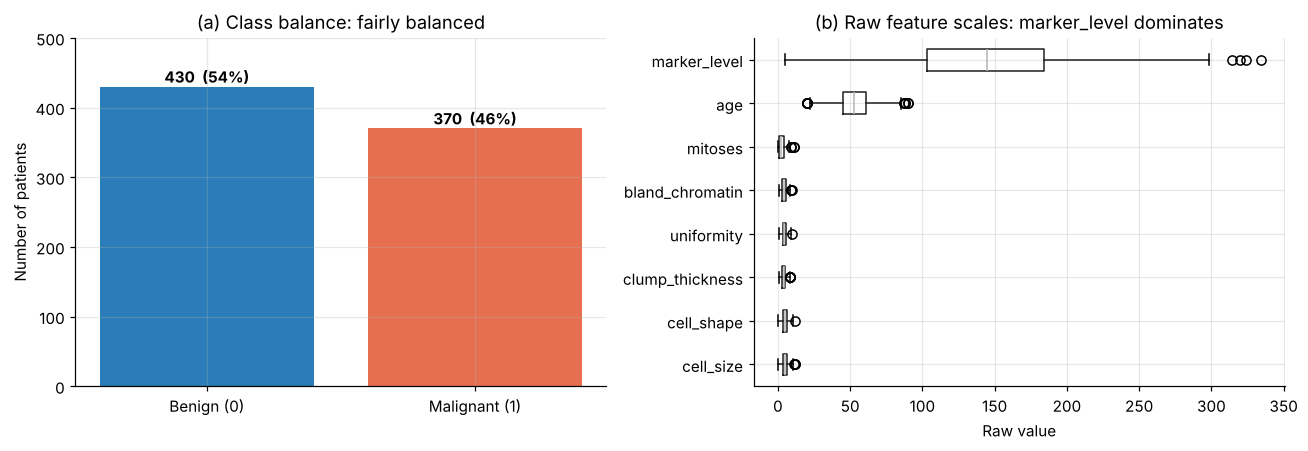

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
counts = df['diagnosis'].value_counts().sort_index()
bars = axes[0].bar(CLASS_NAMES, counts.values, color=[BENIGN_C, MALIG_C])
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width()/2, v + 6, f"{v}  ({v/len(df):.0%})", ha='center', fontweight='bold')
axes[0].set_ylim(0, 500); axes[0].set_ylabel('Number of patients'); axes[0].set_title('(a) Class balance: fairly balanced')
df[features].boxplot(ax=axes[1], vert=False)
axes[1].set_xlabel('Raw value'); axes[1].set_title('(b) Raw feature scales: marker_level dominates')
plt.tight_layout(); plt.show()

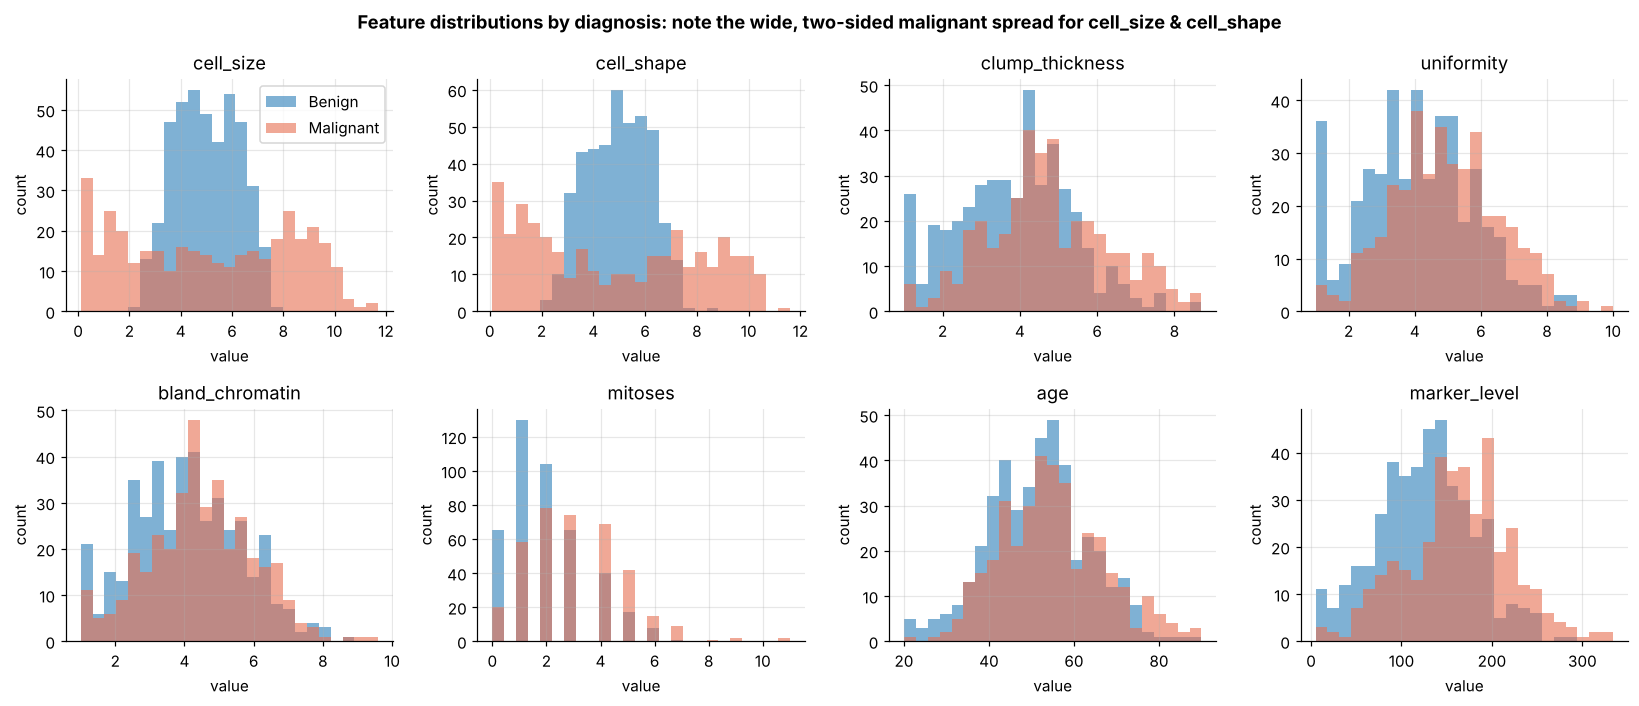

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, f in zip(axes.ravel(), features):
    bins = np.histogram_bin_edges(df[f], bins=25)
    ax.hist(df.loc[df.diagnosis == 0, f], bins=bins, alpha=.6, color=BENIGN_C, label='Benign')
    ax.hist(df.loc[df.diagnosis == 1, f], bins=bins, alpha=.6, color=MALIG_C, label='Malignant')
    ax.set_title(f); ax.set_xlabel('value'); ax.set_ylabel('count')
axes[0, 0].legend()
plt.suptitle('Feature distributions by diagnosis: note the wide, two-sided malignant spread for cell_size & cell_shape',
             fontweight='bold'); plt.tight_layout(); plt.show()

### A3. The correlation puzzle

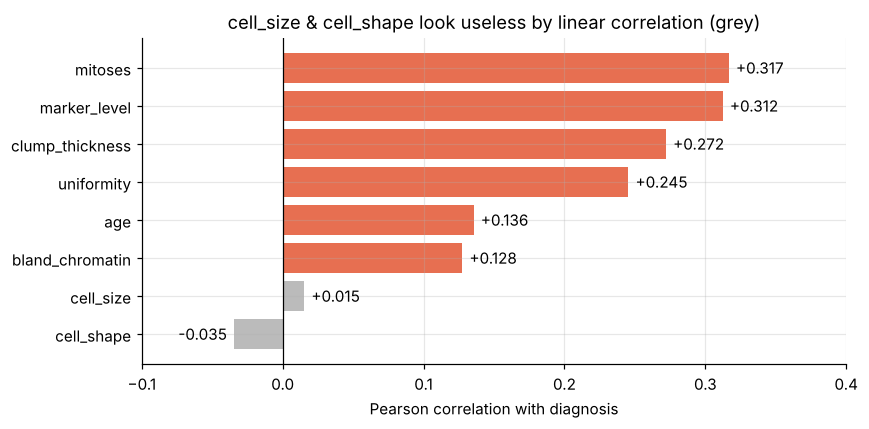

In [8]:
corr = df[features].corrwith(df['diagnosis']).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(corr.index, corr.values, color=['#BBBBBB' if abs(v) < .05 else MALIG_C for v in corr.values])
for i, v in enumerate(corr.values):
    ax.text(v + (0.005 if v >= 0 else -0.005), i, f"{v:+.3f}", va='center', ha='left' if v >= 0 else 'right')
ax.axvline(0, color='k', lw=.8); ax.set_xlim(-0.1, 0.4)
ax.set_xlabel('Pearson correlation with diagnosis')
ax.set_title('cell_size & cell_shape look useless by linear correlation (grey)')
plt.tight_layout(); plt.show()

### A4. Train/test split

In [9]:
X = df.drop(columns=['patient_id', 'diagnosis'])
y = df['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

split_tbl = pd.DataFrame({'Patients': [len(y_train), len(y_test)],
                          'Benign': [(y_train == 0).sum(), (y_test == 0).sum()],
                          'Malignant': [(y_train == 1).sum(), (y_test == 1).sum()]},
                         index=['Train (75%)', 'Test (25%)'])
split_tbl['% Malignant'] = split_tbl['Malignant'] / split_tbl['Patients'] * 100
split_tbl.style.format({'% Malignant': '{:.1f}%'}).set_caption('Table A2 – Stratified split (same class mix in both sets)')

,Patients,Benign,Malignant,% Malignant
Train (75%),600,323,277,46.2%
Test (25%),200,107,93,46.5%


### A5. ⭐ Feature scaling

In [10]:
scaler = StandardScaler().fit(X_train)          # fit on TRAIN only: no information leaks from the test set
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

pd.DataFrame({'Mean before': X_train.mean(), 'Std before': X_train.std(),
              'Mean after': X_train_s.mean(0), 'Std after': X_train_s.std(0)}) \
  .style.format('{:.2f}').set_caption('Table A3 – Training features before and after StandardScaler')

,Mean before,Std before,Mean after,Std after
cell_size,5.06,2.40,0.00,1.00
cell_shape,4.95,2.41,0.00,1.00
clump_thickness,4.25,1.62,-0.00,1.00
uniformity,4.48,1.69,-0.00,1.00
bland_chromatin,4.30,1.61,0.00,1.00
mitoses,2.41,1.70,-0.00,1.00
age,53.11,12.27,0.00,1.00
marker_level,145.36,59.45,-0.00,1.00


# PART B: See the shape of the problem

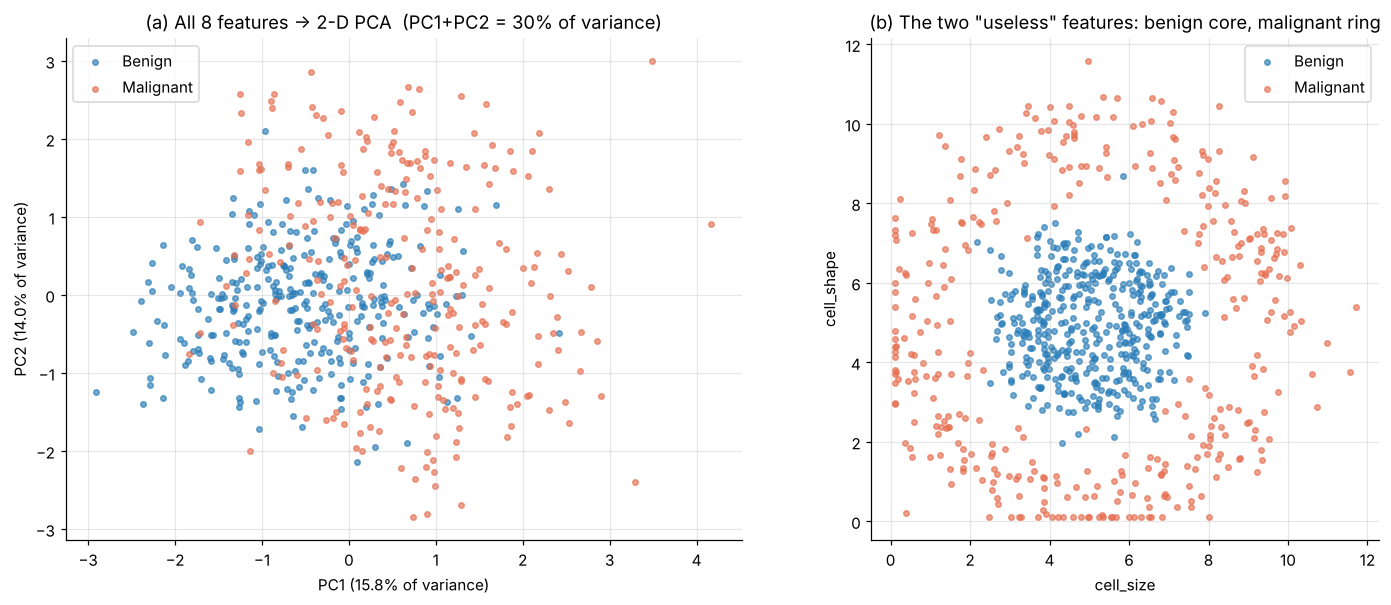

,PC1 loading,PC2 loading
cell_size,+0.017,+0.452
cell_shape,-0.206,+0.627
clump_thickness,+0.485,+0.117
uniformity,+0.430,+0.222
bland_chromatin,+0.260,-0.091
mitoses,+0.479,-0.287
age,+0.006,+0.426
marker_level,+0.490,+0.260


In [11]:
pca = PCA(n_components=2).fit(X_train_s)
p_tr, p_te = pca.transform(X_train_s), pca.transform(X_test_s)
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6))
ax = axes[0]
ax.scatter(p_tr[y_train == 0, 0], p_tr[y_train == 0, 1], s=13, c=BENIGN_C, alpha=.65, label='Benign')
ax.scatter(p_tr[y_train == 1, 0], p_tr[y_train == 1, 1], s=13, c=MALIG_C, alpha=.65, label='Malignant')
ax.set_xlabel(f'PC1 ({ev[0]:.1%} of variance)'); ax.set_ylabel(f'PC2 ({ev[1]:.1%} of variance)')
ax.set_title(f'(a) All 8 features → 2-D PCA  (PC1+PC2 = {ev.sum():.0%} of variance)'); ax.legend()

ax = axes[1]
ax.scatter(df.loc[df.diagnosis == 0, 'cell_size'], df.loc[df.diagnosis == 0, 'cell_shape'], s=13, c=BENIGN_C, alpha=.65, label='Benign')
ax.scatter(df.loc[df.diagnosis == 1, 'cell_size'], df.loc[df.diagnosis == 1, 'cell_shape'], s=13, c=MALIG_C, alpha=.65, label='Malignant')
ax.set_xlabel('cell_size'); ax.set_ylabel('cell_shape'); ax.set_aspect('equal')
ax.set_title('(b) The two "useless" features: benign core, malignant ring'); ax.legend()
plt.tight_layout(); plt.show()

pd.DataFrame(pca.components_.T, index=features, columns=['PC1 loading', 'PC2 loading']) \
  .style.format('{:+.3f}').background_gradient(cmap='RdBu_r', vmin=-.7, vmax=.7) \
  .set_caption('Table B1 – What each principal component is made of')

> **Reading the pictures (Reflection B)**
> - In the **PCA view (a)**, benign patients form a compact cluster on the left/centre and malignant patients spread *around* it. PC1 is mostly the "linear" features (`clump_thickness`, `mitoses`, `marker_level`, `uniformity`); PC2 is mostly `cell_shape`, `cell_size` and `age`. Since only ~30% of the variance survives, the pattern is blurred.
> - Plotting **`cell_size` vs `cell_shape` directly (b)** shows the true structure: **benign cells sit in a central disc and malignant cells form a ring around it.**
> - **No single straight line can separate a class that is surrounded by another.** The boundary we need is a **closed curve (circle)**. This also solves the correlation puzzle: moving away from the centre in *any* direction leads to malignancy, so the average straight-line trend is ≈0.

# PART C: The Model Bake-Off
All six models are trained on the **same scaled training set** and scored on the **same 200 test patients** with one shared evaluation function. Results are stored so Part D can compare them.

In [12]:
results, preds, scores, fitted = {}, {}, {}, {}

def get_scores(model, Xs):
    # continuous score for ROC/PR curves: probability if available, else SVM distance
    if hasattr(model, 'predict_proba'):
        try: return model.predict_proba(Xs)[:, 1]
        except AttributeError: pass
    return model.decision_function(Xs)

def evaluate(name, model, Xtr=None, Xte=None, verbose=True):
    Xtr = X_train_s if Xtr is None else Xtr
    Xte = X_test_s  if Xte is None else Xte
    t0 = time.time(); model.fit(Xtr, y_train); fit_s = time.time() - t0
    pred, sc = model.predict(Xte), get_scores(model, Xte)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    r = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, zero_division=0),
         'Recall (malignant)': recall_score(y_test, pred), 'Specificity': tn / (tn + fp),
         'F1': f1_score(y_test, pred), 'Balanced acc.': balanced_accuracy_score(y_test, pred),
         'MCC': matthews_corrcoef(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, sc),
         'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp, 'Fit time (s)': fit_s}
    results[name], preds[name], scores[name], fitted[name] = r, pred, sc, model
    if verbose:
        print(f"{name:20} accuracy={r['Accuracy']:.3f}  precision={r['Precision']:.3f}  "
              f"recall(malignant)={r['Recall (malignant)']:.3f}  F1={r['F1']:.3f}")
        print(f"{'':20} confusion [[TN FP][FN TP]] = [[{tn} {fp}] [{fn} {tp}]]   → missed cancers: {fn}, false alarms: {fp}")
    return r

CM_CMAP = matplotlib.colors.LinearSegmentedColormap.from_list('ms', ['#F4F8FB', '#8CC8C3', '#0E6E69'])
CM_VMAX = None   # set after the split: one shared colour scale for EVERY confusion matrix

def plot_cm(ax, y_pred, title, cmap=None):
    # Same colour map and SAME scale for every model, so a weak model never looks as strong as a good one.
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1]); pct = cm / cm.sum(1, keepdims=True)
    vmax = CM_VMAX or cm.sum(1).max()
    tags = np.array([['✓ TN', '△ FP (false alarm)'], ['⚠ FN (MISSED)', '✓ TP']])
    lab = np.array([[f"{tags[i, j]}\n{cm[i, j]} ({pct[i, j]:.0%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=lab, fmt='', cmap=CM_CMAP, vmin=0, vmax=vmax, cbar=False, ax=ax, linewidths=2,
                linecolor='white', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'],
                annot_kws={'fontsize': 9})
    for t in ax.texts:                       # readable ink on dark and light cells
        r_, c_ = int(t.get_position()[1]), int(t.get_position()[0])
        t.set_color('white' if cm[r_, c_] / vmax > 0.55 else NAVY)
    ax.add_patch(plt.Rectangle((0.03, 1.03), .94, .94, fill=False, edgecolor=CORAL, lw=3))          # FN cell
    ax.add_patch(plt.Rectangle((1.03, 0.03), .94, .94, fill=False, edgecolor=AMBER, lw=2, ls='--'))  # FP cell
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(title, fontsize=10); ax.grid(False)

def plot_bar(series, title, xlabel, color_pos=MALIG_C, color_neg=BENIGN_C):
    s = series.sort_values()
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(s.index, s.values, color=[color_pos if v > 0 else color_neg for v in s.values])
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v:+.2f} " if (s < 0).any() else f" {v:.3f}", va='center', ha='left' if v >= 0 else 'right')
    ax.axvline(0, color='k', lw=.8); ax.set_xlabel(xlabel); ax.set_title(title)
    plt.tight_layout(); plt.show()

# 2-feature view used to SHOW each model's boundary shape (cell_size × cell_shape, scaled)
CELL = [features.index('cell_size'), features.index('cell_shape')]
c_tr, c_te = X_train_s[:, CELL], X_test_s[:, CELL]
gx, gy = np.meshgrid(np.linspace(c_tr[:, 0].min() - .4, c_tr[:, 0].max() + .4, 300),
                     np.linspace(c_tr[:, 1].min() - .4, c_tr[:, 1].max() + .4, 300))
def plot_boundary(ax, model, title):
    m = clone(model).fit(c_tr, y_train)
    Z = m.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, Z, alpha=.18, levels=[-.5, .5, 1.5], colors=[BENIGN_C, MALIG_C])
    if len(np.unique(Z)) > 1:
        ax.contour(gx, gy, Z, levels=[.5], colors='k', linewidths=1.5)
    else:
        ax.text(.5, .97, f"No boundary: predicts {'Malignant' if Z.flat[0] else 'Benign'} everywhere", transform=ax.transAxes,
                ha='center', va='top', fontsize=8, fontweight='bold', bbox=dict(fc='white', ec=CORAL))
    ax.scatter(c_tr[y_train == 0, 0], c_tr[y_train == 0, 1], s=7, c=BENIGN_C, alpha=.7)
    ax.scatter(c_tr[y_train == 1, 0], c_tr[y_train == 1, 1], s=7, c=MALIG_C, alpha=.7, marker='D')
    acc = accuracy_score(y_test, m.predict(c_te))
    ax.set_title(f"{title}\n2-feature test accuracy = {acc:.3f}", fontsize=10)
    ax.set_xlabel('cell_size (scaled)'); ax.set_ylabel('cell_shape (scaled)'); ax.set_aspect('equal'); ax.grid(False)
    return acc

CM_VMAX = int(max((y_test == 0).sum(), (y_test == 1).sum()))

In [13]:
MODELS = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Naive Bayes':         GaussianNB(),
    'SVM linear':          SVC(kernel='linear'),
    'SVM RBF':             SVC(kernel='rbf', C=3),
    'Decision Tree':       DecisionTreeClassifier(max_depth=6, random_state=0),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=0),
}

## C1. Logistic Regression *(Mahi)*
A **linear** model: it learns one weight per feature and draws a **straight** boundary (a flat hyperplane in 8-D).

Logistic Regression  accuracy=0.730  precision=0.719  recall(malignant)=0.688  F1=0.703
                     confusion [[TN FP][FN TP]] = [[82 25] [29 64]]   → missed cancers: 29, false alarms: 25


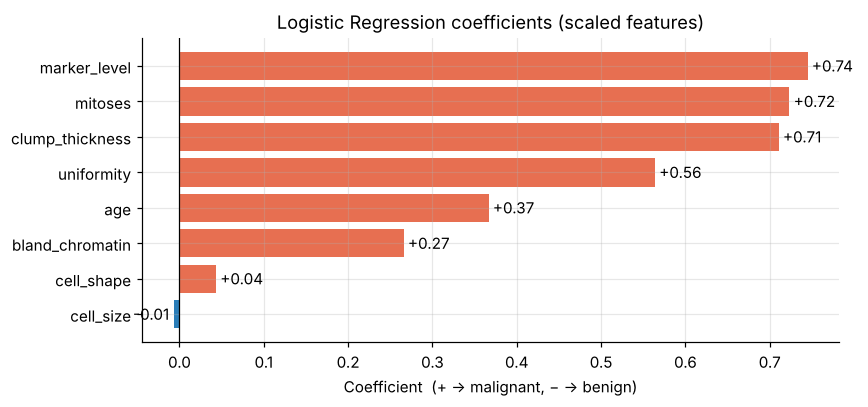

In [14]:
evaluate('Logistic Regression', MODELS['Logistic Regression'])
plot_bar(pd.Series(fitted['Logistic Regression'].coef_[0], index=features),
         'Logistic Regression coefficients (scaled features)', 'Coefficient  (+ → malignant, − → benign)')

> **Insight.** Logistic Regression only reaches ~73% accuracy and **misses 29 of 93 cancers**. It relies on `mitoses`, `marker_level`, `clump_thickness` and `uniformity` and gives `cell_size`/`cell_shape` near-zero weight. A straight line can't use a ring-shaped signal.

## C2. Gaussian Naive Bayes *(Shirley)*
Models each feature, for each class, as a bell curve with its **own mean and its own variance**, then applies Bayes' rule.

In [15]:
evaluate('Naive Bayes', MODELS['Naive Bayes'])
nb = fitted['Naive Bayes']
nb_var = nb.var_ if hasattr(nb, 'var_') else nb.sigma_
nb_tbl = pd.DataFrame({'Mean benign': nb.theta_[0], 'Mean malignant': nb.theta_[1],
                       'Std benign': np.sqrt(nb_var[0]), 'Std malignant': np.sqrt(nb_var[1])}, index=features)
nb_tbl['Std ratio (mal/ben)'] = nb_tbl['Std malignant'] / nb_tbl['Std benign']
nb_tbl.style.format('{:.2f}').background_gradient(subset=['Std ratio (mal/ben)'], cmap='Reds') \
      .set_caption('Table C2 – What Naive Bayes learned (scaled features)')

Naive Bayes          accuracy=0.960  precision=0.929  recall(malignant)=0.989  F1=0.958
                     confusion [[TN FP][FN TP]] = [[100 7] [1 92]]   → missed cancers: 1, false alarms: 7


,Mean benign,Mean malignant,Std benign,Std malignant,Std ratio (mal/ben)
cell_size,0.00,-0.00,0.52,1.36,2.60
cell_shape,-0.00,0.00,0.50,1.37,2.73
clump_thickness,-0.28,0.32,0.94,0.97,1.03
uniformity,-0.24,0.28,0.99,0.93,0.94
bland_chromatin,-0.12,0.13,0.97,1.01,1.04
mitoses,-0.28,0.32,0.87,1.04,1.20
age,-0.12,0.14,0.98,1.01,1.03
marker_level,-0.30,0.35,0.91,0.98,1.08


> **Insight: a surprise result.** It is tempting to file Naive Bayes with the "simple" straight-line models (the Student Guide pairs it with Logistic Regression), but here it performs **very well** (~96% accuracy, only **1 missed cancer**). Gaussian NB gives each class its *own variance*. For `cell_size` and `cell_shape`, the malignant variance is much larger than the benign one (Table C2). When two Gaussians share a centre but have different spreads, the boundary where they cross is a **circle/ellipse**, which matches the ring. So Gaussian NB is a **non-linear (quadratic) classifier** on this data. Its trade-off is more false alarms (precision ~0.93).

## C3. SVM: linear kernel *(Aradhana)*
Finds the **widest-margin straight hyperplane** between the classes.

SVM linear           accuracy=0.725  precision=0.711  recall(malignant)=0.688  F1=0.699
                     confusion [[TN FP][FN TP]] = [[81 26] [29 64]]   → missed cancers: 29, false alarms: 26
Support vectors: 353 of 600 training points (59%): a sign of heavy class overlap


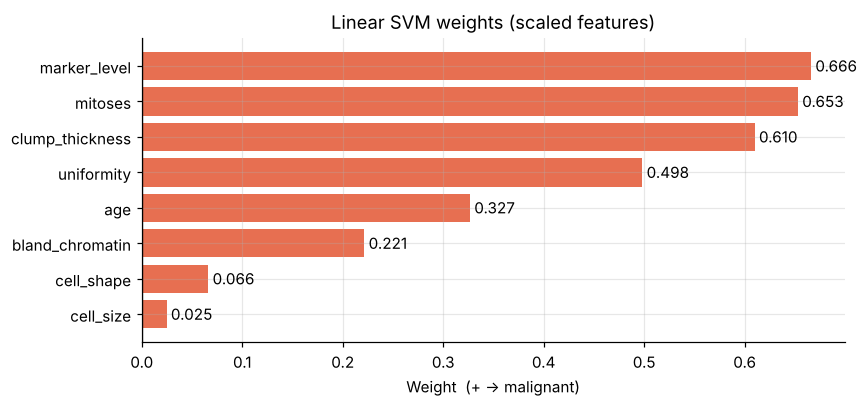

In [16]:
evaluate('SVM linear', MODELS['SVM linear'])
svl = fitted['SVM linear']
print(f"Support vectors: {svl.n_support_.sum()} of {len(y_train)} training points ({svl.n_support_.sum()/len(y_train):.0%}): a sign of heavy class overlap")
plot_bar(pd.Series(svl.coef_[0], index=features), 'Linear SVM weights (scaled features)', 'Weight  (+ → malignant)')

> **Insight.** Its results almost match Logistic Regression (~72.5%, **29 missed cancers**). Both are straight-line models, so they hit the same ceiling. About 59% of the training points become support vectors, a sign that no straight margin separates the data cleanly.

## C4. SVM: RBF kernel *(Shashaank)*
The RBF kernel measures **similarity by distance** between patients, which lets the SVM draw **curved, closed boundaries**.

SVM RBF              accuracy=0.970  precision=0.968  recall(malignant)=0.968  F1=0.968
                     confusion [[TN FP][FN TP]] = [[104 3] [3 90]]   → missed cancers: 3, false alarms: 3


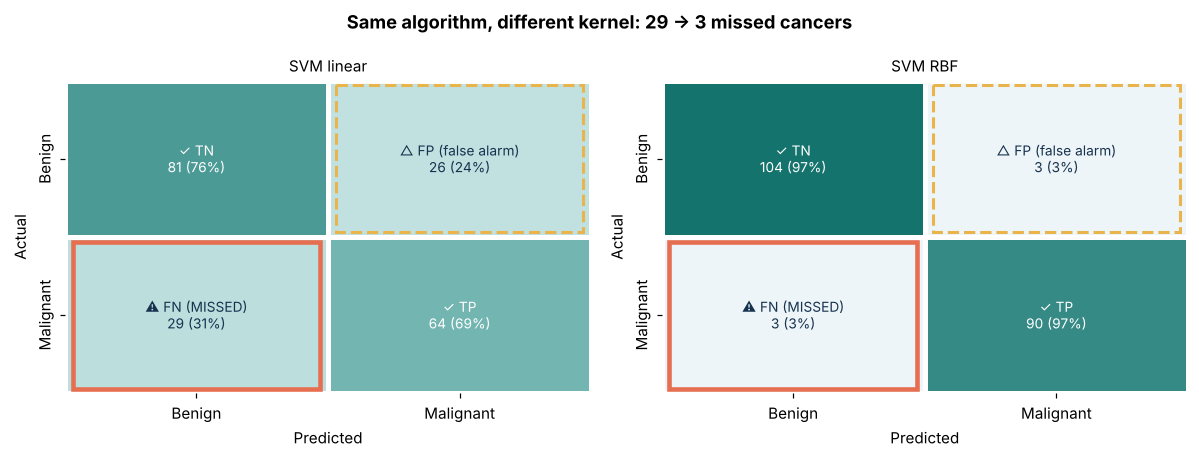

In [17]:
evaluate('SVM RBF', MODELS['SVM RBF'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
plot_cm(axes[0], preds['SVM linear'], 'SVM linear', 'Greys')
plot_cm(axes[1], preds['SVM RBF'], 'SVM RBF', 'Greens')
plt.suptitle('Same algorithm, different kernel: 29 → 3 missed cancers', fontweight='bold'); plt.tight_layout(); plt.show()

> **Insight.** Changing only the kernel lifts accuracy from **0.725 → 0.970** and cuts missed cancers from **29 → 3**. This is the lab's central lesson: the **kernel adds non-linearity**. It plays the same *role* as an activation function in a neural network (letting the boundary bend), but it is a different *mechanism*: the RBF kernel measures similarity between pairs of patients, whereas an activation function transforms each neuron's weighted input (see Part H).

## C5. Decision Tree *(Sparsh)*
Asks a sequence of yes/no questions ("is cell_size < x?"). Many axis-aligned cuts can **box in** the benign core.

Decision Tree        accuracy=0.975  precision=0.978  recall(malignant)=0.968  F1=0.973
                     confusion [[TN FP][FN TP]] = [[105 2] [3 90]]   → missed cancers: 3, false alarms: 2


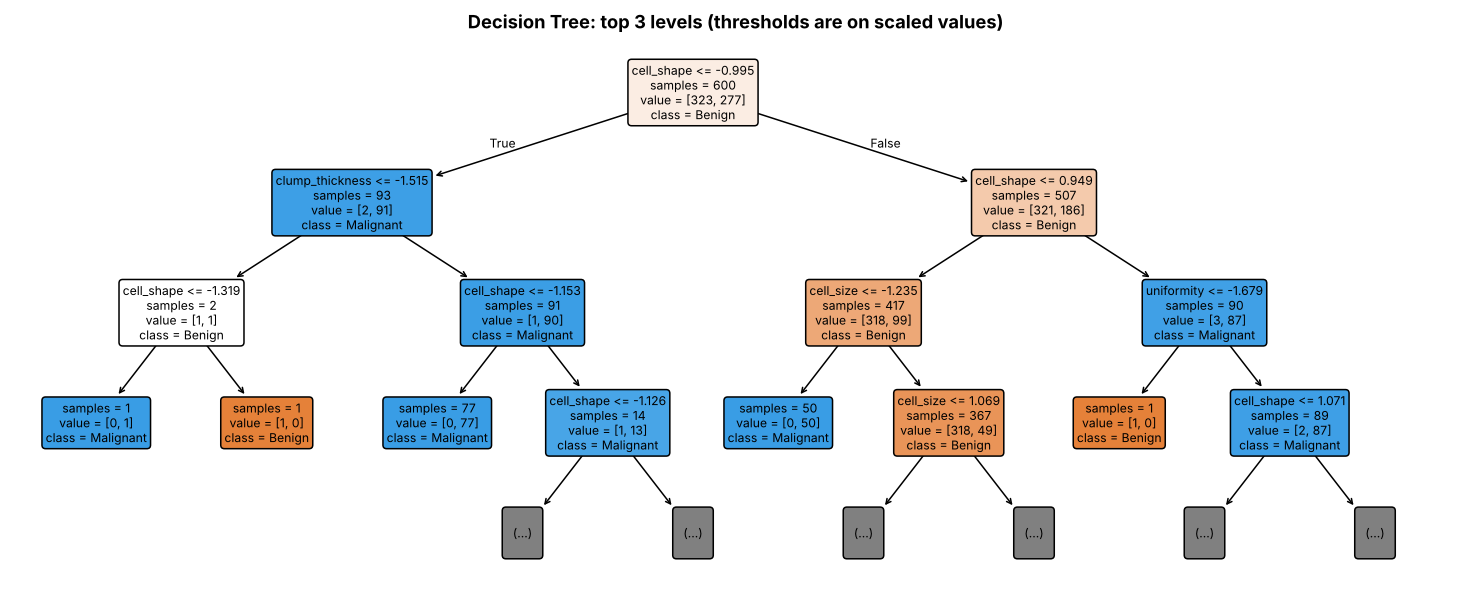

In [18]:
evaluate('Decision Tree', MODELS['Decision Tree'])
dt = fitted['Decision Tree']
fig, ax = plt.subplots(figsize=(17, 6.5))
plot_tree(dt, max_depth=3, feature_names=features, class_names=['Benign', 'Malignant'], filled=True,
          rounded=True, impurity=False, proportion=False, fontsize=8, ax=ax)
ax.set_title('Decision Tree: top 3 levels (thresholds are on scaled values)', fontweight='bold'); plt.show()

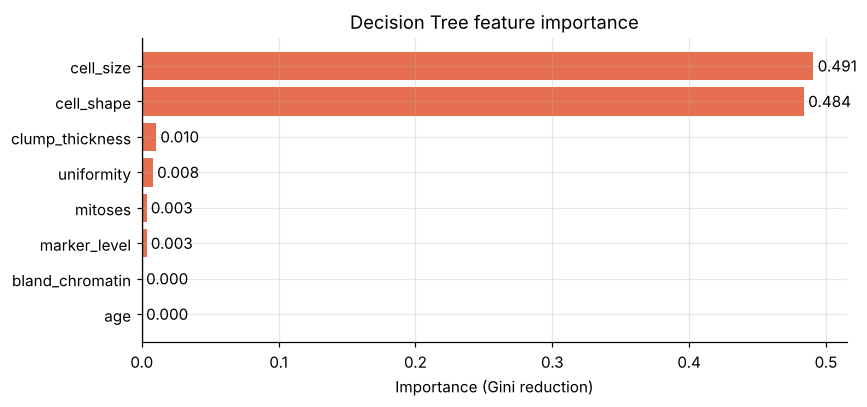

In [19]:
plot_bar(pd.Series(dt.feature_importances_, index=features), 'Decision Tree feature importance', 'Importance (Gini reduction)')

> **Insight.** The tree reaches ~97.5% accuracy with 3 missed cancers. Its top splits are dominated by `cell_shape` and `cell_size` (the root split and most of the next levels). It "cuts out" the central benign square with a few thresholds (cell_size between a and b *and* cell_shape between c and d). The two features that correlation called useless are the **most important** ones to the tree.

## C6. Random Forest *(Sparsh)*
An **ensemble of 200 decision trees**, each trained on a bootstrap sample with random feature subsets; their votes are averaged. This smooths the blocky single-tree boundary and reduces variance.

Random Forest        accuracy=0.975  precision=0.968  recall(malignant)=0.978  F1=0.973
                     confusion [[TN FP][FN TP]] = [[104 3] [2 91]]   → missed cancers: 2, false alarms: 3


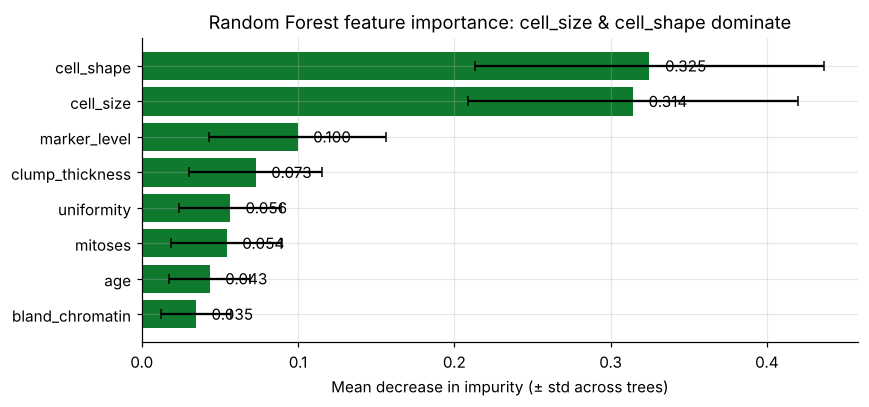

In [20]:
evaluate('Random Forest', MODELS['Random Forest'])
rf = fitted['Random Forest']
imp = pd.Series(rf.feature_importances_, index=features)
imp_std = np.std([t.feature_importances_ for t in rf.estimators_], axis=0)
order = imp.sort_values().index
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(order, imp[order], xerr=pd.Series(imp_std, index=features)[order], color=MODEL_COLORS['Random Forest'], capsize=3)
for i, v in enumerate(imp[order]): ax.text(v + .01, i, f"{v:.3f}", va='center')
ax.set_xlabel('Mean decrease in impurity (± std across trees)')
ax.set_title('Random Forest feature importance: cell_size & cell_shape dominate'); plt.tight_layout(); plt.show()

> **Insight.** Random Forest is one of the strongest single models (~97.5% accuracy, **2 missed cancers**) and has the best cross-validated accuracy (Part D). Its importance ranking is the **opposite of the correlation ranking** from Part A: `cell_size` and `cell_shape` come out on top. That settles the correlation puzzle.

## C7. All six models at a glance

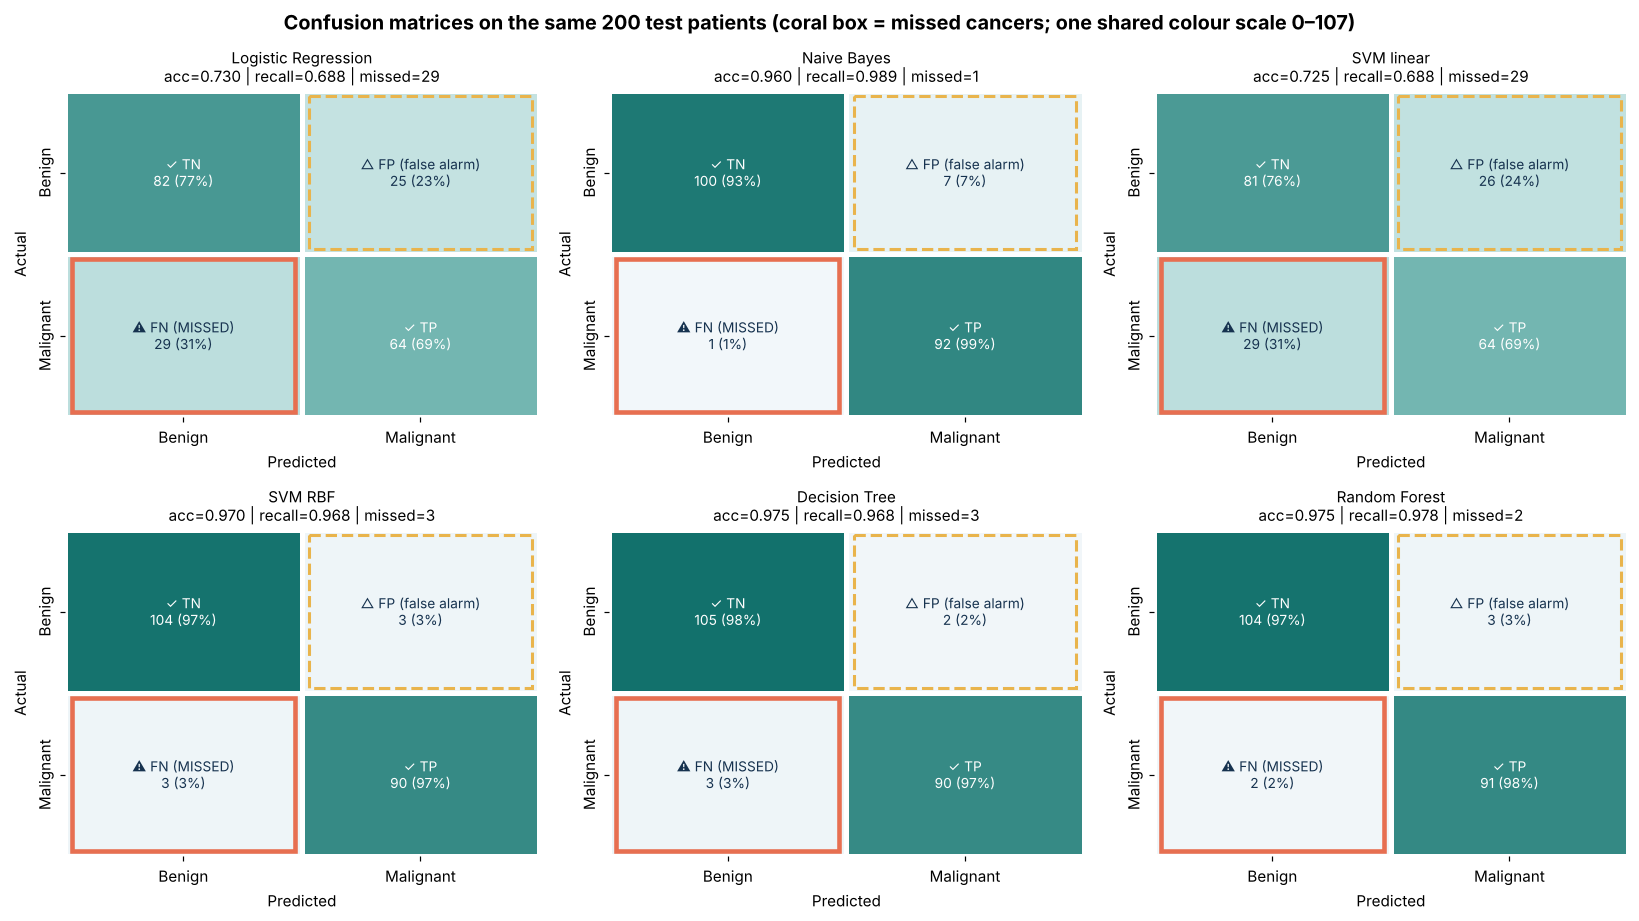

In [21]:
cmaps = {}   # (kept for compatibility) every matrix now uses ONE colour map and ONE scale
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, name in zip(axes.ravel(), MODELS):
    r = results[name]
    plot_cm(ax, preds[name], f"{name}\nacc={r['Accuracy']:.3f} | recall={r['Recall (malignant)']:.3f} | missed={r['FN']}")
plt.suptitle(f'Confusion matrices on the same 200 test patients (coral box = missed cancers; one shared colour scale 0–{CM_VMAX})',
             fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()

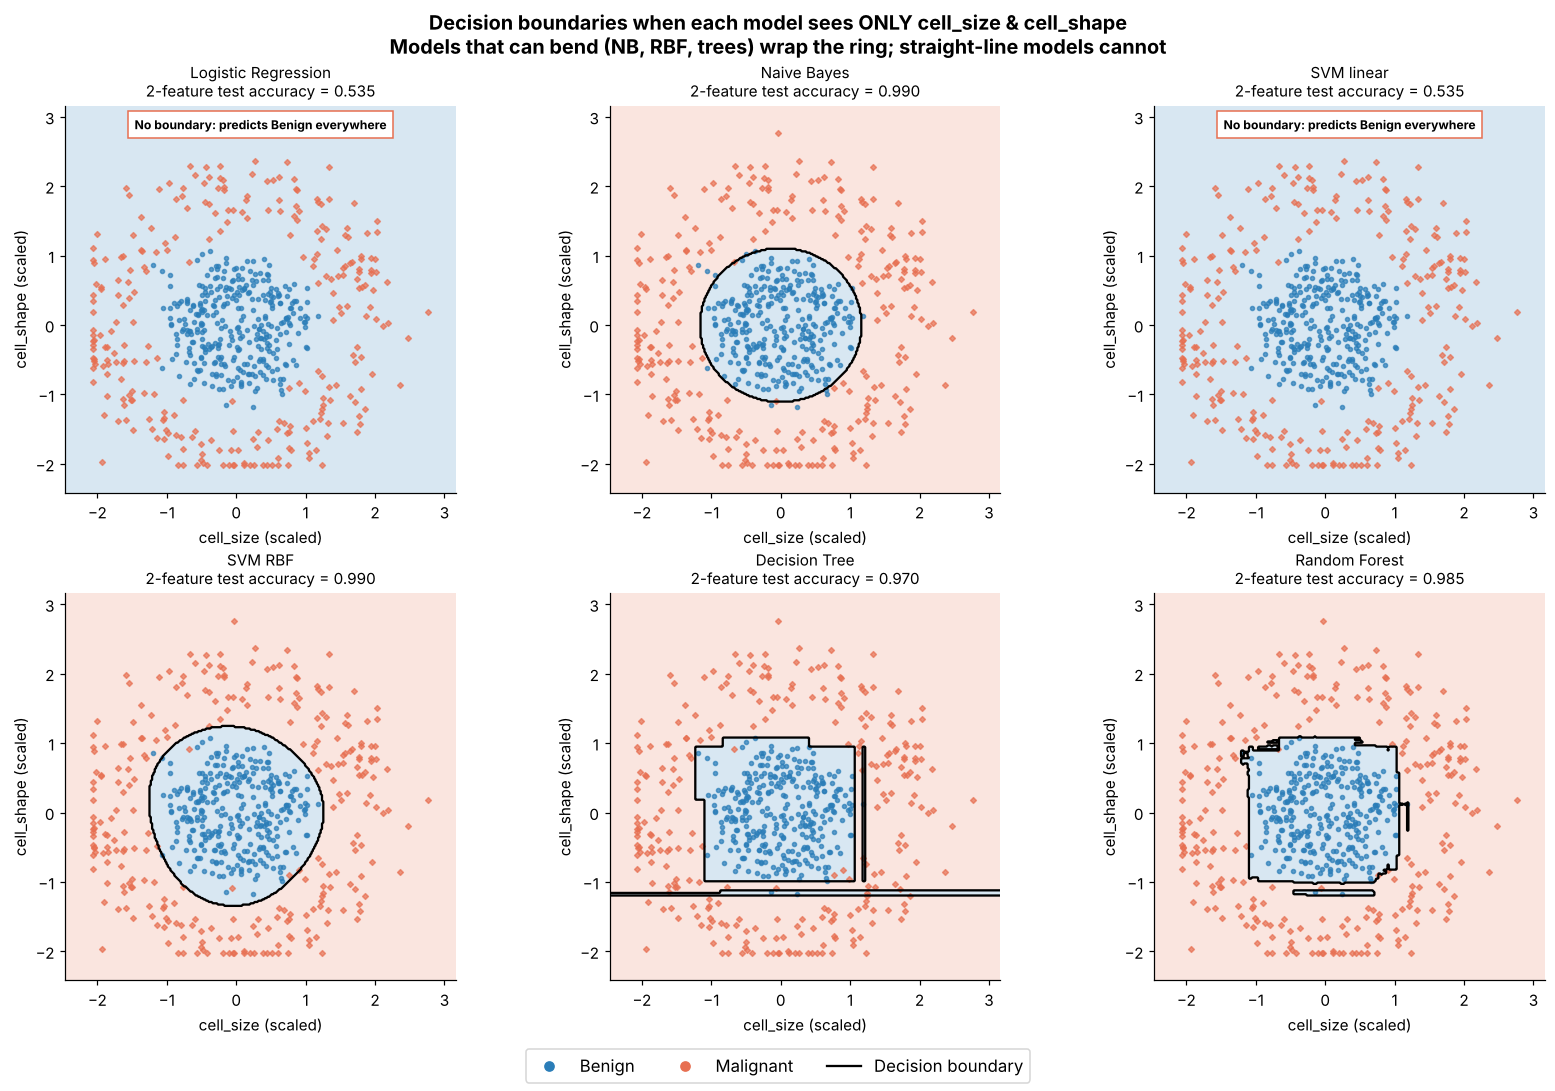

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, name in zip(axes.ravel(), MODELS):
    plot_boundary(ax, MODELS[name], name)
handles = [Line2D([], [], marker='o', ls='', color=BENIGN_C, label='Benign'),
           Line2D([], [], marker='o', ls='', color=MALIG_C, label='Malignant'),
           Line2D([], [], color='k', label='Decision boundary')]
fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=11)
plt.suptitle('Decision boundaries when each model sees ONLY cell_size & cell_shape\n'
             'Models that can bend (NB, RBF, trees) wrap the ring; straight-line models cannot',
             fontweight='bold', fontsize=13)
plt.tight_layout(rect=[0, .04, 1, 1]); plt.show()

> **The key picture.** Given only the two ring features:
> - **Logistic Regression** and **SVM linear** find no useful straight line, so they predict "benign" almost everywhere (≈ the benign share of patients).
> - **Naive Bayes** draws an **ellipse**, **SVM RBF** a smooth **closed curve**, and the **Decision Tree** / **Random Forest** a **box** of axis-aligned cuts. All four isolate the benign core.
>
> What the struggling models have in common: **they can only draw straight boundaries.** Every model that did well can **bend**.

# PART D: Leaderboard & the big lessons

### D1. Test-set leaderboard

In [23]:
lb = pd.DataFrame(results).T.astype(float)
lb['Boundary type'] = ['Straight (linear)', 'Curved (quadratic)', 'Straight (linear)',
                       'Curved (kernel)', 'Box-shaped (axis cuts)', 'Box-shaped, smoothed']
lb['Built by'] = [OWNER[n] for n in lb.index]
lb = lb.sort_values(['Recall (malignant)', 'Accuracy', 'FP'], ascending=[False, False, True])
# tie-aware rank on recall at the displayed precision: equal recall -> equal rank (1, 2, 3, 3, 5 …)
lb.insert(0, 'Rank', lb['Recall (malignant)'].round(3).rank(method='min', ascending=False).astype(int))
show_cols = ['Rank', 'Built by', 'Boundary type', 'Accuracy', 'Precision', 'Recall (malignant)', 'Specificity',
             'F1', 'ROC-AUC', 'MCC', 'FN', 'FP']
lb[show_cols].style \
  .format({**{c: '{:.3f}' for c in ['Accuracy', 'Precision', 'Recall (malignant)', 'Specificity', 'F1', 'ROC-AUC', 'MCC']},
           'FN': '{:.0f}', 'FP': '{:.0f}', 'Rank': '{:.0f}'}) \
  .background_gradient(subset=['Accuracy', 'Recall (malignant)', 'F1', 'ROC-AUC'], cmap='RdYlGn', vmin=.6, vmax=1) \
  .background_gradient(subset=['FN', 'FP'], cmap='RdYlGn_r', vmin=0, vmax=30) \
  .set_caption('Table D1 – LEADERBOARD (test set, n = 200; ranked by recall on malignant — ties share a rank — then accuracy)')

,Rank,Built by,Boundary type,Accuracy,Precision,Recall (malignant),Specificity,F1,ROC-AUC,MCC,FN,FP
Naive Bayes,1,Shirley,Curved (quadratic),0.960,0.929,0.989,0.935,0.958,0.997,0.922,1,7
Random Forest,2,Sparsh,"Box-shaped, smoothed",0.975,0.968,0.978,0.972,0.973,0.996,0.950,2,3
Decision Tree,3,Sparsh,Box-shaped (axis cuts),0.975,0.978,0.968,0.981,0.973,0.964,0.950,3,2
SVM RBF,3,Shashaank,Curved (kernel),0.970,0.968,0.968,0.972,0.968,0.998,0.940,3,3
Logistic Regression,5,Mahi,Straight (linear),0.730,0.719,0.688,0.766,0.703,0.799,0.456,29,25
SVM linear,5,Aradhana,Straight (linear),0.725,0.711,0.688,0.757,0.699,0.798,0.446,29,26


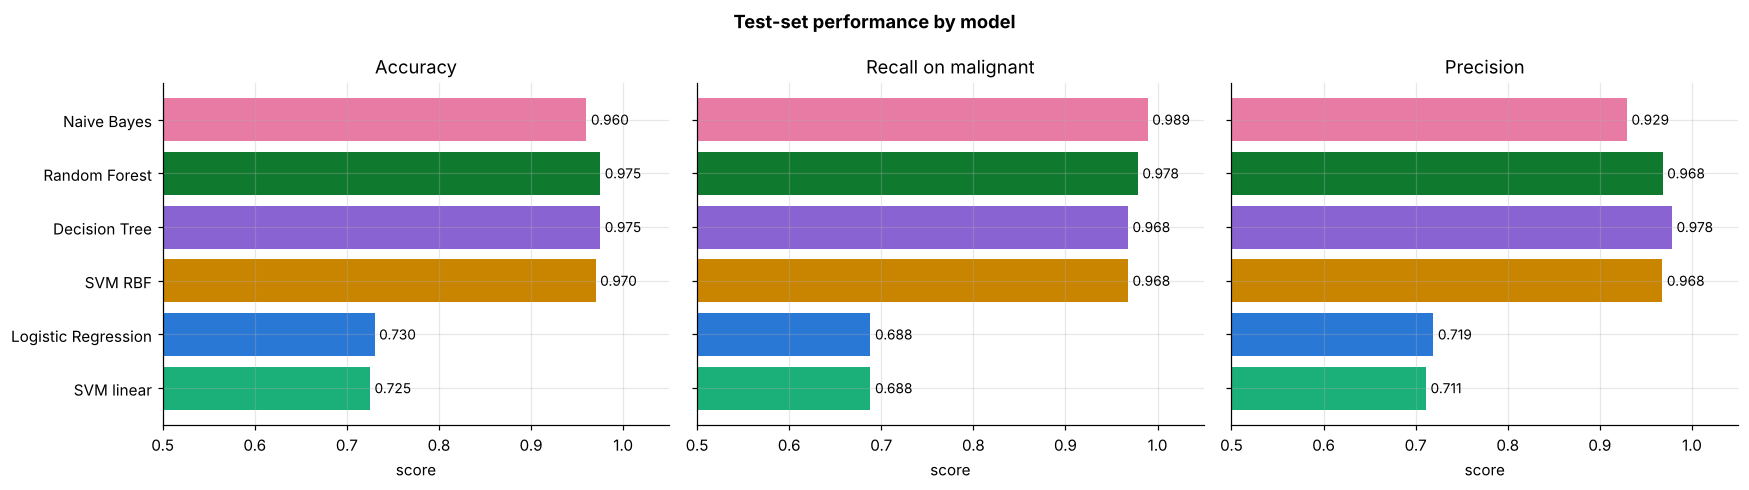

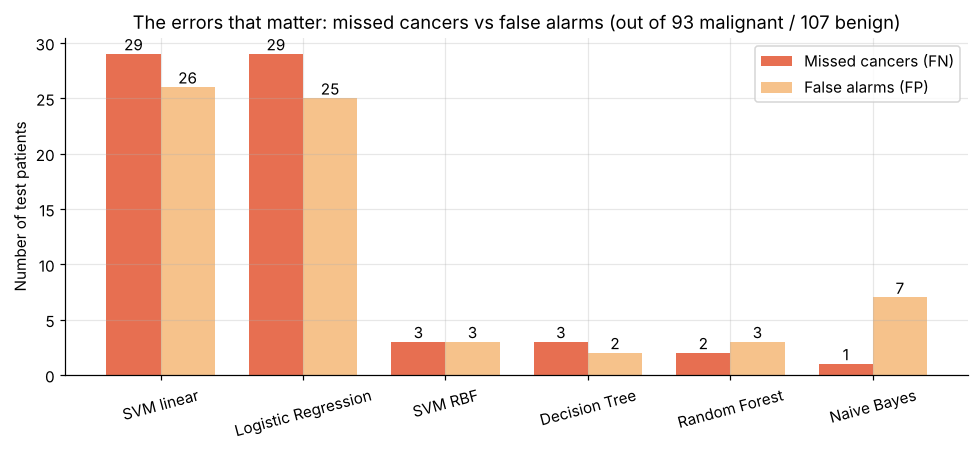

In [24]:
order = lb.index[::-1]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, metric, title in [(axes[0], 'Accuracy', 'Accuracy'), (axes[1], 'Recall (malignant)', 'Recall on malignant'),
                          (axes[2], 'Precision', 'Precision')]:
    vals = lb.loc[order, metric]
    ax.barh(order, vals, color=[MODEL_COLORS[m] for m in order])
    for i, v in enumerate(vals): ax.text(v + .005, i, f"{v:.3f}", va='center', fontsize=9)
    ax.set_xlim(0.5, 1.05); ax.set_title(title); ax.set_xlabel('score')
plt.suptitle('Test-set performance by model', fontweight='bold'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.2))
xi = np.arange(len(order)); w = .38
b1 = ax.bar(xi - w/2, lb.loc[order, 'FN'], w, color=MALIG_C, label='Missed cancers (FN)')
b2 = ax.bar(xi + w/2, lb.loc[order, 'FP'], w, color='#F6C28B', label='False alarms (FP)')
ax.bar_label(b1, fmt='%d'); ax.bar_label(b2, fmt='%d')
ax.set_xticks(xi); ax.set_xticklabels(order, rotation=15); ax.set_ylabel('Number of test patients')
ax.set_title('The errors that matter: missed cancers vs false alarms (out of 93 malignant / 107 benign)')
ax.legend(); plt.tight_layout(); plt.show()

> **Reading Table D1.** The four non-linear models are separated by only **1–2 patients** on this 200-patient test set, so their order here is partly luck. Part D3 (cross-validation on 600 patients) and Part G give a more reliable ranking. The gap to the two linear models (29 missed cancers each) is real and large.

### D2. ROC and precision–recall curves

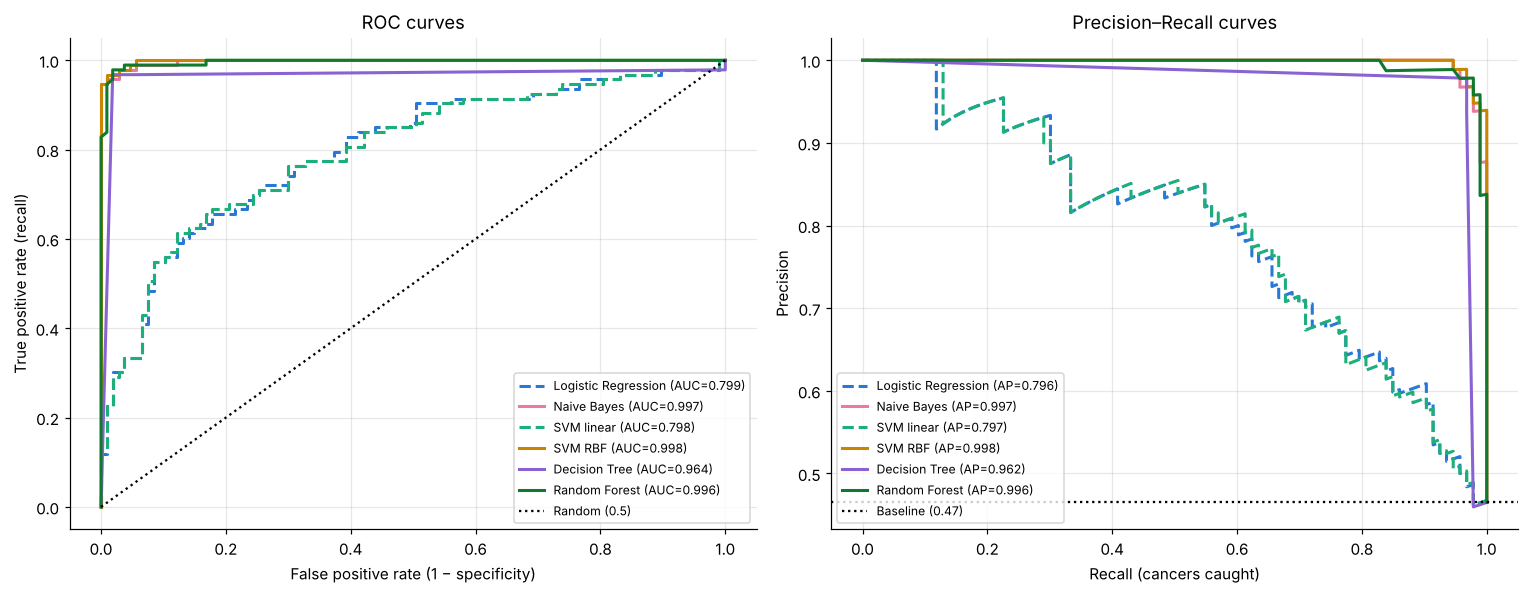

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name in MODELS:
    f, t, _ = roc_curve(y_test, scores[name])
    axes[0].plot(f, t, color=MODEL_COLORS[name], lw=2, ls='--' if 'linear' in name or 'Logistic' in name else '-',
                 label=f"{name} (AUC={results[name]['ROC-AUC']:.3f})")
    p, r, _ = precision_recall_curve(y_test, scores[name])
    axes[1].plot(r, p, color=MODEL_COLORS[name], lw=2, ls='--' if 'linear' in name or 'Logistic' in name else '-',
                 label=f"{name} (AP={average_precision_score(y_test, scores[name]):.3f})")
axes[0].plot([0, 1], [0, 1], 'k:', label='Random (0.5)')
axes[0].set_xlabel('False positive rate (1 − specificity)'); axes[0].set_ylabel('True positive rate (recall)')
axes[0].set_title('ROC curves'); axes[0].legend(fontsize=8, loc='lower right')
axes[1].axhline(y_test.mean(), color='k', ls=':', label=f'Baseline ({y_test.mean():.2f})')
axes[1].set_xlabel('Recall (cancers caught)'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision–Recall curves'); axes[1].legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()

In [26]:
auc = pd.Series({n: results[n]['ROC-AUC'] for n in MODELS})
curved = ['Naive Bayes', 'SVM RBF', 'Decision Tree', 'Random Forest']
hi = [n for n in curved if auc[n] >= 0.99]; lo_ = [n for n in curved if auc[n] < 0.99]
say(f"> **Insight.** The curved-boundary models rank patients far better than the straight-line ones: "
    + ", ".join(f"{n} (AUC {auc[n]:.3f})" for n in hi) + " sit in the top-left corner"
    + ("; " + ", ".join(f"**{n}** is lower (AUC {auc[n]:.3f})" for n in lo_)
       + " because a single depth-6 tree outputs only a handful of distinct leaf probabilities, so its ROC curve is a coarse staircase" if lo_ else "")
    + f". The two linear models (dashed) stay near AUC {auc[['Logistic Regression', 'SVM linear']].mean():.2f}. "
    "Moving their threshold can't fix them, because their *ranking* itself is weak.")

> **Insight.** The curved-boundary models rank patients far better than the straight-line ones: Naive Bayes (AUC 0.997), SVM RBF (AUC 0.998), Random Forest (AUC 0.996) sit in the top-left corner; **Decision Tree** is lower (AUC 0.964) because a single depth-6 tree outputs only a handful of distinct leaf probabilities, so its ROC curve is a coarse staircase. The two linear models (dashed) stay near AUC 0.80. Moving their threshold can't fix them, because their *ranking* itself is weak.

### D3. Cross-validated leaderboard (more reliable than one 200-patient test set)

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'Accuracy': 'accuracy', 'Precision': 'precision', 'Recall': 'recall', 'F1': 'f1', 'ROC-AUC': 'roc_auc'}
cv_rows = {}
for name, mdl in MODELS.items():
    # Leakage-safe: the scaler is refit INSIDE every fold (raw X_train in, Pipeline does the scaling)
    pipe = Pipeline([('scale', StandardScaler()), ('model', clone(mdl))])
    out = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {f'{k} mean': out[f'test_{k}'].mean() for k in scoring} | \
                    {f'{k} std': out[f'test_{k}'].std(ddof=1) for k in scoring}
cv_lb = pd.DataFrame(cv_rows).T.sort_values(['Recall mean', 'Accuracy mean'], ascending=False)
disp = pd.DataFrame({k: cv_lb[f'{k} mean'].map('{:.3f}'.format) + ' ± ' + cv_lb[f'{k} std'].map('{:.3f}'.format)
                     for k in scoring})
disp.style.set_caption('Table D3 – 5-fold stratified cross-validation on the training set (mean ± std; scaler refit per fold)')

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.983 ± 0.012,0.975 ± 0.016,0.989 ± 0.010,0.982 ± 0.013,0.996 ± 0.005
Naive Bayes,0.960 ± 0.022,0.933 ± 0.036,0.985 ± 0.015,0.958 ± 0.022,0.995 ± 0.004
SVM RBF,0.968 ± 0.016,0.981 ± 0.014,0.949 ± 0.027,0.965 ± 0.018,0.996 ± 0.003
Decision Tree,0.965 ± 0.011,0.974 ± 0.010,0.949 ± 0.020,0.961 ± 0.012,0.968 ± 0.017
Logistic Regression,0.750 ± 0.050,0.748 ± 0.075,0.700 ± 0.079,0.720 ± 0.056,0.817 ± 0.057
SVM linear,0.735 ± 0.049,0.731 ± 0.076,0.686 ± 0.059,0.705 ± 0.049,0.813 ± 0.053


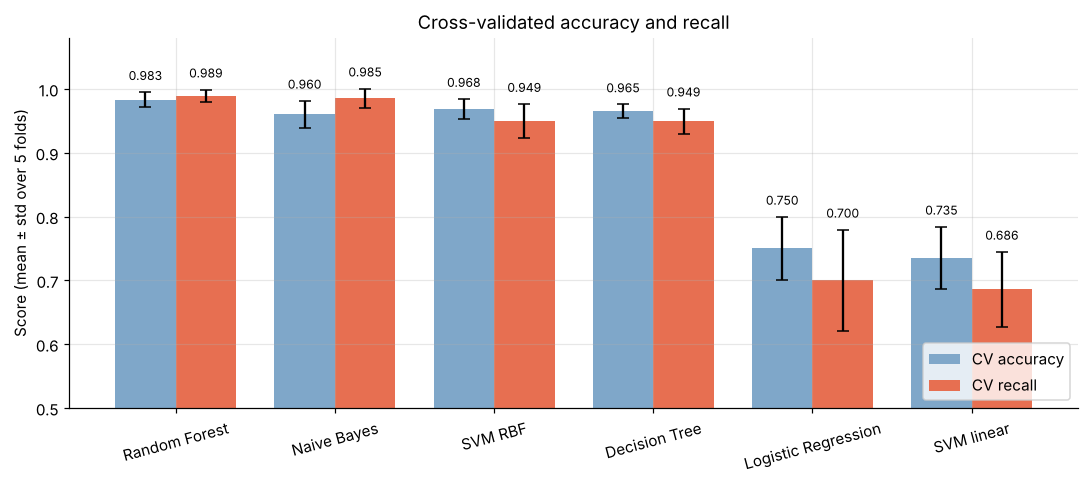

In [28]:
fig, ax = plt.subplots(figsize=(10, 4.5))
xi = np.arange(len(cv_lb)); w = .38
for off, k, c in [(-w/2, 'Accuracy', '#7FA7C9'), (w/2, 'Recall', MALIG_C)]:
    b = ax.bar(xi + off, cv_lb[f'{k} mean'], w, yerr=cv_lb[f'{k} std'], capsize=4, color=c, label=f'CV {k.lower()}')
    ax.bar_label(b, fmt='%.3f', fontsize=8, padding=6)
ax.set_xticks(xi); ax.set_xticklabels(cv_lb.index, rotation=15); ax.set_ylim(.5, 1.08)
ax.set_ylabel('Score (mean ± std over 5 folds)'); ax.set_title('Cross-validated accuracy and recall')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

### D4. How certain are the differences? Bootstrap 95% confidence intervals

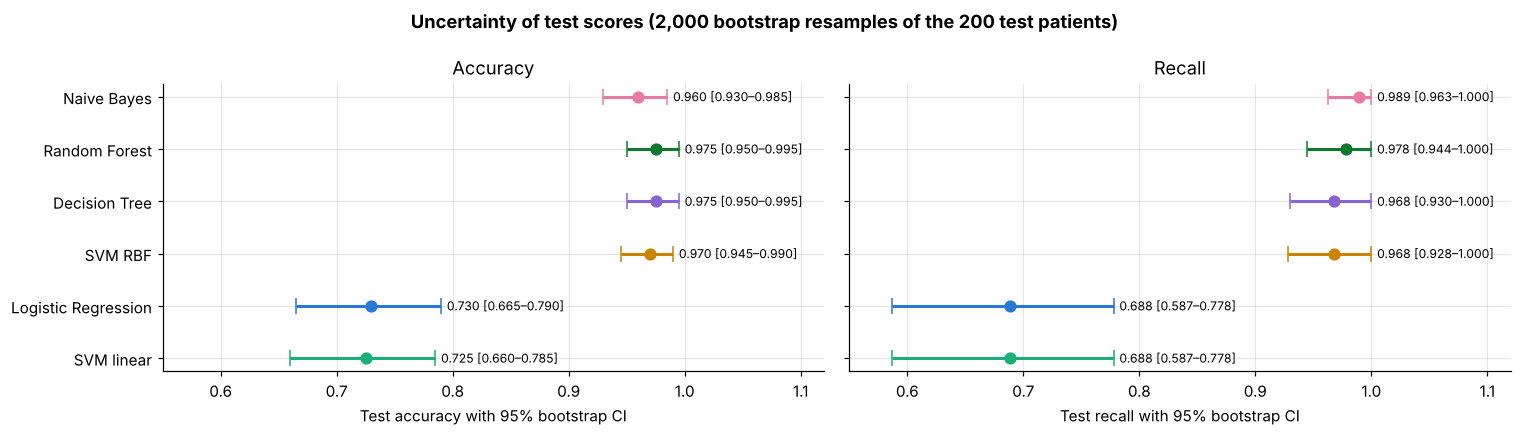

In [29]:
rng = np.random.default_rng(0); B = 2000
yt = y_test.values; boot = {n: {'Accuracy': [], 'Recall': []} for n in MODELS}
for _ in range(B):
    idx = rng.integers(0, len(yt), len(yt))
    for n in MODELS:
        boot[n]['Accuracy'].append(accuracy_score(yt[idx], preds[n][idx]))
        boot[n]['Recall'].append(recall_score(yt[idx], preds[n][idx]))
ci = pd.DataFrame({n: {f'{m} {q}': np.percentile(boot[n][m], p) for m in ['Accuracy', 'Recall']
                       for q, p in [('low', 2.5), ('high', 97.5)]} for n in MODELS}).T
ci['Accuracy'] = [results[n]['Accuracy'] for n in ci.index]; ci['Recall'] = [results[n]['Recall (malignant)'] for n in ci.index]
ci = ci.loc[lb.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, m in zip(axes, ['Accuracy', 'Recall']):
    for i, n in enumerate(ci.index[::-1]):
        ax.errorbar(ci.loc[n, m], i, xerr=[[ci.loc[n, m] - ci.loc[n, f'{m} low']], [ci.loc[n, f'{m} high'] - ci.loc[n, m]]],
                    fmt='o', color=MODEL_COLORS[n], capsize=5, lw=2, ms=7)
        ax.text(ci.loc[n, f'{m} high'] + .005, i, f"{ci.loc[n, m]:.3f} [{ci.loc[n, f'{m} low']:.3f}–{ci.loc[n, f'{m} high']:.3f}]",
                va='center', fontsize=8)
    ax.set_yticks(range(len(ci))); ax.set_yticklabels(ci.index[::-1]); ax.set_xlim(.55, 1.12)
    ax.set_xlabel(f'Test {m.lower()} with 95% bootstrap CI'); ax.set_title(m)
plt.suptitle('Uncertainty of test scores (2,000 bootstrap resamples of the 200 test patients)', fontweight='bold')
plt.tight_layout(); plt.show()

> **Insight.** The gap between linear and non-linear models (~0.72 vs ~0.96–0.98) is **huge and certain**: the confidence intervals don't come close to overlapping. Among the four good models, the intervals **overlap heavily**. On 200 patients, a difference of 1–2 missed cancers is within noise, so we also use cross-validation and the clinical cost (Part F) to choose.

### D5. ⭐ Does scaling matter? (every model, scaled vs unscaled)

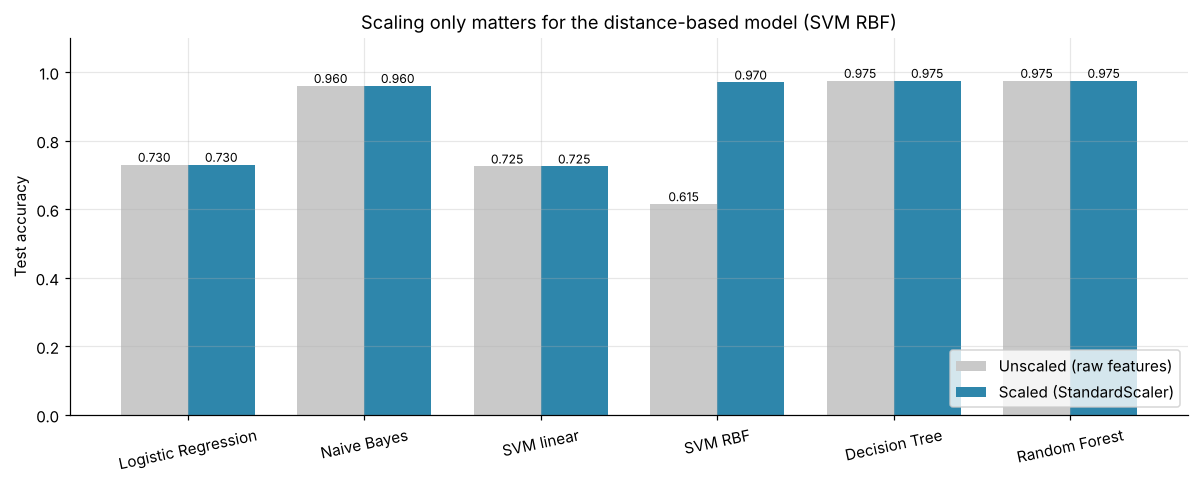

Data,Unscaled,Scaled,Change
Model,,,
Logistic Regression,0.730,0.730,+0.000
Naive Bayes,0.960,0.960,+0.000
SVM linear,0.725,0.725,+0.000
SVM RBF,0.615,0.970,+0.355
Decision Tree,0.975,0.975,+0.000
Random Forest,0.975,0.975,+0.000


In [30]:
rows = []
for name, mdl in MODELS.items():
    for label, Xtr, Xte in [('Unscaled', X_train.values, X_test.values), ('Scaled', X_train_s, X_test_s)]:
        m = clone(mdl); t0 = time.time(); m.fit(Xtr, y_train); t = time.time() - t0
        p = m.predict(Xte)
        rows.append({'Model': name, 'Data': label, 'Accuracy': accuracy_score(y_test, p),
                     'Recall': recall_score(y_test, p), 'FN': confusion_matrix(y_test, p)[1, 0], 'Fit time (s)': t})
scal = pd.DataFrame(rows)
piv = scal.pivot(index='Model', columns='Data', values='Accuracy')[['Unscaled', 'Scaled']].loc[list(MODELS)]
piv['Change'] = piv['Scaled'] - piv['Unscaled']

fig, ax = plt.subplots(figsize=(11, 4.5))
xi = np.arange(len(piv)); w = .38
b1 = ax.bar(xi - w/2, piv['Unscaled'], w, color='#C9C9C9', label='Unscaled (raw features)')
b2 = ax.bar(xi + w/2, piv['Scaled'], w, color='#2E86AB', label='Scaled (StandardScaler)')
ax.bar_label(b1, fmt='%.3f', fontsize=8); ax.bar_label(b2, fmt='%.3f', fontsize=8)
ax.set_xticks(xi); ax.set_xticklabels(piv.index, rotation=12); ax.set_ylim(0, 1.1); ax.set_ylabel('Test accuracy')
ax.set_title('Scaling only matters for the distance-based model (SVM RBF)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

piv.style.format('{:+.3f}', subset=['Change']).format('{:.3f}', subset=['Unscaled', 'Scaled']) \
   .background_gradient(subset=['Change'], cmap='Greens', vmin=0, vmax=.4) \
   .set_caption('Table D5 – Test accuracy with and without scaling')

> **Insight (Reflection D3).** Scaling transforms the **RBF SVM** (≈0.62 → 0.97) and changes nothing else.
> - **RBF SVM** measures Euclidean distance between patients. Unscaled, a 1-unit change in `marker_level` (range ~330) counts as much as a 1-unit change in `cell_size` (range ~12), so the marker drowns out the ring pattern.
> - **Trees and Random Forest** split one feature at a time on thresholds, so rescaling a feature doesn't change which split is best.
> - **Naive Bayes** models each feature separately, so a linear rescale doesn't change its decisions.
> - **Logistic Regression / linear SVM** can rescale their weights to compensate (unscaled data mainly makes optimisation slower).

### D6. ⭐ Are the differences statistically real?
D4's bootstrap intervals show the uncertainty of each model **on its own**. To compare two models properly we need a **paired** test: both models classify the *same* patients, so only the patients they **disagree** on carry information.

**McNemar's exact test.** For models A and B: **b** = patients A got right and B got wrong, **c** = the reverse. If the two models were equally good, disagreements would split 50/50, so b ~ Binomial(b + c, ½). With small counts we use the **exact** two-sided binomial p-value, and the **Holm–Bonferroni** correction because we test 15 pairs at once. We run it on all test patients (accuracy), malignant only (missed cancers) and benign only (false alarms).

subset,A,B,b,c,p,p_min,p_holm,"Significant (Holm, 5%)"
all,Naive Bayes,SVM RBF,2,4,0.688,0.031,1.000,no
all,Naive Bayes,Decision Tree,3,6,0.508,0.004,1.000,no
all,Naive Bayes,Random Forest,1,4,0.375,0.062,1.000,no
all,SVM RBF,Decision Tree,2,3,1.000,0.062,1.000,no
all,SVM RBF,Random Forest,1,2,1.000,0.250,1.000,no
all,Decision Tree,Random Forest,2,2,1.000,0.125,1.000,no
malignant,Naive Bayes,SVM RBF,2,0,0.500,0.500,1.000,no
malignant,Naive Bayes,Decision Tree,3,1,0.625,0.125,1.000,no
malignant,Naive Bayes,Random Forest,1,0,1.000,1.000,1.000,no
malignant,SVM RBF,Decision Tree,2,2,1.000,0.125,1.000,no


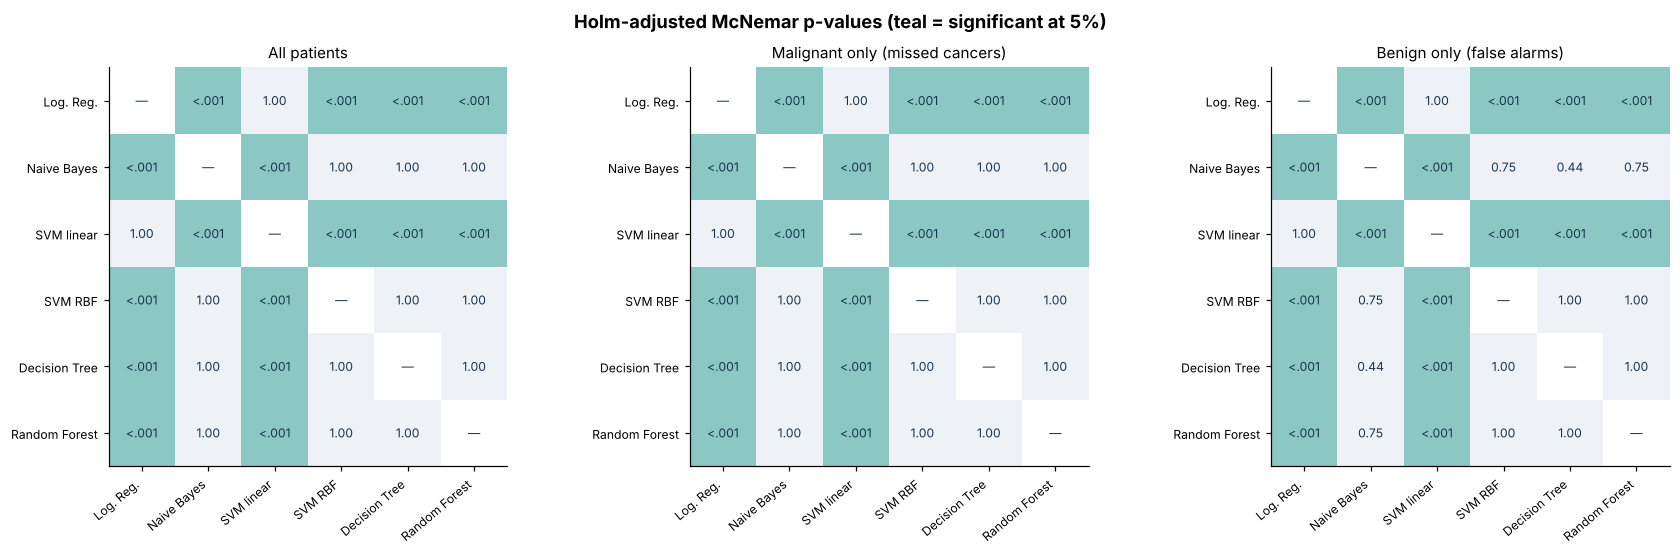

In [31]:
def mcnemar_exact(correct_a, correct_b):
    a, b_ = np.asarray(correct_a, bool), np.asarray(correct_b, bool)
    b, c = int((a & ~b_).sum()), int((~a & b_).sum()); n = b + c
    p = 1.0 if n == 0 else min(1.0, 2 * sps.binom.cdf(min(b, c), n, 0.5))
    p_min = 1.0 if n == 0 else min(1.0, 2 * 0.5 ** n)      # smallest p achievable with n disagreements
    return dict(b=b, c=c, p=p, p_min=p_min)

def holm(p):
    p = pd.Series(p); m = len(p); adj = pd.Series(index=p.index, dtype=float); run = 0.0
    for i, k in enumerate(p.sort_values().index):
        run = max(run, min(1.0, (m - i) * p[k])); adj[k] = run
    return adj

yt = y_test.to_numpy()
masks = {'all': np.ones_like(yt, bool), 'malignant': yt == 1, 'benign': yt == 0}
mc_parts = []
for subset, msk in masks.items():
    rows = [dict(subset=subset, A=a, B=b, **mcnemar_exact(preds[a][msk] == yt[msk], preds[b][msk] == yt[msk]))
            for a, b in itertools.combinations(MODELS, 2)]
    part = pd.DataFrame(rows); part['p_holm'] = holm(part['p']).values; mc_parts.append(part)
mcn = pd.concat(mc_parts, ignore_index=True)

LINEAR = {'Logistic Regression', 'SVM linear'}
STRONG = [m for m in MODELS if m not in LINEAR]
key = mcn[mcn.A.isin(STRONG) & mcn.B.isin(STRONG)].copy()
key['Significant (Holm, 5%)'] = np.where(key.p_holm < 0.05, '✱ yes', 'no')
display(key.style.format({'p': '{:.3f}', 'p_min': '{:.3f}', 'p_holm': '{:.3f}'}).hide(axis='index')
        .set_caption('Table D6a – McNemar tests among the four curved-boundary models (b = A right & B wrong, c = reverse)'))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
short_lab = [m.replace('Logistic Regression', 'Log. Reg.') for m in MODELS]
for ax, subset in zip(axes, masks):
    M = pd.DataFrame(np.nan, index=list(MODELS), columns=list(MODELS))
    for r in mcn[mcn.subset == subset].itertuples():
        M.loc[r.A, r.B] = M.loc[r.B, r.A] = r.p_holm
    ax.imshow(np.where(np.isnan(M.values), np.nan, M.values < 0.05),
              cmap=matplotlib.colors.ListedColormap(['#EEF2F6', '#8CC8C3']), vmin=0, vmax=1)
    for i in range(6):
        for j in range(6):
            v = M.values[i, j]
            ax.text(j, i, '—' if np.isnan(v) else ('<.001' if v < 0.001 else f'{v:.2f}'), ha='center', va='center',
                    fontsize=8, color=NAVY)
    ax.set_xticks(range(6), short_lab, rotation=40, ha='right', fontsize=8); ax.set_yticks(range(6), short_lab, fontsize=8)
    ax.grid(False)
    ax.set_title({'all': 'All patients', 'malignant': 'Malignant only (missed cancers)',
                  'benign': 'Benign only (false alarms)'}[subset], fontsize=10)
fig.suptitle('Holm-adjusted McNemar p-values (teal = significant at 5%)', fontweight='bold')
plt.tight_layout(); plt.show()

In [32]:
lc = mcn[mcn.A.isin(LINEAR) != mcn.B.isin(LINEAR)]
pair = mcn[(mcn.subset == 'malignant') & (mcn.A == 'Naive Bayes') & (mcn.B == 'Random Forest')].iloc[0]
say(f"> **Reading.** All **{(lc.p_holm < 0.05).sum()} of {len(lc)}** linear-vs-curved comparisons are significant even after "
    f"Holm adjustment (largest Holm p = {lc.p_holm.max():.4f}), but **{(key.p < 0.05).sum()} of {len(key)}** comparisons "
    "among the four curved models are significant, even before adjustment. For Naive Bayes vs Random Forest on the malignant "
    f"patients there {'is' if pair.b + pair.c == 1 else 'are'} only **{pair.b + pair.c} discordant patient"
    f"{'' if pair.b + pair.c == 1 else 's'}** (b = {pair.b}, c = {pair.c}), so the smallest p-value the test could ever produce "
    f"is **{pair.p_min:.2f}**. 'Not significant' here means *too few disagreements to tell*, not *proven equal*.")

> **Reading.** All **24 of 24** linear-vs-curved comparisons are significant even after Holm adjustment (largest Holm p = 0.0003), but **0 of 18** comparisons among the four curved models are significant, even before adjustment. For Naive Bayes vs Random Forest on the malignant patients there is only **1 discordant patient** (b = 1, c = 0), so the smallest p-value the test could ever produce is **1.00**. 'Not significant' here means *too few disagreements to tell*, not *proven equal*.

**Corrected resampled t-test.** A second view uses cross-validation on the 600 training patients. All models are scored on **identical** folds (5-fold × 3 repeats, same seed), so per-fold differences are paired. CV folds share training data, which makes a naive t-test over-confident; the **Nadeau–Bengio (2003)** correction inflates the variance by (1/J + n_test/n_train) = (1/15 + 120/480).

metric,A,B,mean_diff,ci_low,ci_high,t,p,p_holm
recall,Naive Bayes,SVM RBF,+3.1%,+0.3%,+5.9%,2.41,0.0302,0.1510
recall,Naive Bayes,Decision Tree,+3.9%,+0.4%,+7.3%,2.37,0.0325,0.1510
recall,Naive Bayes,Random Forest,-0.2%,-2.6%,+2.1%,-0.22,0.8277,1.0000
recall,SVM RBF,Decision Tree,+0.7%,-3.7%,+5.1%,0.35,0.7302,1.0000
recall,SVM RBF,Random Forest,-3.4%,-7.2%,+0.5%,-1.87,0.0824,0.2472
recall,Decision Tree,Random Forest,-4.1%,-6.3%,-1.9%,-3.93,0.0015,0.0091
specificity,Naive Bayes,SVM RBF,-3.9%,-7.1%,-0.7%,-2.62,0.0202,0.1214
specificity,Naive Bayes,Decision Tree,-2.8%,-7.0%,+1.4%,-1.41,0.1795,0.7182
specificity,Naive Bayes,Random Forest,-3.1%,-6.5%,+0.3%,-1.97,0.0695,0.3475
specificity,SVM RBF,Decision Tree,+1.1%,-0.8%,+3.1%,1.27,0.2261,0.7182


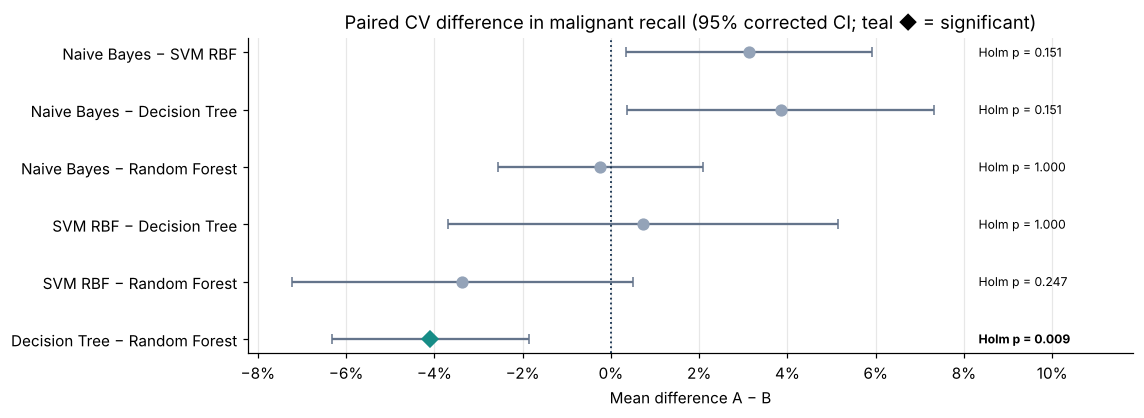

> **Reading.** Naive Bayes vs Random Forest: recall difference **-0.2%** (p = 0.83), so they are indistinguishable at catching cancers; specificity difference **-3.1%** (p = 0.070), so any edge is in false alarms. Recall differences that survive Holm correction: Random Forest > Decision Tree by 4.1% (Holm p 0.009).

In [33]:
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
def _spec(y_, p_):
    tn, fp, fn, tp = confusion_matrix(y_, p_, labels=[0, 1]).ravel(); return tn / (tn + fp)
SCORING_REP = {'accuracy': 'accuracy', 'recall': 'recall', 'precision': 'precision', 'specificity': make_scorer(_spec)}
cv_folds = {}
for name, mdl in MODELS.items():
    res = cross_validate(Pipeline([('scale', StandardScaler()), ('model', clone(mdl))]), X_train, y_train,
                         cv=cv_rep, scoring=SCORING_REP, n_jobs=-1)
    cv_folds[name] = {k: res[f'test_{k}'] for k in SCORING_REP}

def corrected_ttest(d, n_train, n_test):
    d = np.asarray(d, float); J = len(d); mean = d.mean(); var = d.var(ddof=1)
    se = np.sqrt((1 / J + n_test / n_train) * var)
    t = mean / se if se > 0 else 0.0
    p = 2 * sps.t.sf(abs(t), J - 1) if se > 0 else 1.0
    tc = sps.t.ppf(0.975, J - 1)
    return dict(mean_diff=mean, ci_low=mean - tc * se, ci_high=mean + tc * se, t=t, p=p)

tt_parts = []
for metric in ['recall', 'specificity', 'accuracy']:
    rows = [dict(metric=metric, A=a, B=b, **corrected_ttest(cv_folds[a][metric] - cv_folds[b][metric], 480, 120))
            for a, b in itertools.combinations(STRONG, 2)]
    part = pd.DataFrame(rows); part['p_holm'] = holm(part['p']).values; tt_parts.append(part)
ttest = pd.concat(tt_parts, ignore_index=True)
display(ttest.style.format({c: '{:+.1%}' for c in ['mean_diff', 'ci_low', 'ci_high']} |
                           {'t': '{:.2f}', 'p': '{:.4f}', 'p_holm': '{:.4f}'}).hide(axis='index')
        .set_caption('Table D6b – Corrected resampled t-tests among the curved models (difference A − B, 15 paired folds)'))

fig, ax = plt.subplots(figsize=(10.5, 3.9))
r_ = ttest[ttest.metric == 'recall'].iloc[::-1]
x_lab = r_.ci_high.max() + .01                       # one label column, clear of every interval
for k, row in enumerate(r_.itertuples()):
    sig = row.p_holm < 0.05
    ax.errorbar(row.mean_diff, k, xerr=[[row.mean_diff - row.ci_low], [row.ci_high - row.mean_diff]],
                fmt='D' if sig else 'o', color=TEAL if sig else '#94A3B8', ecolor='#64748B', capsize=3, ms=7)
    ax.text(x_lab, k, f"Holm p = {row.p_holm:.3f}", va='center', fontsize=8, fontweight='bold' if sig else 'normal')
ax.set_xlim(r_.ci_low.min() - .01, x_lab + .035)
ax.axvline(0, color=NAVY, ls=':', lw=1.2); ax.set_yticks(range(len(r_)), [f"{a} − {b}" for a, b in zip(r_.A, r_.B)])
ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(0.02))
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0)); ax.grid(axis='y', visible=False)
ax.set(title='Paired CV difference in malignant recall (95% corrected CI; teal ◆ = significant)', xlabel='Mean difference A − B')
plt.tight_layout(); plt.show()

nbrf = {m: ttest[(ttest.metric == m) & (ttest.A == 'Naive Bayes') & (ttest.B == 'Random Forest')].iloc[0] for m in ['recall', 'specificity']}
sig = ttest[(ttest.metric == 'recall') & (ttest.p_holm < 0.05)]
say(f"> **Reading.** Naive Bayes vs Random Forest: recall difference **{nbrf['recall'].mean_diff:+.1%}** "
    f"(p = {nbrf['recall'].p:.2f}), so they are indistinguishable at catching cancers; specificity difference "
    f"**{nbrf['specificity'].mean_diff:+.1%}** (p = {nbrf['specificity'].p:.3f}), so any edge is in false alarms. "
    + ("Recall differences that survive Holm correction: " + "; ".join(
        f"{r.A if r.mean_diff > 0 else r.B} > {r.B if r.mean_diff > 0 else r.A} by {abs(r.mean_diff):.1%} (Holm p {r.p_holm:.3f})"
        for r in sig.itertuples()) + "." if len(sig) else "No recall difference survives Holm correction."))

# PART E: Model combinations (ensembles)
Can we beat the best single model by **combining** models? Two ensemble styles:

| Method | How it works |
|---|---|
| **Soft voting** | Average the members' malignant probabilities; predict malignant if the average exceeds a threshold |
| **Stacking** | A Logistic Regression "meta-model" learns how much to trust each member, from out-of-fold predictions |

We test **every** soft-voting combination of 2, 3 and 4 of the six models (50), plus the six single models and one stacked ensemble: **57 candidates**.

**The protocol is fixed before looking at any result:**
1. **Leakage-safe members.** Each model is `StandardScaler → model`, refit inside every fold. SVMs get Platt calibration (`CalibratedClassifierCV`) so they can output probabilities.
2. **Soft vote = average of member probabilities.** Members are deterministic, so a vote's out-of-fold probability is *exactly* the mean of its members' out-of-fold probabilities (verified below against scikit-learn's `VotingClassifier`). All 50 combinations are then scored in seconds instead of minutes.
3. **Stage 1 — tune & shortlist.** On 5-fold out-of-fold predictions for the 600 training patients, give every candidate its own threshold from the grid 0.05, 0.10, …, 0.95 that minimises the clinical cost **10 × missed cancers + 1 × false alarm** (ties → higher threshold). Shortlist the 8 lowest-cost candidates, plus Random Forest as the reference.
4. **Stage 2 — fresh check.** Picking the best of 57 tuned candidates on the *same* folds flatters the winner. So the shortlist is re-scored on **10 new repetitions of 5-fold CV (a seed never used for selection)** with thresholds held fixed. The lowest mean cost wins.
5. **The test set is used once**, to report the finalists.

Decision rule everywhere: *malignant if P(malignant) > t*, which reproduces `predict()` at t = 0.5.

In [34]:
COST_FN, COST_FP = 10, 1                        # a missed cancer counts 10× a false alarm (illustrative; see Part F)
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.05), 2)
short = {'Logistic Regression': 'LR', 'Naive Bayes': 'NB', 'SVM linear': 'SVM-lin',
         'SVM RBF': 'SVM-RBF', 'Decision Tree': 'DT', 'Random Forest': 'RF'}
STACK_MEMBERS = ('Naive Bayes', 'SVM RBF', 'Random Forest')
STACK_NAME = 'Stack: NB + SVM-RBF + RF → LR'

def prob_model(name):
    # SVMs need calibrated probabilities to take part in soft voting and threshold tuning
    base = clone(MODELS[name])
    return CalibratedClassifierCV(base, cv=5, ensemble=False) if isinstance(base, SVC) else base

def member_pipe(name):
    return Pipeline([('scale', StandardScaler()), ('model', prob_model(name))])

def stack_pipe():
    st_ = StackingClassifier([(short[n], prob_model(n)) for n in STACK_MEMBERS],
                             final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method='predict_proba')
    return Pipeline([('scale', StandardScaler()), ('model', st_)])

def counts(y, p, t):                            # -> TP, FP, FN, TN for the rule P > t
    pred = np.asarray(p) > t; y = np.asarray(y).astype(bool)
    tp = int((pred & y).sum()); fp = int((pred & ~y).sum())
    return tp, fp, int(y.sum()) - tp, int((~y).sum()) - fp

def clinical_cost(fn, fp): return COST_FN * fn + COST_FP * fp

def best_threshold(y, p):                       # lowest cost on the grid; ties -> higher threshold
    best = min(((clinical_cost(counts(y, p, t)[2], counts(y, p, t)[1]), -t, t) for t in THRESHOLDS))
    t = best[2]; _, fp, fn, _ = counts(y, p, t)
    return float(t), fn, fp

yv = y_train.to_numpy()
t0 = time.time()
oof_p, test_p = {}, {}
for n in MODELS:                                # out-of-fold (stage-1 folds) and fitted-on-train test probabilities
    oof_p[n] = cross_val_predict(member_pipe(n), X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    test_p[n] = member_pipe(n).fit(X_train, y_train).predict_proba(X_test)[:, 1]
oof_p[STACK_NAME] = cross_val_predict(stack_pipe(), X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
test_p[STACK_NAME] = stack_pipe().fit(X_train, y_train).predict_proba(X_test)[:, 1]
print(f"Member and stacking probabilities computed in {time.time() - t0:.0f}s")

# Exactness check: a real VotingClassifier gives the same out-of-fold probabilities as averaging the members
for combo in [('Naive Bayes', 'SVM RBF', 'Random Forest'), ('Logistic Regression', 'Decision Tree')]:
    vote = Pipeline([('scale', StandardScaler()),
                     ('model', VotingClassifier([(short[n], prob_model(n)) for n in combo], voting='soft'))])
    real = cross_val_predict(vote, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    diff = np.abs(real - np.mean([oof_p[n] for n in combo], axis=0)).max()
    assert diff < 1e-9, diff
    print(f"VotingClassifier({' + '.join(short[n] for n in combo)}) vs averaged members: max |difference| = {diff:.1e}")

Member and stacking probabilities computed in 13s


VotingClassifier(NB + SVM-RBF + RF) vs averaged members: max |difference| = 0.0e+00
VotingClassifier(LR + DT) vs averaged members: max |difference| = 0.0e+00


In [35]:
label = lambda c: c[0] if len(c) == 1 else ' + '.join(short[m] for m in c)
rows = []
for c in [c for k in (1, 2, 3, 4) for c in itertools.combinations(MODELS, k)] + [(STACK_NAME,)]:
    is_stack = c == (STACK_NAME,)
    p = oof_p[STACK_NAME] if is_stack else np.mean([oof_p[m] for m in c], axis=0)
    _, fp0, fn0, _ = counts(yv, p, 0.5)
    t, fn, fp = best_threshold(yv, p)
    rows.append({'Candidate': STACK_NAME if is_stack else label(c), 'members': c, 'Size': len(c),
                 'Type': 'Stacking' if is_stack else ('Single model' if len(c) == 1 else 'Soft vote'),
                 'Has linear model': any(m in LINEAR for m in c),
                 'CV missed @0.5': fn0, 'CV false alarms @0.5': fp0, 'CV cost @0.5': clinical_cost(fn0, fp0),
                 'CV accuracy @0.5': 1 - (fn0 + fp0) / len(yv), 'CV recall @0.5': 1 - fn0 / yv.sum(),
                 'Tuned threshold': t, 'CV missed tuned': fn, 'CV false alarms tuned': fp, 'CV cost tuned': clinical_cost(fn, fp)})
combos = pd.DataFrame(rows).sort_values(['CV cost tuned', 'Size', 'Candidate']).reset_index(drop=True)
combos.insert(0, 'Stage-1 rank', combos['CV cost tuned'].rank(method='min').astype(int))
shortlist = combos.head(8)
if 'Random Forest' not in set(shortlist.Candidate):
    shortlist = pd.concat([shortlist, combos[combos.Candidate == 'Random Forest']])
print(f"Stage 1: {len(combos)} candidates scored ({(combos.Type == 'Soft vote').sum()} soft votes, "
      f"{(combos.Type == 'Single model').sum()} single models, {(combos.Type == 'Stacking').sum()} stack); "
      f"shortlist = {len(shortlist)}")
combos.drop(columns=['members', 'Has linear model']).head(12).style.hide(axis='index') \
   .format({'CV accuracy @0.5': '{:.3f}', 'CV recall @0.5': '{:.3f}', 'Tuned threshold': '{:.2f}'}) \
   .background_gradient(subset=['CV cost tuned'], cmap='Greens_r') \
   .set_caption('Table E1 – Top 12 of 57 candidates by cross-validated clinical cost at each candidate\'s own tuned threshold '
                '(600 training patients: 277 malignant, 323 benign)')

Stage 1: 57 candidates scored (50 soft votes, 6 single models, 1 stack); shortlist = 9


Stage-1 rank,Candidate,Size,Type,CV missed @0.5,CV false alarms @0.5,CV cost @0.5,CV accuracy @0.5,CV recall @0.5,Tuned threshold,CV missed tuned,CV false alarms tuned,CV cost tuned
1,NB + SVM-RBF + DT + RF,4,Soft vote,4,2,42,0.990,0.986,0.40,1,10,20
2,NB + SVM-RBF + RF,3,Soft vote,5,7,57,0.980,0.982,0.40,1,11,21
3,DT + RF,2,Soft vote,14,7,147,0.965,0.949,0.20,0,22,22
3,NB + DT + RF,3,Soft vote,5,6,56,0.982,0.982,0.30,0,22,22
5,Stack: NB + SVM-RBF + RF → LR,1,Stacking,6,6,66,0.980,0.978,0.20,1,14,24
5,SVM-RBF + DT + RF,3,Soft vote,6,5,65,0.982,0.978,0.25,1,14,24
7,NB + DT,2,Soft vote,12,7,127,0.968,0.957,0.30,1,15,25
7,NB + RF,2,Soft vote,4,9,49,0.978,0.986,0.45,1,15,25
7,NB + SVM-RBF + DT,3,Soft vote,5,2,52,0.988,0.982,0.45,2,5,25
10,SVM-RBF + RF,2,Soft vote,5,7,57,0.980,0.982,0.30,1,16,26


In [36]:
singles = combos[combos.Type == 'Single model'].sort_values('CV cost @0.5')
singles[['Candidate', 'CV accuracy @0.5', 'CV recall @0.5', 'CV missed @0.5', 'CV false alarms @0.5', 'CV cost @0.5',
         'Tuned threshold', 'CV cost tuned']].style.hide(axis='index') \
   .format({'CV accuracy @0.5': '{:.3f}', 'CV recall @0.5': '{:.3f}', 'Tuned threshold': '{:.2f}'}) \
   .set_caption('Table E2 – The six single models under the same protocol (SVMs use calibrated probabilities)')

Candidate,CV accuracy @0.5,CV recall @0.5,CV missed @0.5,CV false alarms @0.5,CV cost @0.5,Tuned threshold,CV cost tuned
Random Forest,0.983,0.989,3,7,37,0.40,28
Naive Bayes,0.960,0.986,4,20,60,0.45,57
SVM RBF,0.975,0.975,7,8,78,0.15,52
Decision Tree,0.965,0.949,14,7,147,0.05,129
Logistic Regression,0.750,0.700,83,67,897,0.15,297
SVM linear,0.733,0.690,86,74,934,0.10,312


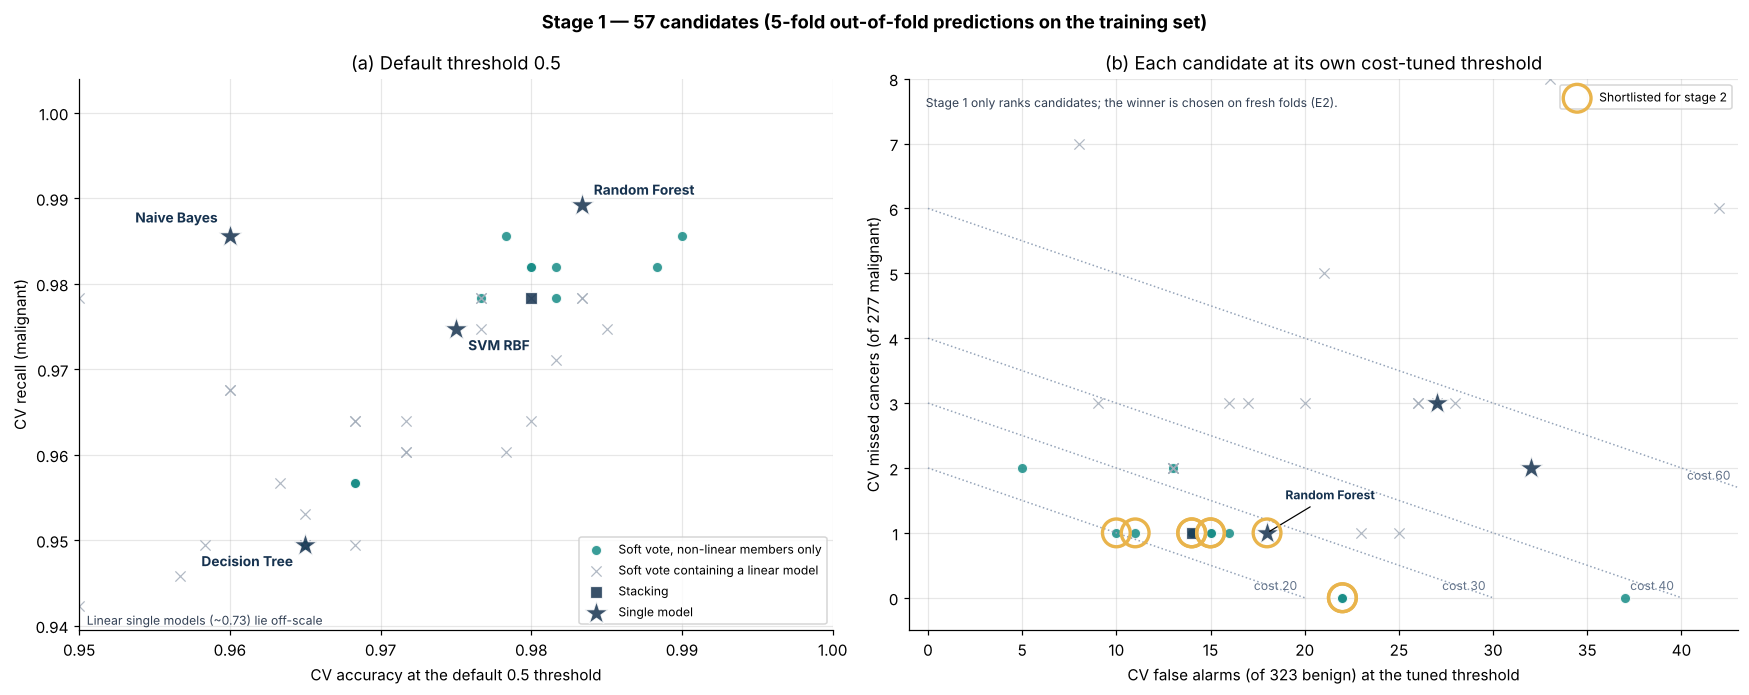

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4), gridspec_kw={'width_ratios': [1, 1.1]})
non_lin = combos[~combos['Has linear model']]
for ax_i, ax in enumerate(axes):
    for typ, has_lin, mk, col, size, lab in [('Soft vote', False, 'o', TEAL, 45, 'Soft vote, non-linear members only'),
                                             ('Soft vote', True, 'x', '#A3ADBA', 45, 'Soft vote containing a linear model'),
                                             ('Stacking', False, 's', NAVY, 70, 'Stacking'),
                                             ('Single model', False, '*', NAVY, 260, 'Single model')]:
        d = combos[(combos.Type == typ) & (combos['Has linear model'] == has_lin)]
        x, y = (d['CV accuracy @0.5'], d['CV recall @0.5']) if ax_i == 0 else (d['CV false alarms tuned'], d['CV missed tuned'])
        ax.scatter(x, y, marker=mk, s=size, c=col, alpha=.85, label=lab if ax_i == 0 else None,
                   edgecolor='white' if mk != 'x' else None, linewidth=.8, zorder=3 if typ != 'Soft vote' else 2)
# (a) label each single model with a hand-checked offset so no two labels collide
offs = {'Naive Bayes': (-8, 9, 'right'), 'Random Forest': (8, 7, 'left'), 'SVM RBF': (8, -14, 'left'), 'Decision Tree': (-8, -14, 'right')}
for _, r in singles[~singles['Has linear model']].iterrows():
    dx, dy, ha = offs.get(r.Candidate, (8, 8, 'left'))
    axes[0].annotate(r.Candidate, (r['CV accuracy @0.5'], r['CV recall @0.5']), xytext=(dx, dy), textcoords='offset points',
                     ha=ha, fontsize=9, fontweight='bold', color=NAVY)
lo = non_lin[['CV accuracy @0.5', 'CV recall @0.5']].min() - .01
axes[0].set(xlim=(lo.iloc[0], 1.0), ylim=(lo.iloc[1], 1.004), xlabel='CV accuracy at the default 0.5 threshold',
            ylabel='CV recall (malignant)', title='(a) Default threshold 0.5')
axes[0].legend(loc='lower right', fontsize=8)
axes[0].text(.01, .01, 'Linear single models (~0.73) lie off-scale', transform=axes[0].transAxes, fontsize=8, color=SLATE)
# (b) the tuned trade-off with iso-cost lines
xmax = non_lin['CV false alarms tuned'].max() + 6
for c in (20, 30, 40, 60):
    xs = np.linspace(0, min(c, xmax), 50); axes[1].plot(xs, (c - xs) / 10, ':', color='#94A3B8', lw=1)
    axes[1].text(min(c, xmax) - .4, max((c - min(c, xmax)) / 10, 0) + .12, f'cost {c}', fontsize=8, color='#64748B', ha='right')
sl = combos[combos.Candidate.isin(shortlist.Candidate)]
axes[1].scatter(sl['CV false alarms tuned'], sl['CV missed tuned'], s=330, facecolors='none', edgecolors=AMBER, lw=2.2,
                zorder=4, label='Shortlisted for stage 2')
rfp = combos[combos.Candidate == 'Random Forest'].iloc[0]
axes[1].annotate('Random Forest', (rfp['CV false alarms tuned'], rfp['CV missed tuned']), xytext=(12, 22),
                 textcoords='offset points', fontsize=8, fontweight='bold', color=NAVY, arrowprops=dict(arrowstyle='-', lw=.8))
axes[1].text(.02, .97, 'Stage 1 only ranks candidates; the winner is chosen on fresh folds (E2).', transform=axes[1].transAxes,
             fontsize=8, va='top', color=SLATE)
axes[1].set(xlim=(-1, xmax), ylim=(-.5, 8), xlabel='CV false alarms (of 323 benign) at the tuned threshold',
            ylabel='CV missed cancers (of 277 malignant)', title='(b) Each candidate at its own cost-tuned threshold')
axes[1].legend(loc='upper right', fontsize=8)
plt.suptitle('Stage 1 — 57 candidates (5-fold out-of-fold predictions on the training set)', fontweight='bold')
plt.tight_layout(); plt.show()

In [38]:
rf_c = combos[combos.Candidate == 'Random Forest'].iloc[0]
beat05 = combos[combos['CV cost @0.5'] < rf_c['CV cost @0.5']]
lin_best = combos[combos['Has linear model']]['CV cost @0.5'].min()
nl_best = combos[~combos['Has linear model'] & (combos.Size > 1)]['CV cost @0.5'].min()
say(f'''> **What the combination search shows**
> - **At the default 0.5 threshold, {'no candidate beats' if beat05.empty else f'{len(beat05)} candidate(s) beat'} Random Forest alone**
>   (CV cost {rf_c['CV cost @0.5']:.0f}: {rf_c['CV missed @0.5']} missed, {rf_c['CV false alarms @0.5']} false alarms). Combining models
>   only pays off once each candidate's **threshold is tuned** (panel b).
> - The best combinations mix **different kinds of curved boundary**: an ellipse (NB), a smooth kernel curve (SVM-RBF) and
>   axis-aligned boxes (DT/RF). Their errors fall in different places, so averaging gives better-separated probabilities and
>   the cut-off can be lowered at a smaller false-alarm price.
> - Adding a **linear model** almost always **hurts** (best CV cost {lin_best:.0f} with one, {nl_best:.0f} without): its
>   confidently wrong probabilities on ring patients drag the average toward "benign".
> - Stage 1 leader: **{combos.iloc[0].Candidate} @ {combos.iloc[0]['Tuned threshold']:.2f}** (cost {combos.iloc[0]['CV cost tuned']:.0f}).
>   But it was chosen *and* scored on the same folds, which is why stage 2 re-checks the shortlist on fresh folds.''')

> **What the combination search shows**
> - **At the default 0.5 threshold, no candidate beats Random Forest alone**
>   (CV cost 37: 3 missed, 7 false alarms). Combining models
>   only pays off once each candidate's **threshold is tuned** (panel b).
> - The best combinations mix **different kinds of curved boundary**: an ellipse (NB), a smooth kernel curve (SVM-RBF) and
>   axis-aligned boxes (DT/RF). Their errors fall in different places, so averaging gives better-separated probabilities and
>   the cut-off can be lowered at a smaller false-alarm price.
> - Adding a **linear model** almost always **hurts** (best CV cost 64 with one, 42 without): its
>   confidently wrong probabilities on ring patients drag the average toward "benign".
> - Stage 1 leader: **NB + SVM-RBF + DT + RF @ 0.40** (cost 20).
>   But it was chosen *and* scored on the same folds, which is why stage 2 re-checks the shortlist on fresh folds.

### E2. Stage 2 — re-check the shortlist on fresh cross-validation folds
10 new repetitions of 5-fold CV (seed 2026, never used for selection). Thresholds are **held fixed** at their stage-1 values. Each member is refit 50 times; soft votes again average the members' probabilities.

In [39]:
t0 = time.time()
fresh_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=2026)
splits = list(fresh_cv.split(X_train, y_train))

def _fit_fold(name, tr, te):
    pipe = (stack_pipe() if name == STACK_NAME else member_pipe(name)).fit(X_train.iloc[tr], y_train.iloc[tr])
    return name, te, pipe.predict_proba(X_train.iloc[te])[:, 1]

need = list(MODELS) + ([STACK_NAME] if STACK_NAME in set(shortlist.Candidate) else [])
res = Parallel(n_jobs=-1)(delayed(_fit_fold)(n, tr, te) for n in need for tr, te in splits)
fresh = {n: np.zeros((10, len(yv))) for n in need}
for i, (n, te, p) in enumerate(res):
    fresh[n][(i % len(splits)) // 5, te] = p
print(f"Fresh folds: {len(need)} models × {len(splits)} fits in {time.time() - t0:.0f}s")

def fresh_eval(members, t):
    P = np.mean([fresh[m] for m in members], axis=0)
    per_rep, per_fold = [], []
    for r in range(10):
        _, fp, fn, _ = counts(yv, P[r], t); per_rep.append((fn, fp, clinical_cost(fn, fp)))
        for f in range(5):
            te = splits[r * 5 + f][1]; _, fpf, fnf, _ = counts(yv[te], P[r, te], t)
            per_fold.append((fnf, fpf, clinical_cost(fnf, fpf)))
    return np.array(per_rep), np.array(per_fold)

s2_rows, per_fold = [], {}
for _, r in shortlist.iterrows():
    rep, pf = fresh_eval(r.members, r['Tuned threshold'])
    tp, fp, fn, tn = counts(yt, np.mean([test_p[m] for m in r.members], axis=0), r['Tuned threshold'])
    per_fold[r.Candidate] = pf
    s2_rows.append({'Candidate': r.Candidate, 'members': r.members, 'Size': r.Size, 'Type': r.Type,
                    'Threshold': r['Tuned threshold'], 'Stage-1 CV cost': r['CV cost tuned'],
                    'Fresh missed (mean)': rep[:, 0].mean(), 'Fresh false alarms (mean)': rep[:, 1].mean(),
                    'Fresh cost (mean)': rep[:, 2].mean(), 'Fresh cost (sd)': rep[:, 2].std(ddof=1), '_rep': rep[:, 2],
                    'Test missed': fn, 'Test false alarms': fp, 'Test cost': clinical_cost(fn, fp),
                    'Test accuracy': (tp + tn) / len(yt), 'Test recall': tp / (tp + fn)})
stage2 = pd.DataFrame(s2_rows).sort_values(['Fresh cost (mean)', 'Size']).reset_index(drop=True)
stage2.insert(0, 'Final rank', range(1, len(stage2) + 1))
WIN = stage2.iloc[0]; RFROW = stage2[stage2.Candidate == 'Random Forest'].iloc[0]
stage2['p vs winner'] = [np.nan if c == WIN.Candidate else
                         corrected_ttest(per_fold[c][:, 2] - per_fold[WIN.Candidate][:, 2], 480, 120)['p']
                         for c in stage2.Candidate]
stage2.drop(columns=['members', '_rep', 'Type']).style.hide(axis='index') \
   .format({'Threshold': '{:.2f}', 'Fresh missed (mean)': '{:.1f}', 'Fresh false alarms (mean)': '{:.1f}',
            'Fresh cost (mean)': '{:.1f}', 'Fresh cost (sd)': '{:.1f}', 'Test accuracy': '{:.3f}', 'Test recall': '{:.3f}',
            'p vs winner': lambda v: '—' if pd.isna(v) else f'{v:.2f}'}) \
   .background_gradient(subset=['Fresh cost (mean)'], cmap='Greens_r') \
   .set_caption('Table E3 – Stage 2: shortlist re-scored on 10 fresh repetitions of 5-fold CV (thresholds fixed), with the '
                'held-out test result and a corrected t-test against the winner')

Fresh folds: 7 models × 50 fits in 94s


Final rank,Candidate,Size,Threshold,Stage-1 CV cost,Fresh missed (mean),Fresh false alarms (mean),Fresh cost (mean),Fresh cost (sd),Test missed,Test false alarms,Test cost,Test accuracy,Test recall,p vs winner
1,NB + SVM-RBF + RF,3,0.40,21,1.7,10.4,27.4,8.6,1,7,17,0.960,0.989,—
2,NB + DT + RF,3,0.30,22,0.6,21.8,27.8,6.4,0,5,5,0.975,1.000,0.98
3,NB + DT,2,0.30,25,1.0,19.5,29.5,8.0,0,5,5,0.975,1.000,0.89
4,NB + SVM-RBF + DT + RF,4,0.40,20,1.9,11.6,30.6,9.5,1,2,12,0.985,0.989,0.87
5,SVM-RBF + DT + RF,3,0.25,24,1.3,17.9,30.9,10.4,1,5,15,0.970,0.989,0.83
6,Stack: NB + SVM-RBF + RF → LR,1,0.20,24,1.9,12.5,31.5,8.7,1,7,17,0.960,0.989,0.64
7,NB + RF,2,0.45,25,1.9,13.5,32.5,5.5,1,5,15,0.970,0.989,0.76
8,DT + RF,2,0.20,22,1.7,22.5,39.5,8.6,1,5,15,0.970,0.989,0.56
9,Random Forest,1,0.40,28,2.2,17.8,39.8,4.0,1,4,14,0.975,0.989,0.56


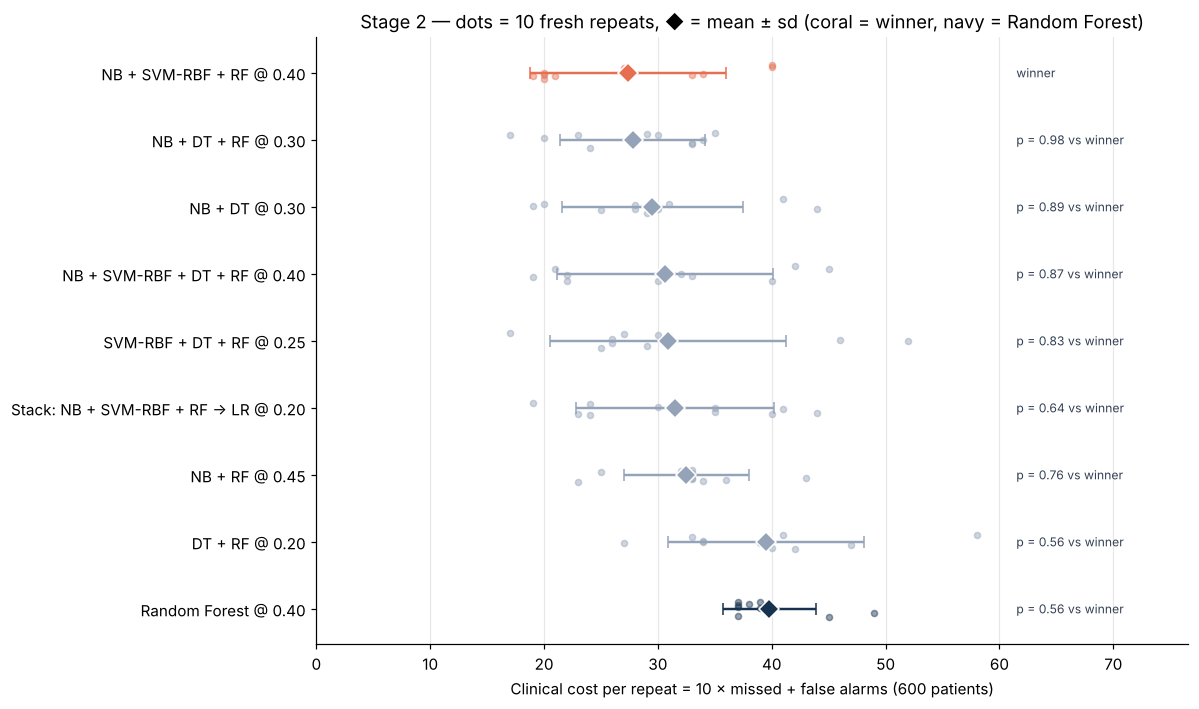

> **Reading stage 2.**
> - **Winner: NB + SVM-RBF + RF @ 0.40**, mean cost 27.4
>   (1.7 missed cancers and 10.4 false alarms per 600 patients), versus
>   39.8 for Random Forest @ 0.40 (2.2 missed,
>   17.8 false alarms). It is cheaper in **9 of 10** repeats.
> - **Where the gain comes from:** missed cancers differ by -0.10 per fold (p = 0.80),
>   false alarms by -1.48 per fold (p = 0.057); total cost p = 0.56.
>   So the ensemble catches cancers **as well as** Random Forest at its tuned threshold, with **fewer false alarms**, and that
>   advantage is **borderline, not conclusive**, after correcting for overlapping CV folds.
> - **Why stage 2 matters:** the stage-1 leader (NB + SVM-RBF + DT + RF, cost 20) scores
>   30.6 on fresh folds. Tuning many candidates on one set of
>   folds flatters whichever one happens to fit those folds best.
> - None of the other 8 shortlisted
>   configurations is significantly worse than the winner. The fresh folds reuse the same
>   600 patients, so this removes the luck of one fold split but is not a substitute for external validation.

In [40]:
fig, ax = plt.subplots(figsize=(11, 0.55 * len(stage2) + 1.6))
XMAX = max(max(r.max() for r in stage2._rep), max(stage2['Fresh cost (mean)'] + stage2['Fresh cost (sd)']))
XLAB = XMAX * 1.06                                    # one label column to the right of every dot and whisker
for k, (_, r) in enumerate(stage2.iloc[::-1].iterrows()):
    col = CORAL if r.Candidate == WIN.Candidate else (NAVY if r.Candidate == 'Random Forest' else '#94A3B8')
    ax.scatter(r._rep, np.full(10, k) + np.random.default_rng(k).uniform(-.12, .12, 10), s=16, color=col, alpha=.45)
    ax.errorbar(r['Fresh cost (mean)'], k, xerr=r['Fresh cost (sd)'], fmt='D', color=col, ms=9, capsize=4, lw=1.6,
                markeredgecolor='white')
    note = 'winner' if r.Candidate == WIN.Candidate else f"p = {r['p vs winner']:.2f} vs winner"
    ax.text(XLAB, k, note, va='center', fontsize=8, color=SLATE)
ax.set_yticks(range(len(stage2)), [f"{c} @ {t:.2f}" for c, t in zip(stage2.Candidate[::-1], stage2.Threshold[::-1])])
ax.set_xlim(0, XMAX * 1.32); ax.grid(axis='y', visible=False)
ax.set(xlabel='Clinical cost per repeat = 10 × missed + false alarms (600 patients)',
       title='Stage 2 — dots = 10 fresh repeats, ◆ = mean ± sd (coral = winner, navy = Random Forest)')
plt.tight_layout(); plt.show()

TT = {k: corrected_ttest(per_fold[WIN.Candidate][:, i] - per_fold['Random Forest'][:, i], 480, 120)
      for i, k in enumerate(['missed', 'false_alarms', 'cost'])}
better = int((WIN._rep < RFROW._rep).sum())
top1 = combos.iloc[0]
equiv = stage2[stage2['p vs winner'] >= 0.05].Candidate.tolist()
say(f'''> **Reading stage 2.**
> - **Winner: {WIN.Candidate} @ {WIN.Threshold:.2f}**, mean cost {WIN['Fresh cost (mean)']:.1f}
>   ({WIN['Fresh missed (mean)']:.1f} missed cancers and {WIN['Fresh false alarms (mean)']:.1f} false alarms per 600 patients), versus
>   {RFROW['Fresh cost (mean)']:.1f} for Random Forest @ {RFROW.Threshold:.2f} ({RFROW['Fresh missed (mean)']:.1f} missed,
>   {RFROW['Fresh false alarms (mean)']:.1f} false alarms). It is cheaper in **{better} of 10** repeats.
> - **Where the gain comes from:** missed cancers differ by {TT['missed']['mean_diff']:+.2f} per fold (p = {TT['missed']['p']:.2f}),
>   false alarms by {TT['false_alarms']['mean_diff']:+.2f} per fold (p = {TT['false_alarms']['p']:.3f}); total cost p = {TT['cost']['p']:.2f}.
>   So the ensemble catches cancers **as well as** Random Forest at its tuned threshold, with **fewer false alarms**, and that
>   advantage is **borderline, not conclusive**, after correcting for overlapping CV folds.
> - **Why stage 2 matters:** the stage-1 leader ({top1.Candidate}, cost {top1['CV cost tuned']:.0f}) scores
>   {stage2.set_index('Candidate').loc[top1.Candidate, 'Fresh cost (mean)']:.1f} on fresh folds. Tuning many candidates on one set of
>   folds flatters whichever one happens to fit those folds best.
> - {'None' if len(equiv) == len(stage2) - 1 else f'{len(stage2) - 1 - len(equiv)}'} of the other {len(stage2) - 1} shortlisted
>   configurations {'is' if len(equiv) == len(stage2) - 1 else 'are'} significantly worse than the winner. The fresh folds reuse the same
>   600 patients, so this removes the luck of one fold split but is not a substitute for external validation.''')

### E3. Confirm the finalists on the held-out test set (used once)
Real scikit-learn `VotingClassifier` / `StackingClassifier` objects are fitted on the full training set and evaluated on the 200 test patients.

In [41]:
def build(members):
    if members == (STACK_NAME,):
        return clone(stack_pipe().named_steps['model'])
    return VotingClassifier([(short[n], prob_model(n)) for n in members], voting='soft')

ens_results = {}
fin_members = {f"Vote: {WIN.Candidate}" if WIN.Type != 'Stacking' else WIN.Candidate: WIN.members}
if STACK_NAME not in fin_members:
    fin_members[STACK_NAME] = (STACK_NAME,)
for name, mem in fin_members.items():
    ens_results[name] = evaluate(name, build(mem), verbose=False)        # default threshold 0.5
# tuned-threshold versions (thresholds from stage 1, never from the test set)
tuned_cfg = {f"Random Forest @ {RFROW.Threshold:.2f}": ('Random Forest', RFROW.Threshold),
             f"{list(fin_members)[0]} @ {WIN.Threshold:.2f}": (list(fin_members)[0], WIN.Threshold)}
for name, (base, t) in tuned_cfg.items():
    preds[name] = (scores[base] > t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name], labels=[0, 1]).ravel()
    results[name] = {'Accuracy': (tp + tn) / len(y_test), 'Precision': tp / (tp + fp), 'Recall (malignant)': tp / (tp + fn),
                     'Specificity': tn / (tn + fp), 'F1': f1_score(y_test, preds[name]), 'ROC-AUC': roc_auc_score(y_test, scores[base]),
                     'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}
    ens_results[name] = results[name]
# the fitted VotingClassifier must agree with the averaged probabilities used in stage 1/2
if WIN.Type != 'Stacking':
    assert np.allclose(scores[list(fin_members)[0]], np.mean([test_p[m] for m in WIN.members], axis=0))

compare = pd.DataFrame({'Random Forest (single)': results['Random Forest'], 'Naive Bayes (single)': results['Naive Bayes'],
                        'SVM RBF (single)': results['SVM RBF'], **ens_results}).T.astype(float)
compare[['Accuracy', 'Precision', 'Recall (malignant)', 'Specificity', 'F1', 'ROC-AUC', 'FN', 'FP']].style \
   .format('{:.3f}', subset=['Accuracy', 'Precision', 'Recall (malignant)', 'Specificity', 'F1', 'ROC-AUC']) \
   .format('{:.0f}', subset=['FN', 'FP']) \
   .highlight_max(subset=['Accuracy', 'Recall (malignant)', 'F1'], color='#C8E6C9') \
   .highlight_min(subset=['FN', 'FP'], color='#C8E6C9') \
   .set_caption('Table E4 – Test set (n = 200): best single models vs the finalists, at default and tuned thresholds')

,Accuracy,Precision,Recall (malignant),Specificity,F1,ROC-AUC,FN,FP
Random Forest (single),0.975,0.968,0.978,0.972,0.973,0.996,2,3
Naive Bayes (single),0.960,0.929,0.989,0.935,0.958,0.997,1,7
SVM RBF (single),0.970,0.968,0.968,0.972,0.968,0.998,3,3
Vote: NB + SVM-RBF + RF,0.975,0.968,0.978,0.972,0.973,0.998,2,3
Stack: NB + SVM-RBF + RF → LR,0.980,0.978,0.978,0.981,0.978,0.998,2,2
Random Forest @ 0.40,0.975,0.958,0.989,0.963,0.974,0.996,1,4
Vote: NB + SVM-RBF + RF @ 0.40,0.960,0.929,0.989,0.935,0.958,0.998,1,7


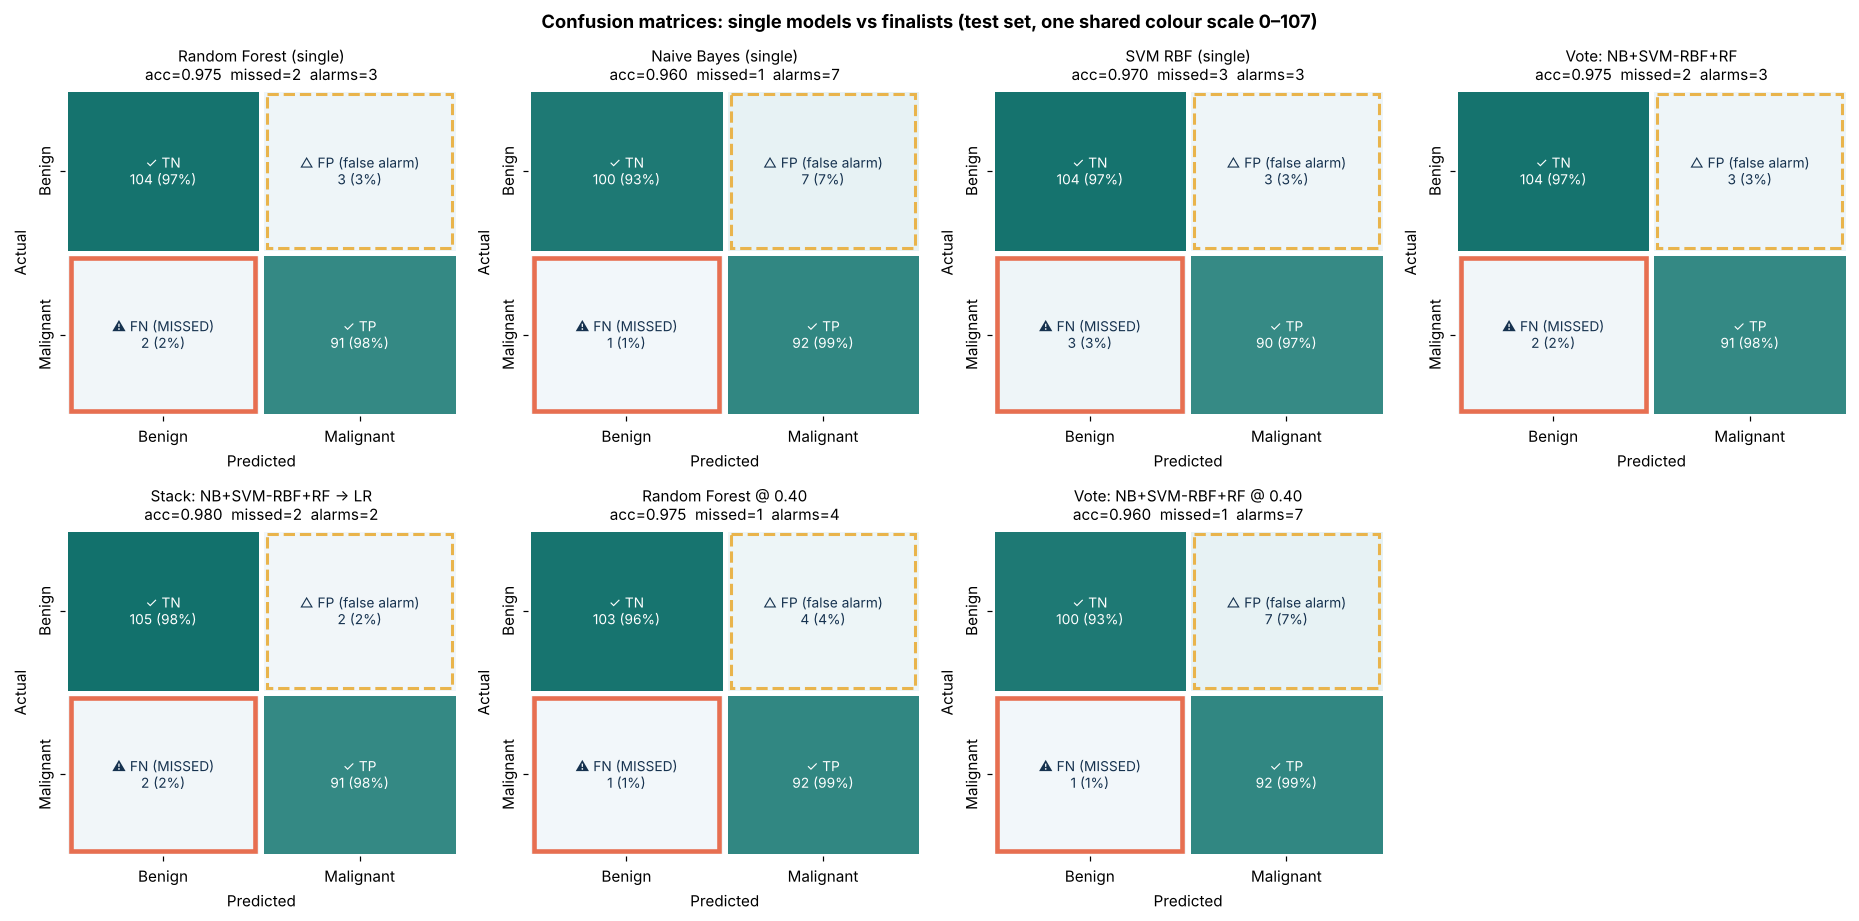

Comparison,Patients,b,c,p,p_min
Vote: NB + SVM-RBF + RF @ 0.40 vs Random Forest @ 0.40,all,1,4,0.375,0.062
Vote: NB + SVM-RBF + RF @ 0.40 vs Random Forest @ 0.40,malignant,1,1,1.000,0.500
Vote: NB + SVM-RBF + RF @ 0.40 vs Random Forest @ 0.40,benign,0,3,0.250,0.250
Vote: NB + SVM-RBF + RF @ 0.40 vs Random Forest,all,1,4,0.375,0.062
Vote: NB + SVM-RBF + RF @ 0.40 vs Random Forest,malignant,1,0,1.000,1.000
Vote: NB + SVM-RBF + RF @ 0.40 vs Random Forest,benign,0,4,0.125,0.125


> The ensemble and Random Forest disagree on very few test patients (at most 5), so no McNemar test is significant (smallest p = 0.12). The test set **cannot separate** the finalists; the choice rests on the fresh-fold evidence in E2 and on the clinical cost logic below.

In [42]:
names_ = list(compare.index)
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
for ax in axes.ravel()[len(names_):]: ax.axis('off')
for ax, n in zip(axes.ravel(), names_):
    r = compare.loc[n]
    plot_cm(ax, preds[n] if n in preds else preds[n.replace(' (single)', '')],
            f"{n.replace(' + ', '+')}\nacc={r['Accuracy']:.3f}  missed={int(r['FN'])}  alarms={int(r['FP'])}")
plt.suptitle(f'Confusion matrices: single models vs finalists (test set, one shared colour scale 0–{CM_VMAX})', fontweight='bold')
plt.tight_layout(); plt.show()

win_name = list(tuned_cfg)[1]; rf_name = list(tuned_cfg)[0]
mc_rows = []
for other in [rf_name, 'Random Forest']:
    for subset, msk in masks.items():
        m_ = mcnemar_exact(preds[win_name][msk] == yt[msk], preds[other][msk] == yt[msk])
        mc_rows.append({'Comparison': f"{win_name}  vs  {other}", 'Patients': subset, **m_})
mcf = pd.DataFrame(mc_rows)
display(mcf.style.hide(axis='index').format({'p': '{:.3f}', 'p_min': '{:.3f}'})
        .set_caption('Table E5 – McNemar tests on the test set: recommended ensemble vs Random Forest'))
say(f"> The ensemble and Random Forest disagree on very few test patients (at most {mcf.b.add(mcf.c).max()}), so no McNemar "
    f"test is significant (smallest p = {mcf.p.min():.2f}). The test set **cannot separate** the finalists; the choice rests on the "
    "fresh-fold evidence in E2 and on the clinical cost logic below.")

# PART F: Clinical cost analysis & decision thresholds
Accuracy treats both errors as equal. The clinic does not. As an **illustrative assumption**, let a missed cancer cost **10×** a false alarm:

$$\text{Clinical cost} = 10 \times FN + 1 \times FP$$

*(The 10:1 ratio is ours, for illustration. The clinic's medical team should set the real ratio; the dashboard lets you vary it.)*

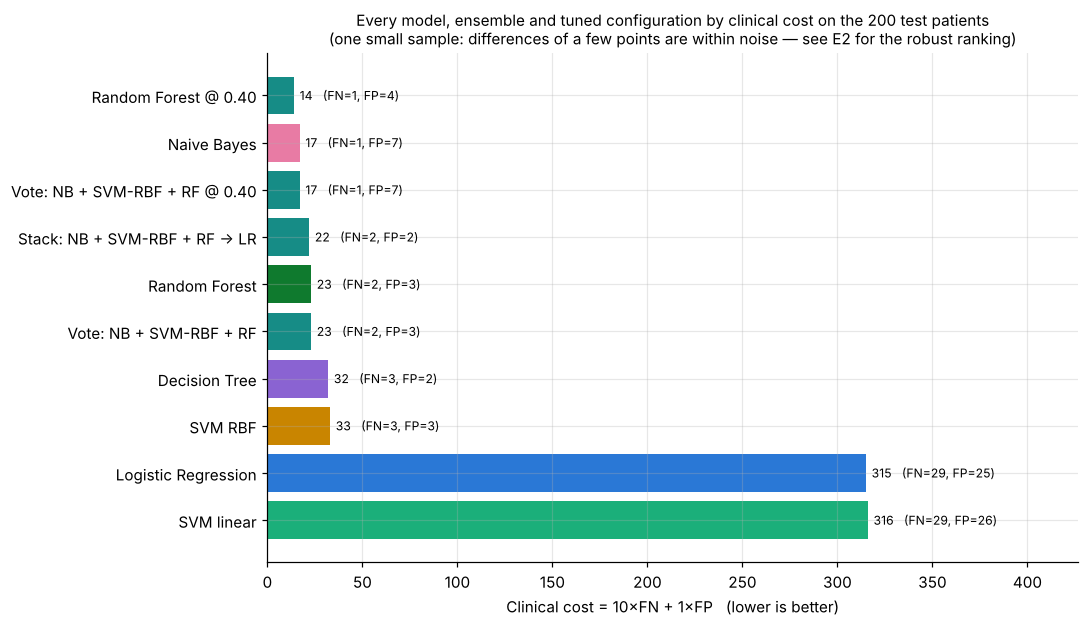

In [43]:
allres = pd.DataFrame(results).T.astype(float)
allres = allres.loc[~allres.index.duplicated()]
allres['Clinical cost'] = COST_FN * allres['FN'] + COST_FP * allres['FP']
allres = allres.sort_values(['Clinical cost', 'Accuracy'], ascending=[True, False])

fig, ax = plt.subplots(figsize=(10, 5.8))
cols = [MODEL_COLORS.get(n, TEAL) for n in allres.index]
ax.barh(allres.index[::-1], allres['Clinical cost'][::-1], color=cols[::-1])
for i, (n, r) in enumerate(allres[::-1].iterrows()):
    ax.text(r['Clinical cost'] + 3, i, f"{r['Clinical cost']:.0f}   (FN={int(r['FN'])}, FP={int(r['FP'])})", va='center', fontsize=8)
ax.set_xlabel(f'Clinical cost = {COST_FN}×FN + {COST_FP}×FP   (lower is better)')
ax.set_title('Every model, ensemble and tuned configuration by clinical cost on the 200 test patients\n'
             '(one small sample: differences of a few points are within noise — see E2 for the robust ranking)', fontsize=10)
ax.set_xlim(0, allres['Clinical cost'].max() * 1.35); plt.tight_layout(); plt.show()

### F2. Tuning the decision threshold — every required model
By default a model says "malignant" when its probability exceeds 0.5. Lowering the threshold catches more cancers at the price of more false alarms. To keep this honest, the threshold is **chosen on out-of-fold training predictions** (never the test set) from the same grid and cost as Part E, then applied **once** to the test set. SVMs use their calibrated probabilities, so all thresholds are on the same 0–1 scale.

Model,Probability,Threshold,CV missed (of 277),CV false alarms (of 323),CV specificity,Test missed,Test false alarms,Test accuracy,Usable?
Logistic Regression,native,0.50 → 0.15,7,227,29.7%,29 → 7,25 → 74,0.730 → 0.595,⚠ flags almost everyone
Naive Bayes,native,0.50 → 0.45,3,27,91.6%,1 → 1,7 → 8,0.960 → 0.955,✓
SVM linear,calibrated (Platt),0.50 → 0.10,3,282,12.7%,29 → 2,26 → 96,0.725 → 0.510,⚠ flags almost everyone
SVM RBF,calibrated (Platt),0.50 → 0.15,2,32,90.1%,2 → 0,4 → 8,0.970 → 0.960,✓
Decision Tree,native,0.50 → 0.05,11,19,94.1%,3 → 3,2 → 6,0.975 → 0.955,✓
Random Forest,native,0.50 → 0.40,1,18,94.4%,2 → 1,3 → 4,0.975 → 0.975,✓


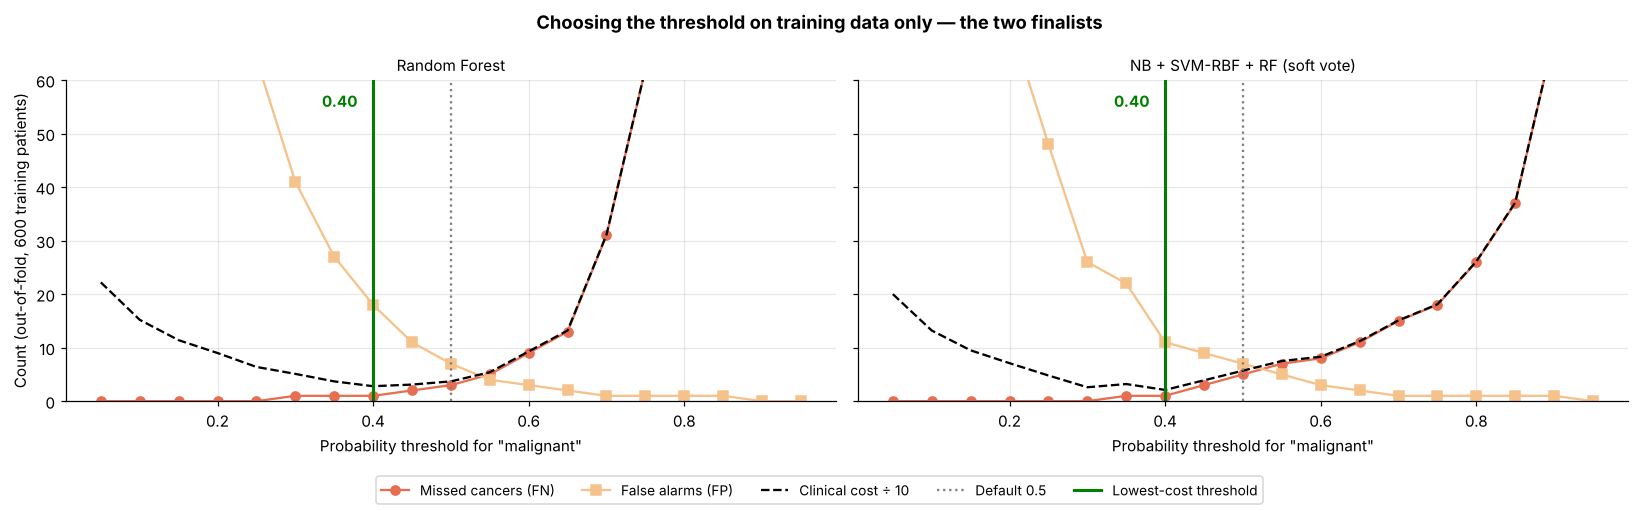

In [44]:
rows = []
for n in MODELS:
    t, fn_cv, fp_cv = best_threshold(yv, oof_p[n])
    _, _, _, tn_cv = counts(yv, oof_p[n], t)
    tp0, fp0, fn0, tn0 = counts(yt, test_p[n], 0.5); tp1, fp1, fn1, tn1 = counts(yt, test_p[n], t)
    rows.append({'Model': n, 'Probability': 'calibrated (Platt)' if 'SVM' in n else 'native', 'Threshold': f"0.50 → {t:.2f}",
                 'CV missed (of 277)': fn_cv, 'CV false alarms (of 323)': fp_cv, 'CV specificity': tn_cv / (tn_cv + fp_cv),
                 'Test missed': f"{fn0} → {fn1}", 'Test false alarms': f"{fp0} → {fp1}",
                 'Test accuracy': f"{(tp0 + tn0) / 200:.3f} → {(tp1 + tn1) / 200:.3f}",
                 'Usable?': '⚠ flags almost everyone' if tn_cv / (tn_cv + fp_cv) < 0.5 else '✓', '_t': t})
thr_all = pd.DataFrame(rows)
display(thr_all.drop(columns='_t').style.hide(axis='index').format({'CV specificity': '{:.1%}'})
        .set_caption('Table F2 – Cost-tuned thresholds for the six required models (chosen on training CV; test effect = default → tuned)'))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for ax, (name, mem, t_star) in zip(axes, [('Random Forest', ('Random Forest',), RFROW.Threshold),
                                          (f"{WIN.Candidate} (soft vote)", WIN.members, WIN.Threshold)]):
    p = np.mean([oof_p[m] for m in mem], axis=0) if mem != (STACK_NAME,) else oof_p[STACK_NAME]
    fns = [counts(yv, p, t)[2] for t in THRESHOLDS]; fps = [counts(yv, p, t)[1] for t in THRESHOLDS]
    ax.plot(THRESHOLDS, fns, 'o-', color=MALIG_C, label='Missed cancers (FN)')
    ax.plot(THRESHOLDS, fps, 's-', color='#F6C28B', label='False alarms (FP)')
    ax.plot(THRESHOLDS, (COST_FN * np.array(fns) + np.array(fps)) / 10, 'k--', lw=1.5, label='Clinical cost ÷ 10')
    ax.axvline(.5, color='grey', ls=':', label='Default 0.5'); ax.axvline(t_star, color='green', lw=2, label=f'Lowest cost: {t_star:.2f}')
    ax.set_ylim(0, 60); ax.set_xlabel('Probability threshold for "malignant"'); ax.set_title(name, fontsize=10)
    ax.text(t_star - .02, 55, f'{t_star:.2f}', color='green', ha='right', fontweight='bold')
axes[0].set_ylabel('Count (out-of-fold, 600 training patients)')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h[:4] + [Line2D([], [], color='green', lw=2)], l[:4] + ['Lowest-cost threshold'], loc='lower center', ncol=5, fontsize=9)
plt.suptitle('Choosing the threshold on training data only — the two finalists', fontweight='bold')
plt.tight_layout(rect=[0, .07, 1, 1]); plt.show()

In [45]:
rf_t = thr_all.set_index('Model').loc['Random Forest']
bad = thr_all[thr_all['Usable?'] != '✓'].Model.tolist()
w_test = counts(yt, np.mean([test_p[m] for m in WIN.members], 0) if WIN.Type != 'Stacking' else test_p[STACK_NAME], WIN.Threshold)
say(f'''> **Insight.**
> - **Random Forest:** threshold 0.50 → {rf_t._t:.2f}; test missed cancers {rf_t['Test missed']}, false alarms {rf_t['Test false alarms']}.
> - **{WIN.Candidate}:** at {WIN.Threshold:.2f} the ensemble reaches about the same missed-cancer rate as Random Forest at
>   {RFROW.Threshold:.2f} with fewer false alarms in cross-validation ({WIN['Fresh false alarms (mean)']:.1f} vs
>   {RFROW['Fresh false alarms (mean)']:.1f} per 600 patients on fresh folds). On the 200-patient test set it misses {w_test[2]} of 93
>   with {w_test[1]} false alarms, within noise of Random Forest (Table E5).
> - {' and '.join(bad) if bad else 'No model'} can only reach the cost-optimal sensitivity by flagging almost every patient
>   (training specificity below 50%), so {'their tuned thresholds are' if len(bad) > 1 else 'its tuned threshold is'} not a usable
>   operating point: a threshold cannot fix a model whose **ranking** is weak (Part D2).''')

> **Insight.**
> - **Random Forest:** threshold 0.50 → 0.40; test missed cancers 2 → 1, false alarms 3 → 4.
> - **NB + SVM-RBF + RF:** at 0.40 the ensemble reaches about the same missed-cancer rate as Random Forest at
>   0.40 with fewer false alarms in cross-validation (10.4 vs
>   17.8 per 600 patients on fresh folds). On the 200-patient test set it misses 1 of 93
>   with 7 false alarms, within noise of Random Forest (Table E5).
> - Logistic Regression and SVM linear can only reach the cost-optimal sensitivity by flagging almost every patient
>   (training specificity below 50%), so their tuned thresholds are not a usable
>   operating point: a threshold cannot fix a model whose **ranking** is weak (Part D2).

### F3. Can the probabilities be read as risks? (calibration)
A model can **rank** patients almost perfectly (high ROC-AUC) and still give probabilities that are not literal risks. It is **well calibrated** if, among patients it scores at about 0.3, about 30% really are malignant. We check this on the 600 out-of-fold training predictions (and, with more noise, on the 200 test patients):
- **Reliability diagram:** mean predicted probability vs observed malignant share in 10 equal-width bins (the diagonal = perfect).
- **Brier score:** mean squared error of the probabilities (0 = perfect). *Brier skill* = improvement over always predicting the base rate.
- **ECE (expected calibration error):** average gap between predicted and observed rates, weighted by the number of patients in each bin.

Model / configuration,Probability source,Brier (CV),Brier skill (CV),ECE (CV),Brier (test),ECE (test)
SVM RBF,Platt-calibrated,0.022,91.2%,0.016,0.017,0.020
Stack: NB + SVM-RBF + RF → LR,logistic meta-model,0.014,94.3%,0.024,0.018,0.026
Decision Tree,leaf frequencies,0.034,86.3%,0.031,0.026,0.027
Logistic Regression,native,0.175,29.5%,0.031,0.182,0.045
SVM linear,Platt-calibrated,0.177,28.8%,0.038,0.182,0.062
Naive Bayes,native,0.039,84.2%,0.082,0.034,0.086
NB + SVM-RBF + RF,average of members,0.026,89.7%,0.088,0.023,0.073
Random Forest,share of trees voting,0.040,83.8%,0.137,0.035,0.108


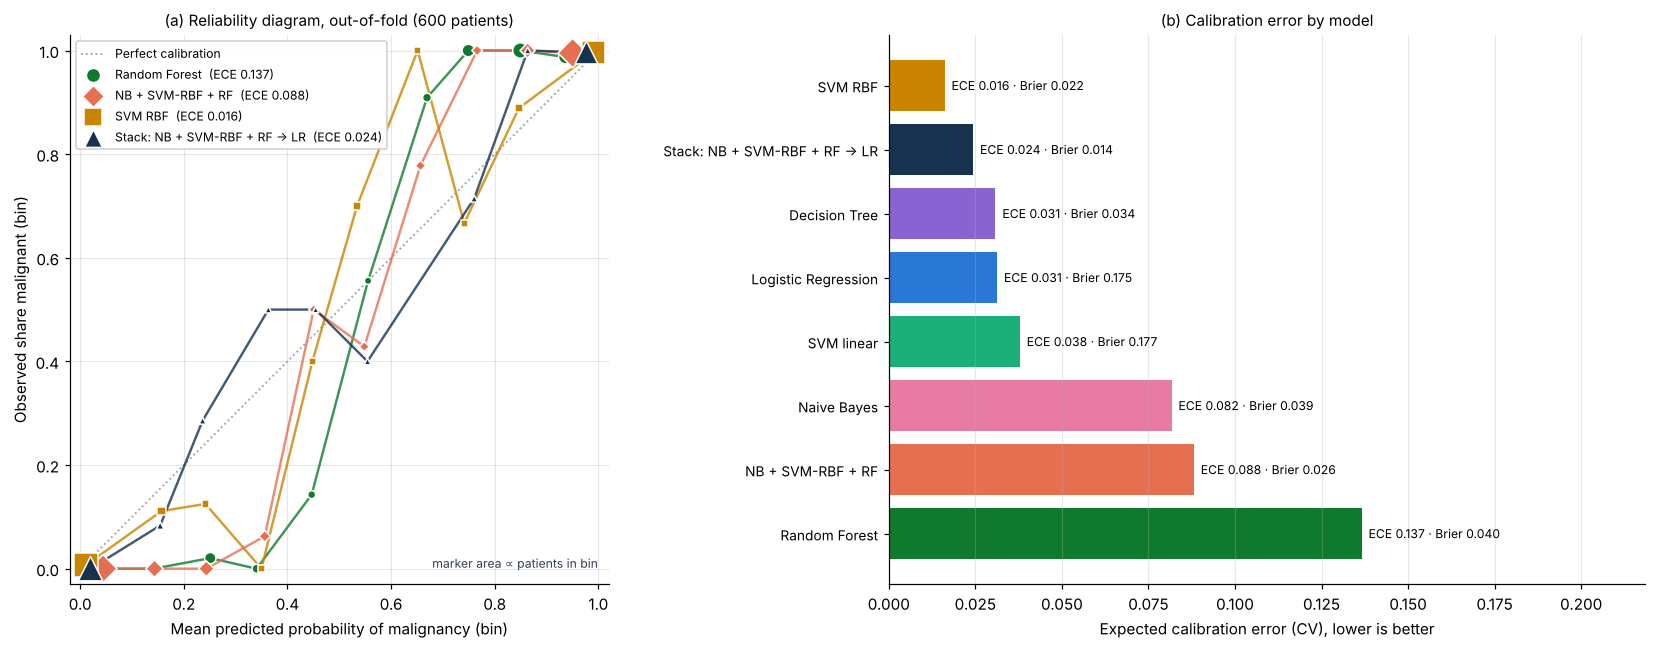

In [46]:
CAL_BINS = 10
def reliability(y, p, n_bins=CAL_BINS):
    y, p = np.asarray(y, float), np.asarray(p, float)
    idx = np.clip((p * n_bins).astype(int), 0, n_bins - 1)        # p = 1.0 falls in the last bin
    return pd.DataFrame([{'bin': b, 'n': int((idx == b).sum()), 'mean_pred': p[idx == b].mean(), 'frac_pos': y[idx == b].mean()}
                         for b in range(n_bins) if (idx == b).any()])

def cal_summary(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    brier = np.mean((p - y) ** 2); base = np.mean((y.mean() - y) ** 2)
    rel = reliability(y, p)
    return dict(brier=brier, skill=1 - brier / base, ece=(rel.n * (rel.mean_pred - rel.frac_pos).abs()).sum() / len(y), rel=rel)

cal_cfg = {n: (n,) for n in MODELS}
cal_cfg[WIN.Candidate] = tuple(WIN.members)
cal_cfg[STACK_NAME] = (STACK_NAME,)
cal_src = {'Logistic Regression': 'native', 'Naive Bayes': 'native', 'SVM linear': 'Platt-calibrated', 'SVM RBF': 'Platt-calibrated',
           'Decision Tree': 'leaf frequencies', 'Random Forest': 'share of trees voting',
           WIN.Candidate: 'average of members', STACK_NAME: 'logistic meta-model'}
cal = {}
for name, mem in cal_cfg.items():
    cal[name] = {'oof': cal_summary(yv, np.mean([oof_p[m] for m in mem], axis=0)),
                 'test': cal_summary(yt, np.mean([test_p[m] for m in mem], axis=0))}
cal_tbl = pd.DataFrame([{'Model / configuration': n, 'Probability source': cal_src[n],
                         'Brier (CV)': v['oof']['brier'], 'Brier skill (CV)': v['oof']['skill'], 'ECE (CV)': v['oof']['ece'],
                         'Brier (test)': v['test']['brier'], 'ECE (test)': v['test']['ece']} for n, v in cal.items()])
cal_tbl = cal_tbl.sort_values('ECE (CV)').reset_index(drop=True)
display(cal_tbl.style.hide(axis='index')
        .format({c: '{:.3f}' for c in ['Brier (CV)', 'ECE (CV)', 'Brier (test)', 'ECE (test)']} | {'Brier skill (CV)': '{:.1%}'})
        .background_gradient(subset=['ECE (CV)'], cmap='Reds', vmin=0, vmax=.15)
        .set_caption('Table F3 – Calibration, best first (lower Brier and ECE = better; CV = 600 out-of-fold training predictions)'))

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6), gridspec_kw={'width_ratios': [1, 1.1]})
ax = axes[0]
ax.plot([0, 1], [0, 1], ':', color='#94A3B8', lw=1.2, label='Perfect calibration')
for name, col, mk in [('Random Forest', MODEL_COLORS['Random Forest'], 'o'), (WIN.Candidate, CORAL, 'D'),
                      ('SVM RBF', MODEL_COLORS['SVM RBF'], 's'), (STACK_NAME, NAVY, '^')]:
    r = cal[name]['oof']['rel']
    ax.plot(r.mean_pred, r.frac_pos, '-', color=col, lw=1.6, alpha=.8)
    ax.scatter(r.mean_pred, r.frac_pos, s=16 + r.n * 0.8, color=col, marker=mk, edgecolor='white', zorder=3,
               label=f"{name}  (ECE {cal[name]['oof']['ece']:.3f})")
ax.set(xlim=(-.02, 1.02), ylim=(-.03, 1.03), xlabel='Mean predicted probability of malignancy (bin)',
       ylabel='Observed share malignant (bin)')
ax.set_title('(a) Reliability diagram, out-of-fold (600 patients)', fontsize=10)
ax.legend(loc='upper left', fontsize=8, framealpha=.95); ax.set_aspect('equal')
ax.text(.98, .03, 'marker area ∝ patients in bin', transform=ax.transAxes, ha='right', fontsize=8, color=SLATE)
ax = axes[1]
cols = [CORAL if n == WIN.Candidate else MODEL_COLORS.get(n, NAVY) for n in cal_tbl['Model / configuration']]
ax.barh(range(len(cal_tbl)), cal_tbl['ECE (CV)'], color=cols)
ax.set_yticks(range(len(cal_tbl)), cal_tbl['Model / configuration'], fontsize=9)
for i, r in cal_tbl.iterrows():
    ax.text(r['ECE (CV)'] + .002, i, f"ECE {r['ECE (CV)']:.3f} · Brier {r['Brier (CV)']:.3f}", va='center', fontsize=8)
ax.set_xlim(0, cal_tbl['ECE (CV)'].max() * 1.6); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_xlabel('Expected calibration error (CV), lower is better')
ax.set_title('(b) Calibration error by model', fontsize=10)
plt.tight_layout(); plt.show()

In [47]:
rf_rel = cal['Random Forest']['oof']['rel']
low = rf_rel[(rf_rel.mean_pred >= 0.1) & (rf_rel.mean_pred < 0.4)]
hi_ = rf_rel[(rf_rel.mean_pred >= 0.6) & (rf_rel.mean_pred < 0.9)]
best = cal_tbl.iloc[0]['Model / configuration']
k_low = int(round((low.n * low.frac_pos).sum()))
conf = lambda n: float(((oof_p[n] < .2) | (oof_p[n] > .8)).mean())
lr_conf, rf_conf = conf('Logistic Regression'), conf('Random Forest')
best_brier = cal_tbl.sort_values('Brier (CV)').iloc[0]['Model / configuration']
say(f'''> **Reading.**
> - **Ranking is not calibration.** Random Forest ranks patients almost perfectly (ROC-AUC {results['Random Forest']['ROC-AUC']:.3f}),
>   but its probabilities are **squeezed toward the middle** (ECE {cal['Random Forest']['oof']['ece']:.2f}). Of the {int(low.n.sum())} training
>   patients it scored between 0.1 and 0.4, only {k_low} {'was' if k_low == 1 else 'were'} malignant; of the {int(hi_.n.sum())} it scored
>   between 0.6 and 0.9, {int(round((hi_.n * hi_.frac_pos).sum()))} were malignant. A forest's "probability" is the share of trees voting
>   malignant, not a risk.
> - The recommended ensemble is better (ECE {cal[WIN.Candidate]['oof']['ece']:.2f}) but still compressed. The Platt-calibrated RBF-SVM
>   (ECE {cal['SVM RBF']['oof']['ece']:.3f}) and the stacked model (ECE {cal[STACK_NAME]['oof']['ece']:.3f}) are well calibrated:
>   lowest calibration error **{best}**, lowest Brier score **{best_brier}**.
> - **Low ECE alone is not enough.** Logistic Regression is calibrated (ECE {cal['Logistic Regression']['oof']['ece']:.3f}) but its Brier
>   score is {cal['Logistic Regression']['oof']['brier']:.3f}: its probabilities are honest about being unsure (only {lr_conf:.0%}
>   of patients get a score below 0.2 or above 0.8, vs {rf_conf:.0%} for Random Forest) because a straight line cannot separate the ring. Calibration and discrimination are separate questions.
> - **For MediScan:** the recommendation does not change, because every threshold was chosen from *observed* errors on
>   out-of-fold predictions, not by trusting the probability values. But before a score is ever shown to a clinician as
>   "risk = 40%", it must be recalibrated (Platt or isotonic scaling on held-out data). Until then, treat it as a **ranking with a
>   validated cut-off**.''')

> **Reading.**
> - **Ranking is not calibration.** Random Forest ranks patients almost perfectly (ROC-AUC 0.996),
>   but its probabilities are **squeezed toward the middle** (ECE 0.14). Of the 138 training
>   patients it scored between 0.1 and 0.4, only 1 was malignant; of the 193 it scored
>   between 0.6 and 0.9, 191 were malignant. A forest's "probability" is the share of trees voting
>   malignant, not a risk.
> - The recommended ensemble is better (ECE 0.09) but still compressed. The Platt-calibrated RBF-SVM
>   (ECE 0.016) and the stacked model (ECE 0.024) are well calibrated:
>   lowest calibration error **SVM RBF**, lowest Brier score **Stack: NB + SVM-RBF + RF → LR**.
> - **Low ECE alone is not enough.** Logistic Regression is calibrated (ECE 0.031) but its Brier
>   score is 0.175: its probabilities are honest about being unsure (only 39%
>   of patients get a score below 0.2 or above 0.8, vs 69% for Random Forest) because a straight line cannot separate the ring. Calibration and discrimination are separate questions.
> - **For MediScan:** the recommendation does not change, because every threshold was chosen from *observed* errors on
>   out-of-fold predictions, not by trusting the probability values. But before a score is ever shown to a clinician as
>   "risk = 40%", it must be recalibrated (Platt or isotonic scaling on held-out data). Until then, treat it as a **ranking with a
>   validated cut-off**.

# PART G: Answers to the report questions & recommendation

In [48]:
# Six-model recommendation — the same rule as the dashboard, stated before reading the winner:
# 1) safety gate: test FN within 1 of the best AND repeated-CV recall within 2 points of the best;
# 2) fewest false alarms among survivors; 3) tie-breaks: higher CV accuracy, then higher test accuracy.
six = pd.DataFrame({n: {'FN': results[n]['FN'], 'FP': results[n]['FP'], 'Test accuracy': results[n]['Accuracy'],
                        'CV recall': cv_folds[n]['recall'].mean(), 'CV accuracy': cv_folds[n]['accuracy'].mean()}
                    for n in MODELS}).T.astype(float)
six['FN gate'] = six.FN <= six.FN.min() + 1
six['CV gate'] = six['CV recall'] >= six['CV recall'].max() - 0.02 - 1e-12
surv = six[six['FN gate'] & six['CV gate']].sort_values(['FP', 'CV accuracy', 'Test accuracy'], ascending=[True, False, False])
REC_SIX = surv.index[0]
display(six.style.format({'FN': '{:.0f}', 'FP': '{:.0f}', 'Test accuracy': '{:.3f}', 'CV recall': '{:.3f}', 'CV accuracy': '{:.3f}'})
        .set_caption('Table G1 – Six-model decision table (safety gate, then fewest false alarms)'))

final = stage2.drop(columns=['members', '_rep', 'Type']).copy()
final.style.hide(axis='index').format({'Threshold': '{:.2f}', 'Fresh missed (mean)': '{:.1f}', 'Fresh false alarms (mean)': '{:.1f}',
            'Fresh cost (mean)': '{:.1f}', 'Fresh cost (sd)': '{:.1f}', 'Test accuracy': '{:.3f}', 'Test recall': '{:.3f}',
            'p vs winner': lambda v: '—' if pd.isna(v) else f'{v:.2f}'}) \
   .background_gradient(subset=['Fresh cost (mean)', 'Test cost'], cmap='RdYlGn_r') \
   .set_caption('Table G2 – FINAL LEADERBOARD of configurations: ranked by fresh-fold clinical cost (robust), test set alongside')

,FN,FP,Test accuracy,CV recall,CV accuracy,FN gate,CV gate
Logistic Regression,29,25,0.730,0.699,0.747,False,False
Naive Bayes,1,7,0.960,0.986,0.963,True,True
SVM linear,29,26,0.725,0.696,0.735,False,False
SVM RBF,3,3,0.970,0.954,0.970,False,False
Decision Tree,3,2,0.975,0.947,0.961,False,False
Random Forest,2,3,0.975,0.988,0.981,True,True


Final rank,Candidate,Size,Threshold,Stage-1 CV cost,Fresh missed (mean),Fresh false alarms (mean),Fresh cost (mean),Fresh cost (sd),Test missed,Test false alarms,Test cost,Test accuracy,Test recall,p vs winner
1,NB + SVM-RBF + RF,3,0.40,21,1.7,10.4,27.4,8.6,1,7,17,0.960,0.989,—
2,NB + DT + RF,3,0.30,22,0.6,21.8,27.8,6.4,0,5,5,0.975,1.000,0.98
3,NB + DT,2,0.30,25,1.0,19.5,29.5,8.0,0,5,5,0.975,1.000,0.89
4,NB + SVM-RBF + DT + RF,4,0.40,20,1.9,11.6,30.6,9.5,1,2,12,0.985,0.989,0.87
5,SVM-RBF + DT + RF,3,0.25,24,1.3,17.9,30.9,10.4,1,5,15,0.970,0.989,0.83
6,Stack: NB + SVM-RBF + RF → LR,1,0.20,24,1.9,12.5,31.5,8.7,1,7,17,0.960,0.989,0.64
7,NB + RF,2,0.45,25,1.9,13.5,32.5,5.5,1,5,15,0.970,0.989,0.76
8,DT + RF,2,0.20,22,1.7,22.5,39.5,8.6,1,5,15,0.970,0.989,0.56
9,Random Forest,1,0.40,28,2.2,17.8,39.8,4.0,1,4,14,0.975,0.989,0.56


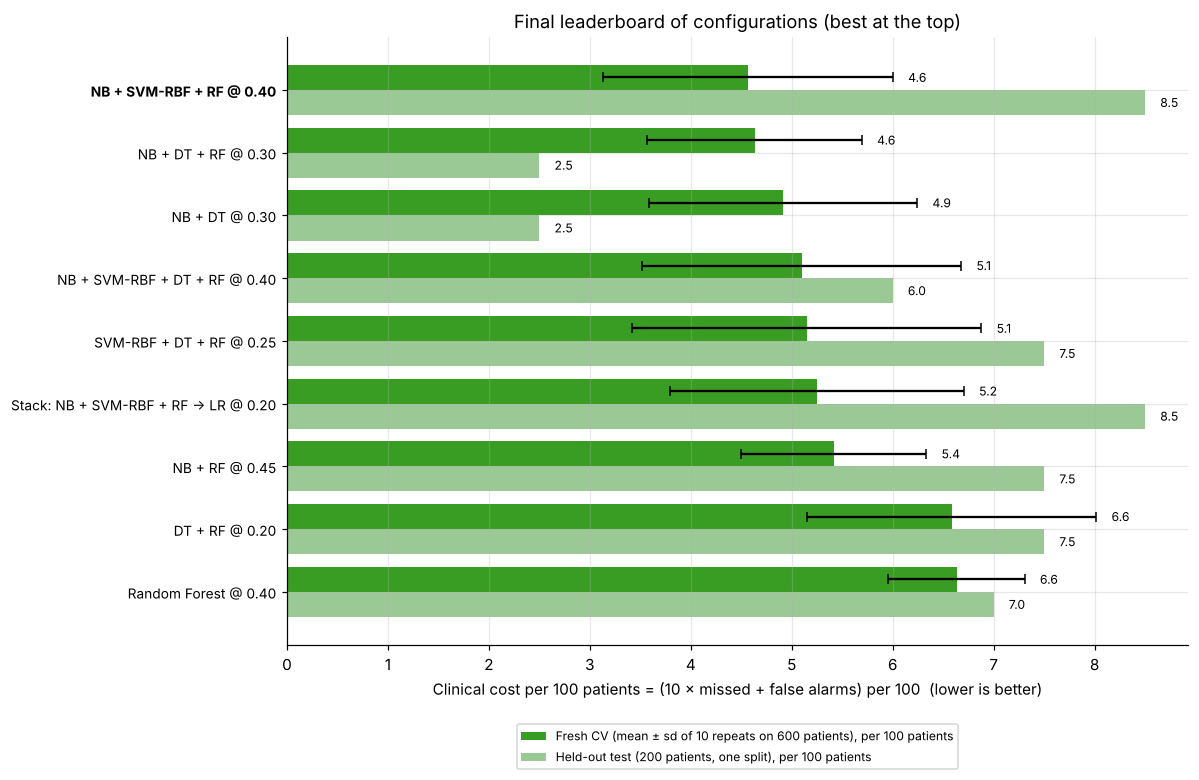

In [49]:
plot_df = stage2.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 0.6 * len(plot_df) + 1.8))
yy = np.arange(len(plot_df))
f_mean, f_sd, t_cost = plot_df['Fresh cost (mean)'] / 6, plot_df['Fresh cost (sd)'] / 6, plot_df['Test cost'] / 2
ax.barh(yy + .2, f_mean, .4, xerr=f_sd, color='#3A9D23', capsize=3,
        label='Fresh CV (mean ± sd of 10 repeats on 600 patients), per 100 patients')
ax.barh(yy - .2, t_cost, .4, color='#9BC995', label='Held-out test (200 patients, one split), per 100 patients')
for i in range(len(plot_df)):
    ax.text(f_mean.iloc[i] + f_sd.iloc[i] + .15, i + .2, f"{f_mean.iloc[i]:.1f}", va='center', fontsize=8)
    ax.text(t_cost.iloc[i] + .15, i - .2, f"{t_cost.iloc[i]:.1f}", va='center', fontsize=8)
ax.set_yticks(yy, [f"{c} @ {t:.2f}" for c, t in zip(plot_df.Candidate, plot_df.Threshold)], fontsize=9)
ax.get_yticklabels()[-1].set_fontweight('bold')
ax.set_xlabel('Clinical cost per 100 patients = (10 × missed + false alarms) per 100  (lower is better)')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.12), ncol=1, fontsize=8)
ax.set_title('Final leaderboard of configurations (best at the top)'); plt.tight_layout(); plt.show()

In [50]:
un_acc = piv.loc['SVM RBF', 'Unscaled']; sc_acc = piv.loc['SVM RBF', 'Scaled']
lin_fns = [int(results[m]['FN']) for m in ['Logistic Regression', 'SVM linear']]
lin_fn_txt = f'each missing {lin_fns[0]} cancers' if lin_fns[0] == lin_fns[1] else f'missing {lin_fns[0]} and {lin_fns[1]} cancers'
say(f'''## Answers to the report questions

**1. Which models struggled, which did well, and what do the strugglers have in common?**
**Logistic Regression** and **SVM-linear** struggled ({results['Logistic Regression']['Accuracy']:.1%} and {results['SVM linear']['Accuracy']:.1%}
accuracy, {lin_fn_txt}). Both can only draw a **straight**
boundary. **SVM-RBF, Decision Tree, Random Forest and Naive Bayes** reached {min(results[m]['Accuracy'] for m in STRONG):.1%}–{max(results[m]['Accuracy'] for m in STRONG):.1%}.
Each can **bend** its boundary: a kernel curve, axis-aligned boxes, or (for Gaussian NB) an ellipse that comes from the different class variances.
McNemar tests confirm the linear-vs-curved gap is real; among the curved models the test set cannot separate them (Part D6).

**2. Why does the boundary look the way it does?**
In `cell_size` × `cell_shape`, benign cells form a **central disc** and malignant cells a **ring** around it: malignant cells are abnormal in
*either* direction. The correct boundary is a **closed curve**. That's also why these two features have ≈0 correlation with the diagnosis yet are
the most important features for every model that can bend.

**3. Did scaling change any model's performance?**
Yes, but only the **RBF SVM**: {un_acc:.3f} unscaled → {sc_acc:.3f} scaled ({(sc_acc - un_acc) * 100:+.1f} points). Its kernel is distance-based,
so unscaled `marker_level` swamps the ring features. Trees, Random Forest, Naive Bayes and the linear models were unchanged (Table D5).

**4. Most accurate model, or the one that catches the most cancers?**
For a screening clinic, **catching cancers comes first**: a missed cancer can cost a life, a false alarm costs an extra test. Recall alone isn't
enough (calling everyone malignant gives 100% recall and is useless), so we minimise a cost that weights a missed cancer 10× a false alarm.
Among the six required models that favours **{REC_SIX}**; going further, lowering thresholds and combining models reduces the expected cost
again (Parts E–F).''')

## Answers to the report questions

**1. Which models struggled, which did well, and what do the strugglers have in common?**
**Logistic Regression** and **SVM-linear** struggled (73.0% and 72.5%
accuracy, each missing 29 cancers). Both can only draw a **straight**
boundary. **SVM-RBF, Decision Tree, Random Forest and Naive Bayes** reached 96.0%–97.5%.
Each can **bend** its boundary: a kernel curve, axis-aligned boxes, or (for Gaussian NB) an ellipse that comes from the different class variances.
McNemar tests confirm the linear-vs-curved gap is real; among the curved models the test set cannot separate them (Part D6).

**2. Why does the boundary look the way it does?**
In `cell_size` × `cell_shape`, benign cells form a **central disc** and malignant cells a **ring** around it: malignant cells are abnormal in
*either* direction. The correct boundary is a **closed curve**. That's also why these two features have ≈0 correlation with the diagnosis yet are
the most important features for every model that can bend.

**3. Did scaling change any model's performance?**
Yes, but only the **RBF SVM**: 0.615 unscaled → 0.970 scaled (+35.5 points). Its kernel is distance-based,
so unscaled `marker_level` swamps the ring features. Trees, Random Forest, Naive Bayes and the linear models were unchanged (Table D5).

**4. Most accurate model, or the one that catches the most cancers?**
For a screening clinic, **catching cancers comes first**: a missed cancer can cost a life, a false alarm costs an extra test. Recall alone isn't
enough (calling everyone malignant gives 100% recall and is useless), so we minimise a cost that weights a missed cancer 10× a false alarm.
Among the six required models that favours **Random Forest**; going further, lowering thresholds and combining models reduces the expected cost
again (Parts E–F).

## 🏆 Recommendation to MediScan

In [51]:
print("FINAL TOP 3 configurations (ranked by fresh-fold clinical cost):")
for i, (_, r) in enumerate(stage2.head(3).iterrows(), 1):
    print(f"  {i}. {r.Candidate} @ threshold {r.Threshold:.2f}")
    print(f"     Fresh CV: {r['Fresh missed (mean)']:.1f} missed / 277 cancers, {r['Fresh false alarms (mean)']:.1f} false alarms / 323, "
          f"cost {r['Fresh cost (mean)']:.1f} ± {r['Fresh cost (sd)']:.1f}")
    print(f"     Test    : missed {int(r['Test missed'])}/93, false alarms {int(r['Test false alarms'])}/107, "
          f"accuracy {r['Test accuracy']:.3f}, recall {r['Test recall']:.3f}")

FINAL TOP 3 configurations (ranked by fresh-fold clinical cost):
  1. NB + SVM-RBF + RF @ threshold 0.40
     Fresh CV: 1.7 missed / 277 cancers, 10.4 false alarms / 323, cost 27.4 ± 8.6
     Test    : missed 1/93, false alarms 7/107, accuracy 0.960, recall 0.989
  2. NB + DT + RF @ threshold 0.30
     Fresh CV: 0.6 missed / 277 cancers, 21.8 false alarms / 323, cost 27.8 ± 6.4
     Test    : missed 0/93, false alarms 5/107, accuracy 0.975, recall 1.000
  3. NB + DT @ threshold 0.30
     Fresh CV: 1.0 missed / 277 cancers, 19.5 false alarms / 323, cost 29.5 ± 8.0
     Test    : missed 0/93, false alarms 5/107, accuracy 0.975, recall 1.000


In [52]:
rs = results[REC_SIX]
in_win = lambda m: m in WIN.members
role = {m: ('part of the recommended ensemble' if in_win(m) else
            f"member of {sum(m in c for c in shortlist.members)} shortlisted combination(s)" if any(m in c for c in shortlist.members)
            else 'not in any shortlisted combination') for m in MODELS}
CAUT = stage2.sort_values(['Fresh missed (mean)', 'Fresh cost (mean)']).iloc[0]
caut_txt = ('' if CAUT.Candidate == WIN.Candidate else
            f" If MediScan wants to minimise missed cancers above all, **{CAUT.Candidate} @ {CAUT.Threshold:.2f}** missed the fewest "
            f"cancers on fresh folds ({CAUT['Fresh missed (mean)']:.1f} per 600 patients, at {CAUT['Fresh false alarms (mean)']:.1f} false "
            f"alarms; {int(CAUT['Test missed'])} of 93 missed on the test set) and its cost is statistically equivalent "
            f"(p = {CAUT['p vs winner']:.2f}), so it is the most cautious alternative.")
equiv_txt = ('none of the other shortlisted configurations is significantly worse' if len(equiv) == len(stage2) - 1 else
             f"{len(equiv)} of the other {len(stage2) - 1} shortlisted configurations are not significantly worse")
say(f'''**Recommendation (team paragraph).**
Among the six required classifiers we recommend **{REC_SIX}**: on the 200 held-out patients it caught {int(rs['TP'])} of 93 cancers
({int(rs['FN'])} missed) with {int(rs['FP'])} false alarms (accuracy {rs['Accuracy']:.1%}), and it had the highest cross-validated recall
({cv_folds[REC_SIX]['recall'].mean():.1%}). Beyond the required line-up, we recommend deploying a **soft-voting ensemble of {WIN.Candidate}**,
flagging a patient as malignant when the averaged probability exceeds **{WIN.Threshold:.2f}**. Of {len(combos)} candidates (six single
models, 50 soft-voting combinations and a stacked ensemble), each with its own threshold chosen on training data, this configuration had
the **lowest clinical cost on 10 fresh repetitions of cross-validation**: {WIN['Fresh missed (mean)']:.1f} missed cancers and
{WIN['Fresh false alarms (mean)']:.1f} false alarms per 600 patients, versus {RFROW['Fresh missed (mean)']:.1f} and
{RFROW['Fresh false alarms (mean)']:.1f} for Random Forest at {RFROW.Threshold:.2f}, and it was cheaper in {better} of 10 repeats. Its members
draw *different kinds* of curved boundary, so their mistakes rarely coincide. On the held-out test set it missed {int(WIN['Test missed'])} of 93
cancers with {int(WIN['Test false alarms'])} false alarms.

**How we balanced cancers vs false alarms, and how sure we are.** We treated a missed cancer as **10× worse** than a false alarm and chose every
threshold on training data only. The ensemble's advantage over Random Forest at its tuned threshold is **fewer false alarms at the same
cancer-catching rate** (false alarms p = {TT['false_alarms']['p']:.2f}, missed cancers p = {TT['missed']['p']:.2f}, corrected t-tests), so it is
borderline rather than conclusive, and {equiv_txt}. **Random Forest at threshold {RFROW.Threshold:.2f}** is therefore a simpler,
statistically comparable fallback.{caut_txt} The cost ratio should be confirmed with MediScan's clinicians, and the model should be a **screening aid
that prioritises patients for specialist review, not a replacement** for the specialist. These results come from an educational dataset and
do not establish clinical validity; deployment would need external validation, calibration, prospective evaluation and governance.

**Not recommended:** Logistic Regression and the linear SVM. They miss about **1 in 3 cancers** because a straight line can't represent the
ring-shaped boundary, and lowering their threshold only works by flagging almost everyone.

| Member | Model(s) built | Outcome |
|---|---|---|
| **Sparsh** | Random Forest, Decision Tree | RF: best single model, {role['Random Forest']} and the fallback; DT: good (boxes in the benign core), {role['Decision Tree']} |
| **Aradhana** | SVM linear | Fails ({int(results['SVM linear']['FN'])} missed): a straight margin cannot enclose the ring; shows *why* the kernel matters |
| **Shashaank** | SVM RBF | Strong once scaled ({int(results['SVM RBF']['FN'])} missed), {role['SVM RBF']} |
| **Shirley** | Naive Bayes | Strong (elliptical boundary, {int(results['Naive Bayes']['FN'])} missed), {role['Naive Bayes']} |
| **Mahi** | Logistic Regression | Fails ({int(results['Logistic Regression']['FN'])} missed): the straight-line baseline that proves the boundary is curved |
''')

**Recommendation (team paragraph).**
Among the six required classifiers we recommend **Random Forest**: on the 200 held-out patients it caught 91 of 93 cancers
(2 missed) with 3 false alarms (accuracy 97.5%), and it had the highest cross-validated recall
(98.8%). Beyond the required line-up, we recommend deploying a **soft-voting ensemble of NB + SVM-RBF + RF**,
flagging a patient as malignant when the averaged probability exceeds **0.40**. Of 57 candidates (six single
models, 50 soft-voting combinations and a stacked ensemble), each with its own threshold chosen on training data, this configuration had
the **lowest clinical cost on 10 fresh repetitions of cross-validation**: 1.7 missed cancers and
10.4 false alarms per 600 patients, versus 2.2 and
17.8 for Random Forest at 0.40, and it was cheaper in 9 of 10 repeats. Its members
draw *different kinds* of curved boundary, so their mistakes rarely coincide. On the held-out test set it missed 1 of 93
cancers with 7 false alarms.

**How we balanced cancers vs false alarms, and how sure we are.** We treated a missed cancer as **10× worse** than a false alarm and chose every
threshold on training data only. The ensemble's advantage over Random Forest at its tuned threshold is **fewer false alarms at the same
cancer-catching rate** (false alarms p = 0.06, missed cancers p = 0.80, corrected t-tests), so it is
borderline rather than conclusive, and none of the other shortlisted configurations is significantly worse. **Random Forest at threshold 0.40** is therefore a simpler,
statistically comparable fallback. If MediScan wants to minimise missed cancers above all, **NB + DT + RF @ 0.30** missed the fewest cancers on fresh folds (0.6 per 600 patients, at 21.8 false alarms; 0 of 93 missed on the test set) and its cost is statistically equivalent (p = 0.98), so it is the most cautious alternative. The cost ratio should be confirmed with MediScan's clinicians, and the model should be a **screening aid
that prioritises patients for specialist review, not a replacement** for the specialist. These results come from an educational dataset and
do not establish clinical validity; deployment would need external validation, calibration, prospective evaluation and governance.

**Not recommended:** Logistic Regression and the linear SVM. They miss about **1 in 3 cancers** because a straight line can't represent the
ring-shaped boundary, and lowering their threshold only works by flagging almost everyone.

| Member | Model(s) built | Outcome |
|---|---|---|
| **Sparsh** | Random Forest, Decision Tree | RF: best single model, part of the recommended ensemble and the fallback; DT: good (boxes in the benign core), member of 5 shortlisted combination(s) |
| **Aradhana** | SVM linear | Fails (29 missed): a straight margin cannot enclose the ring; shows *why* the kernel matters |
| **Shashaank** | SVM RBF | Strong once scaled (3 missed), part of the recommended ensemble |
| **Shirley** | Naive Bayes | Strong (elliptical boundary, 1 missed), part of the recommended ensemble |
| **Mahi** | Logistic Regression | Fails (29 missed): the straight-line baseline that proves the boundary is curved |


In [53]:
summary = stage2.head(4).copy()
rows = [f"| {'🥇🥈🥉'[i] if i < 3 else '–'} | **{r.Candidate}** @ {r.Threshold:.2f} | {r['Fresh missed (mean)']:.1f} missed · "
        f"{r['Fresh false alarms (mean)']:.1f} false alarms (cost {r['Fresh cost (mean)']:.1f}) | {int(r['Test missed'])} missed · "
        f"{int(r['Test false alarms'])} alarms |" for i, (_, r) in enumerate(summary.iterrows())]
rows.append(f"| ref. | **Random Forest** @ {RFROW.Threshold:.2f} | {RFROW['Fresh missed (mean)']:.1f} missed · "
            f"{RFROW['Fresh false alarms (mean)']:.1f} false alarms (cost {RFROW['Fresh cost (mean)']:.1f}) | {int(RFROW['Test missed'])} missed · "
            f"{int(RFROW['Test false alarms'])} alarms |")
rows.append(f"| ❌ | Any combination **with LR or SVM-linear** | consistently worse (grey × in Part E) | — |")
say("### 💡 Best model combinations: summary\n| Rank | Configuration | Fresh CV, per 600 patients | Test (200) |\n|---|---|---|---|\n"
    + "\n".join(rows))

### 💡 Best model combinations: summary
| Rank | Configuration | Fresh CV, per 600 patients | Test (200) |
|---|---|---|---|
| 🥇 | **NB + SVM-RBF + RF** @ 0.40 | 1.7 missed · 10.4 false alarms (cost 27.4) | 1 missed · 7 alarms |
| 🥈 | **NB + DT + RF** @ 0.30 | 0.6 missed · 21.8 false alarms (cost 27.8) | 0 missed · 5 alarms |
| 🥉 | **NB + DT** @ 0.30 | 1.0 missed · 19.5 false alarms (cost 29.5) | 0 missed · 5 alarms |
| – | **NB + SVM-RBF + DT + RF** @ 0.40 | 1.9 missed · 11.6 false alarms (cost 30.6) | 1 missed · 2 alarms |
| ref. | **Random Forest** @ 0.40 | 2.2 missed · 17.8 false alarms (cost 39.8) | 1 missed · 4 alarms |
| ❌ | Any combination **with LR or SVM-linear** | consistently worse (grey × in Part E) | — |

> **The big takeaway:** some patterns can't be separated by a straight line. Models that can *bend* their boundary (an RBF-kernel SVM, a tree, a forest, even Gaussian Naive Bayes here) succeed where straight-line models fail. Combining *different kinds* of bending models and choosing the threshold for the clinic's priorities gives the most reliable screening tool, but always check a winner on data that did not choose it.

# PART H: Activation functions, neural networks and backpropagation

**Is backpropagation required for the six-classifier assignment? No.** None of the assigned models is a multilayer neural network:

| Model | How it is fitted | Activation / backprop? |
|---|---|---|
| Logistic Regression | convex log-loss optimisation (L-BFGS) | uses the sigmoid **link** for probabilities: one output unit, no hidden layers, no backprop |
| Linear SVM | margin maximisation (quadratic programme) | no |
| RBF SVM | the same QP with kernel exp(−γ‖x − x′‖²) | no: a kernel compares *pairs of patients*; it is not a per-neuron activation |
| Gaussian Naive Bayes | closed-form class means and variances | no |
| Decision Tree | greedy impurity-reducing splits | no |
| Random Forest | bagged trees with random feature subsets | no |

**Kernel vs activation.** Both introduce non-linearity, which is why the course links them, but they are different mechanisms. An activation (ReLU, tanh, sigmoid) is applied to each neuron's weighted input inside a network whose weights are learned by gradient descent; the RBF kernel compares pairs of data points, and the SVM solves a convex optimisation with no gradient-propagated layers.

**In a neural network**, hidden layers need a non-linear activation (otherwise stacked layers collapse into one linear model); a binary output layer normally uses a **sigmoid** to give P(malignant); training uses **backpropagation** to compute gradients plus an optimiser (e.g. Adam). The optional experiment below compares hidden-layer activations by CV on training data only. It is **not** part of the six-model leaderboard.

In [54]:
mlp_rows = []
for act in ['relu', 'tanh', 'logistic']:
    pipe = Pipeline([('scale', StandardScaler()),
                     ('m', MLPClassifier(hidden_layer_sizes=(16, 8), activation=act, max_iter=3000, random_state=0))])
    r = cross_validate(pipe, X_train, y_train, cv=cv_rep, scoring=['accuracy', 'recall'], n_jobs=-1)
    mlp_rows.append({'Hidden activation': act, 'CV accuracy': r['test_accuracy'].mean(), 'CV recall': r['test_recall'].mean()})
mlp = pd.DataFrame(mlp_rows)
best_act = mlp.sort_values(['CV recall', 'CV accuracy'], ascending=False).iloc[0]['Hidden activation']
mlp_final = Pipeline([('scale', StandardScaler()), ('m', MLPClassifier(hidden_layer_sizes=(16, 8), activation=best_act,
                                                                        max_iter=3000, random_state=0))]).fit(X_train, y_train)
mp = mlp_final.predict(X_test); tn_, fp_, fn_, tp_ = confusion_matrix(y_test, mp, labels=[0, 1]).ravel()
display(mlp.style.hide(axis='index').format({'CV accuracy': '{:.1%}', 'CV recall': '{:.1%}'})
        .set_caption('Table H1 – MLP (16, 8): hidden-layer activation compared by 5-fold × 3 CV (training data only)'))
say(f"Selected by CV recall: **{best_act}**. Single held-out evaluation: accuracy {(tp_ + tn_) / 200:.1%}, {fn_} missed cancers, "
    f"{fp_} false alarms, comparable to the best baselines, so an ANN adds complexity without a clear gain. With sigmoid hidden "
    f"units this small network stalls at {mlp.set_index('Hidden activation').loc['logistic', 'CV accuracy']:.1%} CV accuracy, close to "
    "the linear models: an optimisation-sensitivity result for this architecture, not a general law.")

Hidden activation,CV accuracy,CV recall
relu,97.4%,96.1%
tanh,97.7%,97.1%
logistic,75.1%,71.5%


Selected by CV recall: **tanh**. Single held-out evaluation: accuracy 97.0%, 2 missed cancers, 4 false alarms, comparable to the best baselines, so an ANN adds complexity without a clear gain. With sigmoid hidden units this small network stalls at 75.1% CV accuracy, close to the linear models: an optimisation-sensitivity result for this architecture, not a general law.

# Check: every number in the one-screen summary
The summary at the top of this notebook was written by hand. This cell recomputes each claim from the results above and **fails loudly** if any of them no longer holds (for example after a change to the data or a library update).

In [55]:
claims = []
def claim(text, ok):
    claims.append({'Summary claim': text, 'Holds': '✅' if ok else '❌'})

table = {'Logistic Regression': (.730, .688, 29, 25), 'Naive Bayes': (.960, .989, 1, 7), 'SVM linear': (.725, .688, 29, 26),
         'SVM RBF': (.970, .968, 3, 3), 'Decision Tree': (.975, .968, 3, 2), 'Random Forest': (.975, .978, 2, 3)}
for n, (acc, rec, fn, fp) in table.items():
    r = results[n]
    claim(f"{n}: accuracy {acc:.1%}, recall {rec:.1%}, {fn} missed, {fp} false alarms",
          round(r['Accuracy'], 3) == acc and round(r['Recall (malignant)'], 3) == rec and r['FN'] == fn and r['FP'] == fp)
claim("Straight-line models miss 29 cancers each; curved models miss 1–3",
      all(results[n]['FN'] == 29 for n in LINEAR) and all(1 <= results[n]['FN'] <= 3 for n in STRONG))
claim("RBF-SVM: 61.5% unscaled → 97.0% scaled", round(piv.loc['SVM RBF', 'Unscaled'], 3) == .615
      and round(piv.loc['SVM RBF', 'Scaled'], 3) == .970)
claim("Scaling changes no other model", all(np.isclose(piv.loc[n, 'Unscaled'], piv.loc[n, 'Scaled']) for n in MODELS if n != 'SVM RBF'))
claim("No McNemar test separates the curved models (Holm, 5%)", bool((key.p_holm >= 0.05).all()))
sig_tt = ttest[ttest.p_holm < 0.05]
claim("Only significant CV gaps among curved models: Random Forest over the Decision Tree, in recall and accuracy",
      sorted(sig_tt.metric) == ['accuracy', 'recall']
      and all({r.A, r.B} == {'Decision Tree', 'Random Forest'} for r in sig_tt.itertuples())
      and all(cv_folds['Random Forest'][m].mean() > cv_folds['Decision Tree'][m].mean() for m in ['recall', 'accuracy']))
claim("Six-model recommendation: Random Forest", REC_SIX == 'Random Forest')
claim("Best configuration: NB + SVM-RBF + RF soft vote at 0.40",
      set(WIN.members) == {'Naive Bayes', 'SVM RBF', 'Random Forest'} and np.isclose(WIN.Threshold, .40))
claim("Fresh CV: ensemble 1.7 missed / 10.4 false alarms; RF @0.40 2.2 / 17.8 (per 600)",
      round(WIN['Fresh missed (mean)'], 1) == 1.7 and round(WIN['Fresh false alarms (mean)'], 1) == 10.4
      and np.isclose(RFROW.Threshold, .40) and round(RFROW['Fresh missed (mean)'], 1) == 2.2
      and round(RFROW['Fresh false alarms (mean)'], 1) == 17.8)
claim("Test set: ensemble misses 1 of 93 with 7 false alarms", w_test[2] == 1 and w_test[1] == 7 and int(yt.sum()) == 93)
claim("Edge is fewer false alarms: p = 0.057", round(TT['false_alarms']['p'], 3) == .057 and TT['false_alarms']['mean_diff'] < 0)
claim("Most cautious alternative: NB + DT + RF at 0.30",
      set(CAUT.members) == {'Naive Bayes', 'Decision Tree', 'Random Forest'} and np.isclose(CAUT.Threshold, .30))
claim("Calibration error: Random Forest 0.14, ensemble 0.09",
      round(cal['Random Forest']['oof']['ece'], 2) == .14 and round(cal[WIN.Candidate]['oof']['ece'], 2) == .09)
chk = pd.DataFrame(claims)
display(chk.style.hide(axis='index').set_properties(subset=['Summary claim'], **{'text-align': 'left'})
        .set_caption(f'Summary check: {(chk.Holds == "✅").sum()} of {len(chk)} claims hold'))
assert (chk.Holds == '✅').all(), chk[chk.Holds != '✅']

Summary claim,Holds
"Logistic Regression: accuracy 73.0%, recall 68.8%, 29 missed, 25 false alarms",✅
"Naive Bayes: accuracy 96.0%, recall 98.9%, 1 missed, 7 false alarms",✅
"SVM linear: accuracy 72.5%, recall 68.8%, 29 missed, 26 false alarms",✅
"SVM RBF: accuracy 97.0%, recall 96.8%, 3 missed, 3 false alarms",✅
"Decision Tree: accuracy 97.5%, recall 96.8%, 3 missed, 2 false alarms",✅
"Random Forest: accuracy 97.5%, recall 97.8%, 2 missed, 3 false alarms",✅
Straight-line models miss 29 cancers each; curved models miss 1–3,✅
RBF-SVM: 61.5% unscaled → 97.0% scaled,✅
Scaling changes no other model,✅
"No McNemar test separates the curved models (Holm, 5%)",✅


# Appendix: consistency with the MediScan dashboard
The Streamlit dashboard (`streamlit run app.py`) runs the same analysis through the `mediscan` package. When this notebook is run from the dashboard folder, the cell below **asserts** that both deliverables report identical numbers: the leaderboard, scaling test, combination search, fresh-fold check, thresholds, calibration and recommendations.

In [56]:
try:
    from mediscan.data import load_and_validate
    from mediscan.cache import load_or_run
    from mediscan.recommendation import recommend
    from mediscan.qa import run_checks
    from mediscan import stats as SIG
except ImportError:
    print("mediscan package not found: run this notebook from the dashboard folder to cross-check. (All results above stand alone.)")
else:
    PKG = {'SVM linear': 'SVM (Linear)', 'SVM RBF': 'SVM (RBF)'}
    pk = lambda n: PKG.get(n, n)
    dfp, rep = load_and_validate(CSV)
    AN, src = load_or_run(dfp, CSV)
    for n in MODELS:                                                  # 1) six-model leaderboard
        m_ = AN.results[pk(n)].metrics
        assert [m_[k] for k in ['TN', 'FP', 'FN', 'TP']] == [results[n][k] for k in ['TN', 'FP', 'FN', 'TP']], n
        assert np.isclose(m_['roc_auc'], results[n]['ROC-AUC']), n
    am = AN.scaling['all_models'].set_index('Model')                  # 2) scaling, every model
    assert all(np.isclose(am.loc[pk(n), 'Unscaled accuracy'], piv.loc[n, 'Unscaled']) for n in MODELS)
    E = AN.ens                                                        # 3) combinations & fresh folds
    for n in MODELS:
        assert np.allclose(E['oof'][pk(n)], oof_p[n]) and np.allclose(E['test'][pk(n)], test_p[n]), n
    a = combos.set_index(combos.Candidate.map(lambda c: pk(c)))[['CV cost @0.5', 'Tuned threshold', 'CV cost tuned']]
    b = E['candidates'].set_index('Candidate')[['CV cost @0.5', 'Tuned threshold', 'CV cost tuned']]
    assert np.allclose(a.loc[b.index].values.astype(float), b.values.astype(float))
    assert [pk(c) for c in stage2.Candidate] == list(E['stage2'].Candidate)
    assert np.allclose(stage2['Fresh cost (mean)'], E['stage2']['Fresh cost (mean)'])
    assert E['winner']['Candidate'] == WIN.Candidate and np.isclose(E['winner']['Threshold'], WIN.Threshold)
    for n in MODELS:                                                  # 4) single-model thresholds
        assert np.isclose(SIG.tune_model(pk(n), AN, 'min_cost', fn_fp_ratio=10)['threshold'],
                          thr_all.set_index('Model').loc[n, '_t']), n
    assert recommend(AN.lb, AN.cv).recommended == pk(REC_SIX)         # 5) six-model recommendation
    CAL_PK = {n: pk(n) for n in MODELS} | {WIN.Candidate: WIN.Candidate, STACK_NAME: STACK_NAME}
    for n, k in CAL_PK.items():                                       # 6) calibration
        for part in ('oof', 'test'):
            a_, b_ = cal[n][part], E['calibration'][k][part]
            assert np.isclose(a_['brier'], b_['brier']) and np.isclose(a_['ece'], b_['ece']), (n, part)
    qa = run_checks(AN)
    print(f"✅ Notebook and dashboard agree: leaderboard, scaling test, {len(combos)} combination candidates, fresh-fold check, "
          f"thresholds, calibration, and both recommendations ({REC_SIX}; {WIN.Candidate} @ {WIN.Threshold:.2f}).")
    print(f"✅ Dashboard live QA checks: {int((qa.Result == 'PASS').sum())}/{len(qa)} passed  (analysis source: {src}).")

✅ Notebook and dashboard agree: leaderboard, scaling test, 57 combination candidates, fresh-fold check, thresholds, calibration, and both recommendations (Random Forest; NB + SVM-RBF + RF @ 0.40).
✅ Dashboard live QA checks: 33/33 passed  (analysis source: cache).


In [57]:
import platform, sklearn
print(f"Python {platform.python_version()} · scikit-learn {sklearn.__version__} · pandas {pd.__version__} · NumPy {np.__version__}")
print("Seeds: split random_state=1 · trees/forest random_state=0 · CV random_state=42 (stage 1, D3, D6) · fresh folds 2026 · MLP 0")

Python 3.13.16 · scikit-learn 1.9.1 · pandas 3.0.5 · NumPy 2.5.3
Seeds: split random_state=1 · trees/forest random_state=0 · CV random_state=42 (stage 1, D3, D6) · fresh folds 2026 · MLP 0
